# Análisis de Demanda del Subte de CABA (Líneas A, B y C)
### Preprocesamiento, Análisis Exploratorio de Datos (EDA) y Validación Estadística (2014 - 2019)
**Autor:** Senior Data Scientist & Analista Operativo de Transporte Público
**Proyecto:** Evaluación de la Variación de la Demanda en el Subte de CABA en Días Hábiles y No Laborables

---
## 1. Introducción y Objetivos Metodológicos
El presente análisis tiene como objetivo modelar, contrastar y validar estadísticamente las diferencias de la demanda de pasajeros en la Red de Subterráneos de la Ciudad Autónoma de Buenos Aires (Líneas A, B y C) entre **días hábiles** y **no laborables** (sábados, domingos y feriados nacionales).

Este notebook es el **pipeline completo y único** del proyecto: ejecutado de principio a fin, regenera los datasets procesados (`data_processed/`), todas las tablas (`output/tablas/`) y todos los gráficos (`output/graficos/`).

A lo largo de este notebook se abordan:
1. **Preprocesamiento y Sanitización:** Ingesta por bloques de más de 70 millones de registros de molinete, normalización de esquemas, encodings y nombres de las 44 estaciones de las Líneas A, B y C.
2. **Ingeniería Temporal:** Incorporación del calendario oficial de feriados nacionales de Argentina y discriminación de tipos de día.
3. **Análisis Exploratorio de Datos (EDA):** Perfiles horarios, picos de demanda y estacionalidad mensual con ejes temporales continuos.
4. **Métricas de Retención de Demanda:** Ratio de retención por línea y por estación, con intervalos de confianza por bootstrap.
5. **Distribución Horaria y Validación Estadística:** Distancia de variación total entre perfiles normalizados y test de permutación sobre días completos, con corrección de Holm entre las 44 estaciones.
6. **Modelo de Planificación por Temporada:** Proyección de la demanda de la próxima temporada como volumen diario × distribución horaria, comparando modelos de referencia y XGBoost con evaluación de origen móvil.
7. **Frecuencia Mínima Requerida:** Traducción de la demanda proyectada a la frecuencia que necesita cada línea, identificando las estaciones que la determinan.

In [1]:
# Librerías esenciales
import glob
import os
import unicodedata

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from IPython.display import Markdown, display

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']  # DejaVu como respaldo si Arial no está instalada
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150       # resolución en pantalla
plt.rcParams['savefig.dpi'] = 300      # resolución de los PNG exportados
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [2]:
# =====================================================================
# CONFIGURACIÓN DEL PIPELINE
# =====================================================================
# False: usa los parquet cacheados en data_processed/ si existen.
# True : re-ingesta completa desde los CSV originales en csv/ (~6.7 GB, lento).
FORCE_REPROCESS = False

CSV_DIR = 'csv'
DATA_DIR = 'data_processed'
TABLAS_DIR = os.path.join('output', 'tablas')
GRAFICOS_DIR = os.path.join('output', 'graficos')

PARQUET_15MIN = os.path.join(DATA_DIR, 'subte_consolidado_15min.parquet')
PARQUET_DIARIO = os.path.join(DATA_DIR, 'subte_diario_estaciones.parquet')

for d in (DATA_DIR, TABLAS_DIR, GRAFICOS_DIR):
    os.makedirs(d, exist_ok=True)


def guardar_tabla(nombre, contenido_md, mostrar=True):
    # Escribe una tabla Markdown en output/tablas/ y opcionalmente la renderiza.
    path = os.path.join(TABLAS_DIR, nombre)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(contenido_md)
    print(f"Tabla guardada: {path}")
    if mostrar:
        display(Markdown(contenido_md))


def guardar_figura(nombre, **kwargs):
    # Exporta la figura actual a output/graficos/ (300 DPI) y la muestra.
    path = os.path.join(GRAFICOS_DIR, nombre)
    plt.savefig(path, dpi=300, **kwargs)
    print(f"Gráfico guardado: {path}")
    plt.show()


print("Entorno configurado correctamente.")

Entorno configurado correctamente.


## 2. Ingesta y Preprocesamiento de Datos Crudos
Los registros de molinete se distribuyen en 6 archivos CSV anuales (`csv/historico_AAAA.csv`, ~6.7 GB en total, no versionados). Los archivos presentan **esquemas heterogéneos** entre años: nombres de columnas en mayúsculas/minúsculas, `PAX_TOTAL` vs `TOTAL`, columnas extra (`PERIODO`, `V1`, `ID_ESTACION`), formatos de fecha `YYYY-MM-DD` y `DD/MM/YYYY`, y codificaciones de línea distintas (`B`, `LINEA_B`, `LineaB`).

Para no repetir la ingesta en cada ejecución, el resultado se cachea en formato Parquet en `data_processed/`. La re-ingesta se ejecuta sólo si `FORCE_REPROCESS = True` o si los parquet no existen.

### 2.1. Exploración de Esquemas por Año
Inspección liviana (primeras filas de cada archivo) para documentar las diferencias de esquema. Se omite si los CSV no están disponibles.

In [3]:
csv_files = sorted(glob.glob(os.path.join(CSV_DIR, '*.csv')))

if not csv_files:
    print(f"No se encontraron CSV en '{CSV_DIR}/'. Se omite la exploración de esquemas.")
else:
    esquemas = []
    for f in csv_files:
        muestra = pd.read_csv(f, nrows=5, encoding='latin1')
        esquemas.append({
            'archivo': os.path.basename(f),
            'columnas': ', '.join(muestra.columns),
            'ejemplo_fecha': muestra.filter(regex='(?i)fecha').iloc[0, 0],
            'ejemplo_linea': muestra.filter(regex='(?i)^linea').iloc[0, 0],
        })
    with pd.option_context('display.max_colwidth', None):
        display(pd.DataFrame(esquemas))

,archivo,columnas,ejemplo_fecha,ejemplo_linea
0,historico_2014.csv,"FECHA, DESDE, HASTA, LINEA, MOLINETE, ID_ESTACION, ESTACION, PAX_PAGO, PAX_PASES_PAGOS, PAX_FRANQ, PAX_TOTAL",2014-04-09,B
1,historico_2015.csv,"periodo, fecha, desde, hasta, linea, molinete, estacion, pax_pagos, pax_pases_pagos, pax_franq, total",2015-01-01,LINEA_H
2,historico_2016.csv,"FECHA, DESDE, HASTA, LINEA, MOLINETE, ID_ESTACION, ESTACION, PAX_PAGOS, PAX_PASES_PAGOS, PAX_FREQ, TOTAL",02/01/2016,D
3,historico_2017.csv,"V1, FECHA, DESDE, HASTA, LINEA, MOLINETE, ID_ESTACION, ESTACION, PAX_PAGOS, PAX_PASES_PAGOS, PAX_FREQ, TOTAL",01/01/2017,D
4,historico_2018.csv,"fecha, desde, hasta, linea, molinete, estacion, pax_pagos, pax_pases_pagos, pax_franq, total, periodo",2018-01-01,LineaA
5,historico_2019.csv,"periodo, fecha, desde, hasta, linea, molinete, estacion, pax_pagos, pax_pases_pagos, pax_franq, total",2019-01-01,LineaA


### 2.2. Normalización de Estaciones, Calendario y Tipos de Día
Las 44 estaciones de las Líneas A (18), B (17) y C (9) aparecen con variantes de escritura entre años (mayúsculas, tildes, caracteres mal codificados, sufijos de transbordo como `Callao.B`). Se mapean a un nombre canónico.

Cada fecha se clasifica en uno de **tres tipos de día**, que coinciden con los cronogramas de servicio del operador (hábiles, sábados, y domingos y feriados):
- **Hábil:** lunes a viernes que no son feriado.
- **Sábado:** sábados que no son feriado, y el **Jueves Santo** cuando no coincide con otro feriado (día no laborable optativo, atendido por el operador con horario de sábado).
- **Domingo-Feriado:** domingos y feriados nacionales, incluidos los feriados con fines turísticos (puente).

La clasificación se calcula con una única función (`agregar_calendario`), que se aplica tanto en la ingesta como al cargar los datos cacheados, de modo que un cambio de reglas no requiere re-procesar los CSV. La justificación de las categorías está en `DECISIONES_METODOLOGICAS.md` (DM-03).

In [4]:
# Mapeo de nombres crudos (normalizados a mayúsculas sin tildes) -> nombre canónico
STATION_MAP = {
    # Línea A (18 estaciones, incluyendo Sáenz Peña tratada aparte)
    'ACOYTE': 'Acoyte',
    'ALBERTI': 'Alberti',
    'CARABOBO': 'Carabobo',
    'CASTRO BARROS': 'Castro Barros',
    'CONGRESO': 'Congreso',
    'FLORES': 'San José de Flores',
    'LIMA': 'Lima',
    'LORIA': 'Loria',
    'PASCO': 'Pasco',
    'PERU': 'Perú',
    'PIEDRAS': 'Piedras',
    'PLAZA DE MAYO': 'Plaza de Mayo',
    'PLAZA MISERERE': 'Plaza Miserere',
    'PRIMERA JUNTA': 'Primera Junta',
    'PUAN': 'Puán',
    'RIO DE JANEIRO': 'Río de Janeiro',
    'SAN PEDRITO': 'San Pedrito',

    # Línea B (17 estaciones)
    'ANGEL GALLARDO': 'Ángel Gallardo',
    'CALLAO': 'Callao (B)',
    'CALLAO.B': 'Callao (B)',
    'CARLOS GARDEL': 'Carlos Gardel',
    'CARLOS PELLEGRINI': 'Carlos Pellegrini',
    'DORREGO': 'Dorrego',
    'ECHEVERRIA': 'Echeverría',
    'FEDERICO LACROZE': 'Federico Lacroze',
    'FLORIDA': 'Florida',
    'LEANDRO N. ALEM': 'Leandro N. Alem',
    'LOS INCAS': 'De los Incas',
    'MALABIA': 'Malabia',
    'MEDRANO': 'Medrano',
    'PASTEUR': 'Pasteur',
    'PUEYRREDON': 'Pueyrredón',
    'ROSAS': 'Juan Manuel de Rosas',
    'TRONADOR': 'Tronador',
    'URUGUAY': 'Uruguay',

    # Línea C (9 estaciones)
    'AVENIDA DE MAYO': 'Avenida de Mayo',
    'CONSTITUCION': 'Constitución',
    'DIAGONAL NORTE': 'Diagonal Norte',
    'GENERAL SAN MARTIN': 'General San Martín',
    'INDEPENDENCIA': 'Independencia',
    'LAVALLE': 'Lavalle',
    'MARIANO MORENO': 'Moreno',
    'RETIRO': 'Retiro',
    'SAN JUAN': 'San Juan',
}


def clean_station_name(val):
    if not isinstance(val, str):
        return None
    s = val.strip().upper()
    # Variantes de Sáenz Peña (incluye caracteres mal codificados)
    if 'SAENZ' in s or 'SÁENZ' in s:
        return 'Sáenz Peña'
    # Búsqueda directa
    if s in STATION_MAP:
        return STATION_MAP[s]
    # Búsqueda sin tildes
    s_clean = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    if s_clean in STATION_MAP:
        return STATION_MAP[s_clean]
    # Coincidencia parcial
    for k, v in STATION_MAP.items():
        if k in s or s in k:
            return v
    return s.title()


FERIADOS_AR = holidays.Argentina(years=range(2014, 2020))

DIAS_SEMANA_MAP = {
    0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves',
    4: 'Viernes', 5: 'Sábado', 6: 'Domingo'
}
MESES_MAP = {
    1: 'Enero', 2: 'Febrero', 3: 'Marzo', 4: 'Abril', 5: 'Mayo', 6: 'Junio',
    7: 'Julio', 8: 'Agosto', 9: 'Septiembre', 10: 'Octubre', 11: 'Noviembre', 12: 'Diciembre'
}

# Tipos de día (DM-03): coinciden con los cronogramas del operador
TIPOS_DIA = ['Hábil', 'Sábado', 'Domingo-Feriado']
NO_LABORABLES = ['Sábado', 'Domingo-Feriado']
COLUMNAS_CALENDARIO = ['dia_semana', 'dia_semana_nombre', 'mes', 'mes_nombre', 'anio', 'es_feriado', 'tipo_dia']


def calendario(fechas):
    # Variables de calendario por fecha, con las reglas de tipo de día de DM-03.
    cal = pd.DataFrame({'fecha': pd.to_datetime(pd.Series(fechas).drop_duplicates().sort_values().values)})
    nombre = cal['fecha'].dt.date.map(FERIADOS_AR.get)
    # La librería registra las coincidencias como "<feriado>; Jueves Santo":
    # sólo el Jueves Santo que no coincide con otro feriado tiene exactamente este nombre.
    jueves_santo = nombre == 'Jueves Santo'
    cal['dia_semana'] = cal['fecha'].dt.day_of_week  # 0=Lunes, 6=Domingo
    cal['dia_semana_nombre'] = cal['dia_semana'].map(DIAS_SEMANA_MAP)
    cal['mes'] = cal['fecha'].dt.month
    cal['mes_nombre'] = cal['mes'].map(MESES_MAP)
    cal['anio'] = cal['fecha'].dt.year
    cal['es_feriado'] = (nombre.notna() & ~jueves_santo).astype(int)
    cal['tipo_dia'] = np.select(
        [jueves_santo, cal['es_feriado'] == 1, cal['dia_semana'] == 6, cal['dia_semana'] == 5],
        ['Sábado', 'Domingo-Feriado', 'Domingo-Feriado', 'Sábado'],
        default='Hábil'
    )
    return cal


def agregar_calendario(df):
    # Reemplaza las columnas de calendario de df por las calculadas con las reglas vigentes.
    base = df.drop(columns=[c for c in COLUMNAS_CALENDARIO if c in df.columns])
    return base.merge(calendario(base['fecha']), on='fecha', how='left')


print(f"Feriados nacionales cargados (2014-2019): {len(FERIADOS_AR)}")

Feriados nacionales cargados (2014-2019): 110


### 2.3. Ingesta por Bloques, Agregación a 15 Minutos e Ingeniería Temporal
Cada CSV se lee en bloques de 500.000 filas para acotar el uso de memoria. Por bloque se: (1) detectan las columnas relevantes según el esquema del año, (2) filtran las Líneas A, B y C, (3) imputan nulos de ingresos con `0` y (4) agregan los molinetes a nivel **estación × fecha × ventana de 15 min**. Luego se consolidan los bloques, se parsean fechas y se generan las variables de calendario: `dia_semana`, `mes`, `anio`, `hora`, `es_feriado` y `tipo_dia` (`Hábil`, `Sábado` o `Domingo-Feriado`, según las reglas de 2.2).

Como subproducto se genera la tabla de calidad de datos `01_resumen_nulos_limpieza.md`.

In [5]:
FORMATOS_FECHA = ['%Y-%m-%d', '%d/%m/%Y']  # 2014, 2015, 2018, 2019: ISO | 2016, 2017: día/mes/año


def parse_fechas(fecha_str):
    # Parsea fechas con formatos explícitos. No se usa format='mixed' + dayfirst=True porque
    # invierte día y mes en las fechas ISO con día <= 12 (ej. '2015-01-02' -> 1 de febrero).
    unicas = pd.Series(fecha_str.unique())
    parseadas = pd.Series(pd.NaT, index=unicas.index, dtype='datetime64[ns]')
    for fmt in FORMATOS_FECHA:
        parseadas = parseadas.fillna(pd.to_datetime(unicas, format=fmt, errors='coerce'))
    sin_parsear = unicas[parseadas.isna()]
    if len(sin_parsear):
        raise ValueError(f"Fechas con formato no reconocido: {sin_parsear.head(10).tolist()}")
    return fecha_str.map(dict(zip(unicas, parseadas)))


def preprocess_subte():
    print("Iniciando Preprocesamiento de Molinetes Subte CABA (2014-2019)...", flush=True)
    csv_files = sorted(glob.glob(os.path.join(CSV_DIR, '*.csv')))
    if not csv_files:
        raise FileNotFoundError(f"No hay CSV en '{CSV_DIR}/' para re-procesar.")

    total_raw_rows = 0
    total_filtered_rows = 0
    null_counts_by_year = {}
    aggregated_dfs = []
    fechas_por_archivo = {}

    for f in csv_files:
        year_str = os.path.basename(f).replace('.csv', '').replace('historico_', '')
        print(f"\n--- Procesando {f} ({year_str}) ---", flush=True)
        year_raw_rows = 0
        year_filtered_rows = 0
        year_null_ingresos = 0

        for chunk in pd.read_csv(f, chunksize=500000, encoding='latin1', low_memory=False):
            year_raw_rows += len(chunk)

            # Estandarizar nombres de columnas
            chunk.columns = [c.upper().strip().replace('"', '') for c in chunk.columns]

            # Detección de columnas según esquema del año
            l_col = [c for c in chunk.columns if 'LINEA' in c or 'LINE' in c][0]
            s_col = [c for c in chunk.columns if 'ESTACION' in c and 'ID' not in c][0]
            tot_col_matches = [c for c in chunk.columns if 'PAX_TOTAL' in c or c == 'TOTAL']
            tot_col = tot_col_matches[0] if tot_col_matches else 'PAX_TOTAL'
            d_col = [c for c in chunk.columns if 'DESDE' in c][0]
            f_col = [c for c in chunk.columns if 'FECHA' in c][0]

            # Normalizar línea y filtrar A, B, C
            chunk['linea_clean'] = (chunk[l_col].astype(str).str.upper()
                                    .str.replace('LINEA', '', regex=False)
                                    .str.replace('_', '', regex=False).str.strip())
            chunk = chunk[chunk['linea_clean'].isin(['A', 'B', 'C'])].copy()
            if chunk.empty:
                continue
            year_filtered_rows += len(chunk)

            # Nulos en ingresos -> 0
            year_null_ingresos += int(chunk[tot_col].isna().sum())
            chunk['ingresos'] = pd.to_numeric(chunk[tot_col], errors='coerce').fillna(0)

            chunk['estacion_clean'] = chunk[s_col].apply(clean_station_name)
            chunk['ventana_15min'] = chunk[d_col].astype(str).str.strip().str.slice(0, 5)  # HH:MM
            chunk['fecha_str'] = chunk[f_col].astype(str).str.strip()
            fechas_por_archivo.setdefault(year_str, set()).update(chunk['fecha_str'].unique())

            agg_chunk = chunk.groupby(['fecha_str', 'linea_clean', 'estacion_clean', 'ventana_15min'],
                                      as_index=False)['ingresos'].sum()
            aggregated_dfs.append(agg_chunk)

        print(f"Año {year_str}: Filas crudas={year_raw_rows:,} | Filas Líneas A-B-C={year_filtered_rows:,} | Nulos ingresos={year_null_ingresos:,}", flush=True)
        null_counts_by_year[year_str] = {
            'filas_crudas': year_raw_rows,
            'filas_filtradas': year_filtered_rows,
            'nulos_ingresos': year_null_ingresos
        }
        total_raw_rows += year_raw_rows
        total_filtered_rows += year_filtered_rows

    print("\nConsolidando y agregando todos los bloques procesados...", flush=True)
    df_all = pd.concat(aggregated_dfs, ignore_index=True)
    del aggregated_dfs
    # Re-agregar intervalos que quedaron partidos entre bloques
    df_consolidado = df_all.groupby(['fecha_str', 'linea_clean', 'estacion_clean', 'ventana_15min'],
                                    as_index=False)['ingresos'].sum()
    del df_all

    print("Parseando fechas y generando variables de calendario...", flush=True)
    df_consolidado['fecha'] = parse_fechas(df_consolidado['fecha_str'])

    # Validación: cada archivo anual debe contener sólo fechas de su propio año
    for yr, fechas in fechas_por_archivo.items():
        anios = parse_fechas(pd.Series(sorted(fechas))).dt.year
        if not (anios == int(yr)).all():
            raise ValueError(f"historico_{yr}.csv contiene fechas de otros años: {sorted(anios.unique())}")
        print(f"  {yr}: {len(fechas)} fechas únicas, todas dentro del año", flush=True)
    df_consolidado = df_consolidado.drop(columns=['fecha_str'])
    df_consolidado = df_consolidado.sort_values(by=['fecha', 'linea_clean', 'estacion_clean', 'ventana_15min'])
    df_consolidado = df_consolidado.rename(columns={'linea_clean': 'linea', 'estacion_clean': 'estacion'})
    df_consolidado['linea'] = 'Línea ' + df_consolidado['linea']

    # Variables de calendario y tipos de día (2.2, DM-03)
    df_consolidado = agregar_calendario(df_consolidado)
    df_consolidado['hora'] = pd.to_numeric(df_consolidado['ventana_15min'].str.slice(0, 2), errors='coerce').fillna(0).astype(int)

    print(f"\nGuardando dataset procesado en {PARQUET_15MIN}...", flush=True)
    df_consolidado.to_parquet(PARQUET_15MIN, index=False)

    print(f"Guardando agregación diaria en {PARQUET_DIARIO}...", flush=True)
    df_diario = df_consolidado.groupby(
        ['fecha', 'anio', 'mes', 'mes_nombre', 'dia_semana', 'dia_semana_nombre', 'es_feriado', 'tipo_dia', 'linea', 'estacion'],
        as_index=False
    )['ingresos'].sum()
    df_diario.to_parquet(PARQUET_DIARIO, index=False)

    print("\n--- RESUMEN DEL PREPROCESAMIENTO ---")
    print(f"Filas totales en CSVs brutos: {total_raw_rows:,}")
    print(f"Filas filtradas (Líneas A, B, C a nivel molinete): {total_filtered_rows:,}")
    print(f"Registros agregados por estación (15 min): {len(df_consolidado):,}")
    print(f"Registros agregados diarios por estación: {len(df_diario):,}")
    print(f"Total estaciones únicas normalizadas: {df_consolidado['estacion'].nunique()}")

    # Tabla 01: calidad de datos y limpieza
    md_resumen = "# Resumen de Calidad de Datos, Limpieza y Tratamiento de Nulos\n\n"
    md_resumen += "### 1. Ingesta por Año y Detección de Inconsistencias\n\n"
    md_resumen += "| Año | Registros Brutos (Molinete) | Registros Líneas A, B, C | Registros Nulos / NA en Ingresos | % Nulos |\n"
    md_resumen += "| :--- | :---: | :---: | :---: | :---: |\n"
    for yr, data in null_counts_by_year.items():
        pct = (data['nulos_ingresos'] / max(data['filas_filtradas'], 1)) * 100
        md_resumen += f"| {yr} | {data['filas_crudas']:,} | {data['filas_filtradas']:,} | {data['nulos_ingresos']:,} | {pct:.3f}% |\n"
    md_resumen += f"| **Total** | **{total_raw_rows:,}** | **{total_filtered_rows:,}** | **{sum(d['nulos_ingresos'] for d in null_counts_by_year.values()):,}** | **{(sum(d['nulos_ingresos'] for d in null_counts_by_year.values())/total_filtered_rows)*100:.3f}%** |\n\n"

    md_resumen += "### 2. Decisiones de Limpieza y Justificación Metodológica\n\n"
    md_resumen += "1. **Tratamiento de Nulos y Ceros en Ingresos:** Los registros con valor `NA` corresponden a intervalos de 15 minutos en los cuales un molinete físico particular no registró validaciones de pasajeros (inactividad transitoria o fuera de servicio temporal). Siguiendo las directrices operativas de transporte, fueron imputados con valor `0` numérico antes de realizar la suma agregada a nivel estación, garantizando que el cómputo de la estación refleje el flujo exacto sin sesgar positivamente la media.\n"
    md_resumen += "2. **Estandarización de Esquemas y Encodings:** Se corrigieron variaciones entre archivos históricos (encodings mixtos `UTF-8` y `Latin-1`, cabeceras en mayúsculas/minúsculas como `PAX_TOTAL` vs `TOTAL`, y formatos de fecha combinados `YYYY-MM-DD` y `DD/MM/YYYY`).\n"
    md_resumen += "3. **Consolidación de Estaciones (44 estaciones):** Se unificaron variantes de escritura con tildes, caracteres mal codificados (ej. `Sáenz Peña`) y nomenclaturas específicas de transbordo (ej. `Callao.B` $\\to$ `Callao (B)`). Se obtuvo una cobertura perfecta del 100% de las 44 estaciones de las Líneas A, B y C.\n"
    md_resumen += "4. **Agregación por Intervalo de 15 Minutos:** La consolidación de transacciones de molinete en volumen de estación por ventana horaria redujo la cardinalidad de decenas de millones de filas a un dataset estructurado y eficiente de alta performance analítica.\n"
    guardar_tabla('01_resumen_nulos_limpieza.md', md_resumen)

### 2.4. Carga de los Datasets Procesados
Se ejecuta la ingesta sólo si corresponde; en caso contrario se cargan los parquet cacheados. Se deriva además una escala horaria continua (`hora_decimal`, ej. `08:30` → `8.5`) y el subconjunto de horario comercial de servicio (05:00 a 23:45, `df_service`).

Se excluyen los **días-estación sin servicio** (ingreso total nulo, por cierres u obras): la demanda se analiza condicionada a la operación del servicio (DM-04).

In [6]:
if FORCE_REPROCESS or not os.path.exists(PARQUET_15MIN) or not os.path.exists(PARQUET_DIARIO):
    print("Re-procesando CSVs originales..." if FORCE_REPROCESS else "No se encontraron datos procesados. Iniciando ingesta...")
    preprocess_subte()
else:
    print(f"Usando datasets cacheados en '{DATA_DIR}/' (FORCE_REPROCESS = True para re-procesar).")
    print(f"Tabla de calidad de datos (generada en la última ingesta): {os.path.join(TABLAS_DIR, '01_resumen_nulos_limpieza.md')}")

df_15min = pd.read_parquet(PARQUET_15MIN)
df_diario = pd.read_parquet(PARQUET_DIARIO)

# Las variables de calendario se recalculan siempre con las reglas vigentes (2.2),
# de modo que los parquet cacheados no fijen una clasificación anterior.
df_15min = agregar_calendario(df_15min)
df_diario = agregar_calendario(df_diario)

# Días sin servicio (DM-04): días-estación con ingreso total nulo (cierres por obras, paros).
# Se excluyen de todo el análisis: la demanda se mide condicionada a la operación del servicio.
# Se conserva la versión completa para el análisis de sensibilidad (2.7).
df_diario_completo = df_diario.copy()
sin_servicio = df_diario.loc[df_diario['ingresos'] == 0, ['estacion', 'fecha']]
df_diario = df_diario[df_diario['ingresos'] > 0].reset_index(drop=True)
df_15min = df_15min.merge(sin_servicio.assign(_sin_servicio=True), on=['estacion', 'fecha'], how='left')
df_15min = df_15min[df_15min['_sin_servicio'].isna()].drop(columns='_sin_servicio').reset_index(drop=True)
print(f"Días-estación sin servicio excluidos: {len(sin_servicio):,} (de {len(df_diario_completo):,})")

# Escala horaria continua
parts = df_15min['ventana_15min'].str.split(':', expand=True)
df_15min['hora_decimal'] = parts[0].astype(float) + parts[1].astype(float) / 60.0

# Horario operativo del servicio comercial (05:00 a 23:45)
df_service = df_15min[(df_15min['hora_decimal'] >= 5.0) & (df_15min['hora_decimal'] <= 23.75)].copy()

print(f"Registros en dataset 15 min: {len(df_15min):,}")
print(f"Registros en dataset diario: {len(df_diario):,}")
print(f"Estaciones únicas analizadas: {df_15min['estacion'].nunique()}")
display(df_15min.head())

Usando datasets cacheados en 'data_processed/' (FORCE_REPROCESS = True para re-procesar).
Tabla de calidad de datos (generada en la última ingesta): output/tablas/01_resumen_nulos_limpieza.md


Días-estación sin servicio excluidos: 360 (de 94,957)


Registros en dataset 15 min: 6,472,138
Registros en dataset diario: 94,597
Estaciones únicas analizadas: 44


,linea,estacion,ventana_15min,ingresos,fecha,hora,dia_semana,dia_semana_nombre,mes,mes_nombre,anio,es_feriado,tipo_dia,hora_decimal
0,Línea A,Acoyte,05:00,4.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.00
1,Línea A,Acoyte,05:15,13.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.25
2,Línea A,Acoyte,05:30,12.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.50
3,Línea A,Acoyte,05:45,18.00,2014-01-02,5,3,Jueves,1,Enero,2014,0,Hábil,5.75
4,Línea A,Acoyte,06:00,15.00,2014-01-02,6,3,Jueves,1,Enero,2014,0,Hábil,6.00


### 2.5. Control de Calidad: Coherencia del Calendario
Verificación de que el día de la semana asignado a cada fecha es coherente con la demanda observada. Un domingo (no feriado) cuya demanda total de la red supera el 60% de la de un día hábil típico de ese año es casi con certeza un día hábil mal fechado (por ejemplo, día y mes invertidos al parsear). Se exige que estos casos sean menos del 2% de los domingos en **cada** año.

In [7]:
red_diaria = df_diario.groupby(['fecha', 'anio', 'dia_semana', 'es_feriado'], as_index=False)['ingresos'].sum()
habil_tipico = (red_diaria[(red_diaria['dia_semana'] < 5) & (red_diaria['es_feriado'] == 0)]
                .groupby('anio')['ingresos'].median().rename('habil_tipico'))
domingos = red_diaria[red_diaria['dia_semana'] == 6].join(habil_tipico, on='anio')
domingos['parece_habil'] = domingos['ingresos'] > 0.6 * domingos['habil_tipico']

control_calendario = domingos.groupby('anio').agg(
    domingos=('fecha', 'count'),
    mediana_domingo=('ingresos', 'median'),
    habil_tipico=('habil_tipico', 'first'),
    pct_domingos_tipo_habil=('parece_habil', lambda x: 100 * x.mean()),
)
display(control_calendario.style.format({'mediana_domingo': '{:,.0f}', 'habil_tipico': '{:,.0f}', 'pct_domingos_tipo_habil': '{:.1f}%'}))

assert (control_calendario['pct_domingos_tipo_habil'] < 2).all(), \
    "Domingos con demanda de día hábil: posible error en el parseo de fechas."
print("Control superado: ningún año presenta domingos con demanda de día hábil (< 2%).")

,domingos,mediana_domingo,habil_tipico,pct_domingos_tipo_habil
anio,,,,
2014,52,"66,398","631,928",0.0%
2015,52,"119,391","689,922",0.0%
2016,52,"127,949","724,079",0.0%
2017,53,"137,039","755,311",0.0%
2018,52,"159,266","792,781",0.0%
2019,52,"153,669","748,668",0.0%


Control superado: ningún año presenta domingos con demanda de día hábil (< 2%).


### 2.6. Tipos de Día
Cantidad de fechas de cada tipo de día por año, y excepciones a la regla general (ver 2.2).

In [8]:
dias = calendario(df_diario['fecha'])
display(dias.groupby(['anio', 'tipo_dia']).size().unstack()[TIPOS_DIA]
        .rename_axis(index='Año', columns='Tipo de día'))

nombres = dias['fecha'].dt.date.map(FERIADOS_AR.get).fillna('')
jueves_santo = dias[nombres == 'Jueves Santo']
puentes = dias[nombres.str.contains('turístic')]
print("Jueves Santo no coincidente con otro feriado (-> Sábado): "
      + ', '.join(jueves_santo['fecha'].dt.strftime('%d/%m/%Y')))
print(f"Feriados con fines turísticos (-> Domingo-Feriado): {len(puentes)} días")

Tipo de día,Hábil,Sábado,Domingo-Feriado
Año,,,
2014,244,53,67
2015,245,51,69
2016,247,51,68
2017,247,52,66
2018,242,51,70
2019,244,50,68


Jueves Santo no coincidente con otro feriado (-> Sábado): 17/04/2014, 13/04/2017, 29/03/2018, 18/04/2019
Feriados con fines turísticos (-> Domingo-Feriado): 12 días


### 2.7. Días sin Servicio: Distribución y Sensibilidad
Los días sin servicio se concentran en domingos y aparecen agrupados por línea en fechas consecutivas, patrón propio de cierres por obras. Incluirlos promediaría la demanda con días en que no hubo servicio y subestimaría la demanda no laborable. Se informa cómo cambia la retención de la red según el tratamiento: incluyendo esos días, excluyéndolos (criterio adoptado) y excluyendo además los días con ingreso positivo pero menor al 10% de la mediana de la estación para su tipo de día (cierres parciales; umbral arbitrario, usado sólo como chequeo).

In [9]:
print("Días-estación sin servicio por tipo de día:")
display(sin_servicio.merge(calendario(sin_servicio['fecha']), on='fecha')['tipo_dia'].value_counts()
        .reindex(TIPOS_DIA, fill_value=0).to_frame('días-estación'))


def retencion_red(diario):
    m = diario.groupby('tipo_dia')['ingresos'].mean()
    return {f'Retención {t} (%)': m[t] / m['Hábil'] * 100 for t in NO_LABORABLES}


mediana_ref = df_diario_completo.groupby(['estacion', 'tipo_dia'])['ingresos'].transform('median')
dias_bajos = (df_diario_completo['ingresos'] > 0) & (df_diario_completo['ingresos'] < 0.1 * mediana_ref)
sensibilidad = pd.DataFrame({
    'Incluyendo días sin servicio': retencion_red(df_diario_completo),
    'Excluyendo días sin servicio (criterio adoptado)': retencion_red(df_diario),
    f'Excluyendo además {int(dias_bajos.sum())} días con ingreso < 10% de la mediana':
        retencion_red(df_diario_completo[(df_diario_completo['ingresos'] > 0) & ~dias_bajos]),
}).T
display(sensibilidad.style.format('{:.2f}'))

Días-estación sin servicio por tipo de día:


,días-estación
tipo_dia,
Hábil,122
Sábado,29
Domingo-Feriado,209


,Retención Sábado (%),Retención Domingo-Feriado (%)
Incluyendo días sin servicio,38.58,19.60
Excluyendo días sin servicio (criterio adoptado),38.59,19.80
Excluyendo además 383 días con ingreso < 10% de la mediana,38.60,20.02


## 3. Estadísticas Descriptivas de la Demanda Diaria
Medidas de posición (media, mediana) y dispersión (desvío estándar, rango intercuartílico IQR) del volumen diario de ingresos por estación, desagregadas por línea y tipo de día, más el total de la red.

In [10]:
agg_desc = dict(
    Media='mean',
    Desv_Estandar='std',
    Mediana='median',
    Q25=lambda x: np.percentile(x, 25),
    Q75=lambda x: np.percentile(x, 75),
    Minimo='min',
    Maximo='max',
    Total_Pax='sum'
)
desc_diario = df_diario.groupby(['linea', 'tipo_dia'])['ingresos'].agg(**agg_desc).reset_index()
desc_diario['IQR'] = desc_diario['Q75'] - desc_diario['Q25']

desc_global = df_diario.groupby('tipo_dia')['ingresos'].agg(**agg_desc).reset_index()
desc_global['IQR'] = desc_global['Q75'] - desc_global['Q25']
desc_global['linea'] = 'TOTAL RED (A, B, C)'

desc_final = pd.concat([desc_diario, desc_global], ignore_index=True)
orden_tipo = {t: k for k, t in enumerate(TIPOS_DIA)}
desc_final = desc_final.sort_values(by=['linea', 'tipo_dia'], key=lambda s: s.map(orden_tipo) if s.name == 'tipo_dia' else s,
                                    kind='stable').reset_index(drop=True)

md_desc = "# Estadísticas Descriptivas de Demanda Diaria por Estación\n\n"
md_desc += "Valores expresados en volumen diario de ingresos (pasajeros por estación por día) en el período 2014-2019:\n\n"
md_desc += "| Línea | Tipo de Día | Media Diaria | Desv. Estándar | Mediana | IQR (Q75-Q25) | Mínimo | Máximo | Total Pasajeros |\n"
md_desc += "| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |\n"
for _, r in desc_final.iterrows():
    md_desc += f"| {r['linea']} | {r['tipo_dia']} | {r['Media']:,.1f} | {r['Desv_Estandar']:,.1f} | {r['Mediana']:,.1f} | {r['IQR']:,.1f} | {r['Minimo']:,.0f} | {r['Maximo']:,.0f} | {r['Total_Pax']:,.0f} |\n"

guardar_tabla('02_estadisticas_descriptivas.md', md_desc)

Tabla guardada: output/tablas/02_estadisticas_descriptivas.md


# Estadísticas Descriptivas de Demanda Diaria por Estación

Valores expresados en volumen diario de ingresos (pasajeros por estación por día) en el período 2014-2019:

| Línea | Tipo de Día | Media Diaria | Desv. Estándar | Mediana | IQR (Q75-Q25) | Mínimo | Máximo | Total Pasajeros |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Línea A | Hábil | 11,787.8 | 6,055.0 | 10,792.0 | 6,492.0 | 1 | 40,470 | 309,112,054 |
| Línea A | Sábado | 4,575.8 | 2,817.5 | 3,960.0 | 2,977.2 | 3 | 28,040 | 25,166,786 |
| Línea A | Domingo-Feriado | 2,141.0 | 1,239.1 | 1,946.0 | 1,483.0 | 1 | 17,395 | 15,640,016 |
| Línea B | Hábil | 18,116.1 | 7,531.7 | 17,419.0 | 10,224.8 | 1 | 46,818 | 449,749,866 |
| Línea B | Sábado | 6,740.1 | 3,632.3 | 6,308.0 | 5,160.0 | 1 | 19,573 | 34,596,978 |
| Línea B | Domingo-Feriado | 3,673.8 | 2,419.4 | 3,105.0 | 3,022.0 | 1 | 18,610 | 22,810,441 |
| Línea C | Hábil | 19,191.6 | 23,950.4 | 8,345.0 | 5,937.0 | 1 | 124,426 | 250,469,109 |
| Línea C | Sábado | 7,852.3 | 11,918.7 | 2,585.0 | 1,995.2 | 1 | 59,938 | 21,405,316 |
| Línea C | Domingo-Feriado | 4,133.2 | 6,120.6 | 1,374.0 | 1,599.5 | 2 | 44,277 | 14,978,665 |
| TOTAL RED (A, B, C) | Hábil | 15,746.2 | 12,835.7 | 12,571.0 | 11,066.0 | 1 | 124,426 | 1,009,331,029 |
| TOTAL RED (A, B, C) | Sábado | 6,076.0 | 6,249.4 | 4,377.0 | 4,743.0 | 1 | 59,938 | 81,169,080 |
| TOTAL RED (A, B, C) | Domingo-Feriado | 3,117.6 | 3,381.0 | 2,142.5 | 2,308.8 | 1 | 44,277 | 53,429,122 |


## 4. Análisis Exploratorio de Datos (EDA)
### 4.1. Curva de Demanda por Día de la Semana y Detección de Horas Pico
Visualización en 2 paneles: Panel A para días hábiles (Lunes a Viernes) con resaltado de horas pico matutina y vespertina; Panel B para sábados y domingos-feriados, contrastados contra la referencia del promedio hábil. El Panel A considera sólo días hábiles (excluye feriados que caen de lunes a viernes).

Gráfico guardado: output/graficos/01_curva_demanda_dia_semana.png


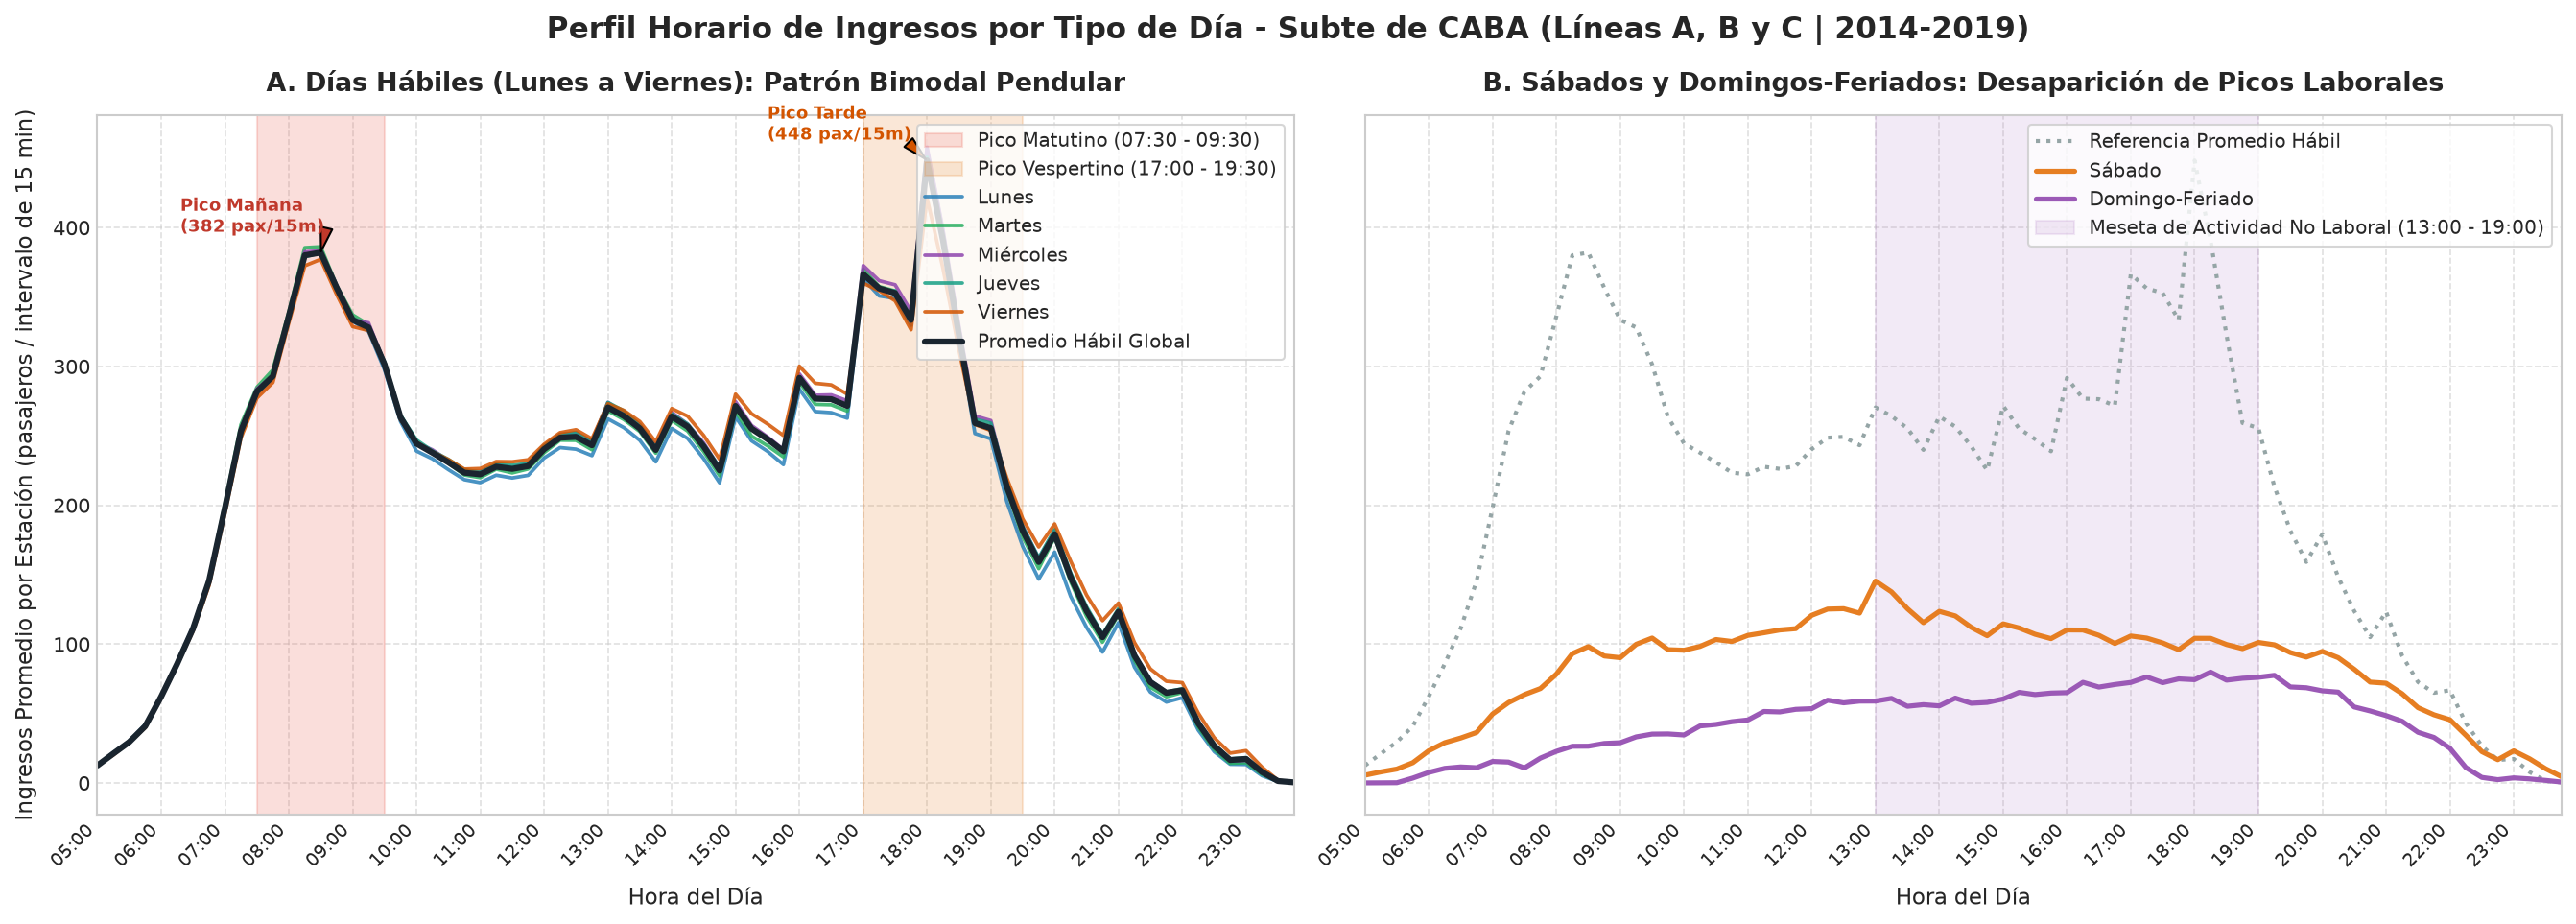

In [11]:
dias_habiles = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes']
line_colors = {'Línea A': '#009ee0', 'Línea B': '#e31b23', 'Línea C': '#005baa'}
TIPO_COLORS = {'Hábil': '#1f77b4', 'Sábado': '#e67e22', 'Domingo-Feriado': '#9b59b6'}
TIPO_ESTILOS = {'Hábil': '-', 'Sábado': '--', 'Domingo-Feriado': ':'}

hourly_day = df_service[df_service['tipo_dia'] == 'Hábil'].groupby(['dia_semana_nombre', 'hora_decimal'])['ingresos'].mean().reset_index()
hourly_tipo = df_service.groupby(['tipo_dia', 'hora_decimal'])['ingresos'].mean().reset_index()
hourly_habil_mean = df_service[df_service['tipo_dia'] == 'Hábil'].groupby('hora_decimal')['ingresos'].mean().reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), sharey=True)

# --- PANEL A: DÍAS HÁBILES ---
ax1.axvspan(7.5, 9.5, color='#e74c3c', alpha=0.18, label='Pico Matutino (07:30 - 09:30)')
ax1.axvspan(17.0, 19.5, color='#e67e22', alpha=0.18, label='Pico Vespertino (17:00 - 19:30)')

habiles_colors = {'Lunes': '#2980b9', 'Martes': '#27ae60', 'Miércoles': '#8e44ad', 'Jueves': '#16a085', 'Viernes': '#d35400'}
for d in dias_habiles:
    sub = hourly_day[hourly_day['dia_semana_nombre'] == d].sort_values(by='hora_decimal')
    ax1.plot(sub['hora_decimal'], sub['ingresos'], label=d, color=habiles_colors[d], linewidth=1.8, alpha=0.85)

ax1.plot(hourly_habil_mean['hora_decimal'], hourly_habil_mean['ingresos'],
         label='Promedio Hábil Global', color='#1a252f', linewidth=3.0, linestyle='-')

ax1.set_title('A. Días Hábiles (Lunes a Viernes): Patrón Bimodal Pendular', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Hora del Día', fontsize=11, labelpad=8)
ax1.set_ylabel('Ingresos Promedio por Estación (pasajeros / intervalo de 15 min)', fontsize=11, labelpad=8)
ax1.set_xlim(5.0, 23.75)
hours_ticks = np.arange(5, 24, 1)
hours_labels = [f'{int(h):02d}:00' for h in hours_ticks]
ax1.set_xticks(hours_ticks)
ax1.set_xticklabels(hours_labels, rotation=45, ha='right', fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, fontsize=9.5)

# Anotaciones de picos
peak_mat = hourly_habil_mean[(hourly_habil_mean['hora_decimal'] >= 7.5) & (hourly_habil_mean['hora_decimal'] <= 9.5)].sort_values(by='ingresos', ascending=False).iloc[0]
peak_vesp = hourly_habil_mean[(hourly_habil_mean['hora_decimal'] >= 17.0) & (hourly_habil_mean['hora_decimal'] <= 19.5)].sort_values(by='ingresos', ascending=False).iloc[0]
ax1.annotate(f'Pico Mañana\n({peak_mat["ingresos"]:.0f} pax/15m)',
             xy=(peak_mat['hora_decimal'], peak_mat['ingresos']),
             xytext=(peak_mat['hora_decimal'] - 2.2, peak_mat['ingresos'] + 15),
             arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=6),
             fontsize=8.5, fontweight='bold', color='#c0392b')
ax1.annotate(f'Pico Tarde\n({peak_vesp["ingresos"]:.0f} pax/15m)',
             xy=(peak_vesp['hora_decimal'], peak_vesp['ingresos']),
             xytext=(peak_vesp['hora_decimal'] - 2.5, peak_vesp['ingresos'] + 15),
             arrowprops=dict(facecolor='#d35400', shrink=0.08, width=1.5, headwidth=6),
             fontsize=8.5, fontweight='bold', color='#d35400')

# --- PANEL B: SÁBADOS Y DOMINGOS-FERIADOS VS HÁBIL ---
ax2.plot(hourly_habil_mean['hora_decimal'], hourly_habil_mean['ingresos'],
         label='Referencia Promedio Hábil', color='#95a5a6', linewidth=2.0, linestyle=':')
for t in NO_LABORABLES:
    sub_t = hourly_tipo[hourly_tipo['tipo_dia'] == t].sort_values(by='hora_decimal')
    ax2.plot(sub_t['hora_decimal'], sub_t['ingresos'], label=t, color=TIPO_COLORS[t], linewidth=2.5)
ax2.axvspan(13.0, 19.0, color='#9b59b6', alpha=0.12, label='Meseta de Actividad No Laboral (13:00 - 19:00)')

ax2.set_title('B. Sábados y Domingos-Feriados: Desaparición de Picos Laborales', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Hora del Día', fontsize=11, labelpad=8)
ax2.set_xlim(5.0, 23.75)
ax2.set_xticks(hours_ticks)
ax2.set_xticklabels(hours_labels, rotation=45, ha='right', fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.suptitle('Perfil Horario de Ingresos por Tipo de Día - Subte de CABA (Líneas A, B y C | 2014-2019)',
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
guardar_figura('01_curva_demanda_dia_semana.png', bbox_inches='tight')

### 4.2. Curvas de Demanda por Mes (Estacionalidad Anual)
Comportamiento del promedio diario de ingresos por estación a lo largo de los doce meses del año, por línea y, para la red consolidada, por tipo de día.

Gráfico guardado: output/graficos/02_curva_demanda_estacional_mes.png


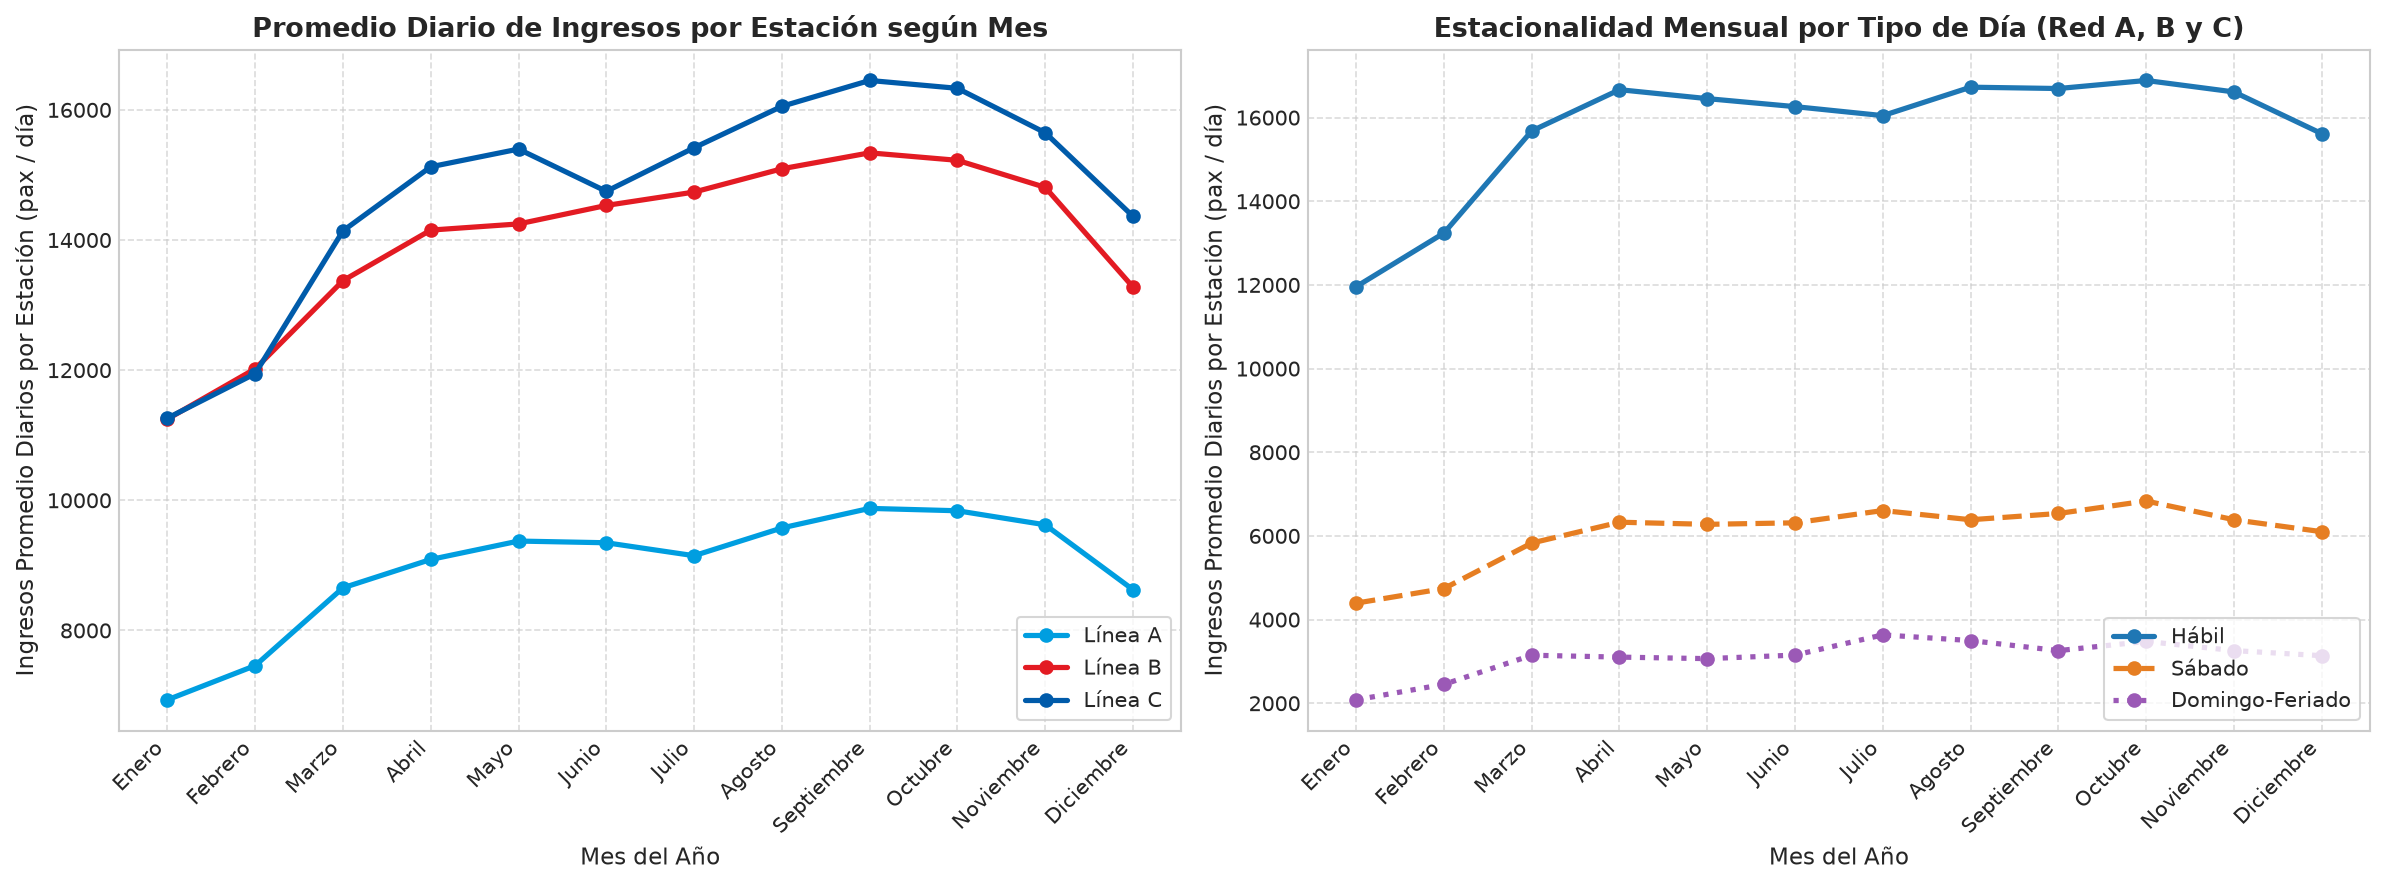

In [12]:
meses_orden = list(MESES_MAP.values())
monthly_line = df_diario.groupby(['mes', 'mes_nombre', 'linea'])['ingresos'].mean().reset_index()
monthly_line['mes_idx'] = monthly_line['mes'] - 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Izquierda: por línea
for l in sorted(monthly_line['linea'].unique()):
    sub = monthly_line[monthly_line['linea'] == l].sort_values(by='mes')
    ax1.plot(sub['mes_idx'], sub['ingresos'], marker='o', linewidth=2.5, label=l, color=line_colors.get(l, None))

ax1.set_title('Promedio Diario de Ingresos por Estación según Mes', fontsize=13, fontweight='bold')
ax1.set_xlabel('Mes del Año', fontsize=11)
ax1.set_ylabel('Ingresos Promedio Diarios por Estación (pax / día)', fontsize=11)
ax1.set_xticks(range(12))
ax1.set_xticklabels(meses_orden, rotation=45, ha='right')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(loc='lower right', frameon=True)

# Derecha: red consolidada por tipo de día
monthly_tipo = df_diario.groupby(['mes', 'tipo_dia'])['ingresos'].mean().reset_index()
for t in TIPOS_DIA:
    sub = monthly_tipo[monthly_tipo['tipo_dia'] == t].sort_values(by='mes')
    ax2.plot(sub['mes'] - 1, sub['ingresos'], marker='o', linewidth=2.5, label=t,
             color=TIPO_COLORS[t], linestyle=TIPO_ESTILOS[t])
ax2.set_title('Estacionalidad Mensual por Tipo de Día (Red A, B y C)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Mes del Año', fontsize=11)
ax2.set_ylabel('Ingresos Promedio Diarios por Estación (pax / día)', fontsize=11)
ax2.set_xticks(range(12))
ax2.set_xticklabels(meses_orden, rotation=45, ha='right')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
guardar_figura('02_curva_demanda_estacional_mes.png')

### 4.3. Perfil Horario Desagregado por Línea y Tipo de Día
Perfil promedio de ingresos por estación en intervalos de 15 minutos, de forma independiente para cada línea.

Gráfico guardado: output/graficos/03_perfil_horario_por_linea.png


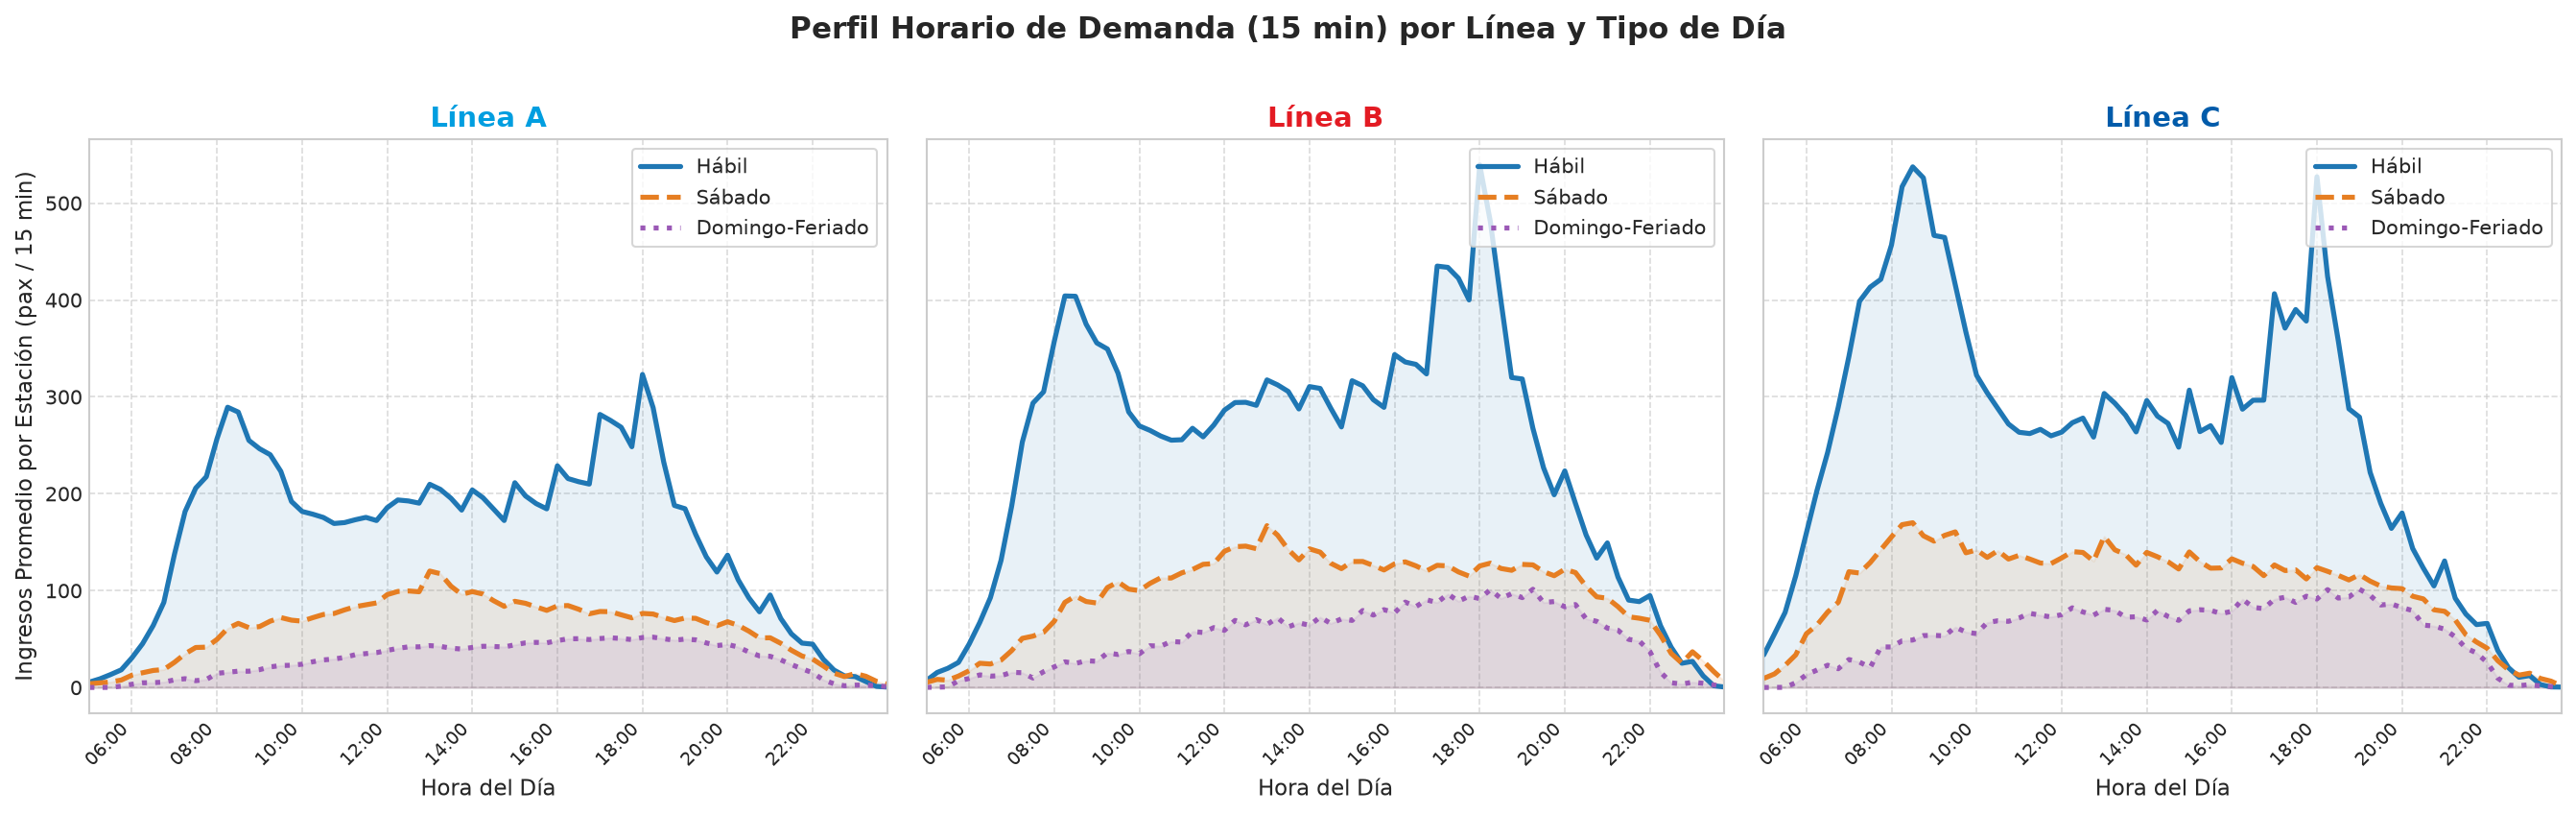

In [13]:
hourly_line_type = df_service.groupby(['linea', 'tipo_dia', 'hora_decimal'])['ingresos'].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for i, l in enumerate(['Línea A', 'Línea B', 'Línea C']):
    ax = axes[i]
    for t in TIPOS_DIA:
        sub = hourly_line_type[(hourly_line_type['linea'] == l) & (hourly_line_type['tipo_dia'] == t)].sort_values(by='hora_decimal')
        ax.plot(sub['hora_decimal'], sub['ingresos'], label=t, color=TIPO_COLORS[t], linewidth=2.5, linestyle=TIPO_ESTILOS[t])
        ax.fill_between(sub['hora_decimal'], sub['ingresos'], alpha=0.10, color=TIPO_COLORS[t])

    ax.set_title(f'{l}', fontsize=14, fontweight='bold', color=line_colors.get(l, 'black'))
    ax.set_xlabel('Hora del Día', fontsize=11)
    if i == 0:
        ax.set_ylabel('Ingresos Promedio por Estación (pax / 15 min)', fontsize=11)
    ax.set_xlim(5.0, 23.75)
    step_ticks = np.arange(6, 24, 2)
    ax.set_xticks(step_ticks)
    ax.set_xticklabels([f'{int(h):02d}:00' for h in step_ticks], rotation=45, ha='right', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper right', frameon=True)

plt.suptitle('Perfil Horario de Demanda (15 min) por Línea y Tipo de Día', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
guardar_figura('03_perfil_horario_por_linea.png', bbox_inches='tight')

### 4.4. Comparativa por Tipo de Día en Estaciones Representativas
Una estación por cada grupo identificado al comparar la distribución horaria (DM-04): origen residencial (San Pedrito, cabecera de la Línea A), centro financiero (Florida, Línea B), transbordo intermodal (Constitución, cabecera de la Línea C) y polo recreativo (Carlos Gardel, Línea B).

Gráfico guardado: output/graficos/04_comparativa_habil_nolab_estaciones_clave.png


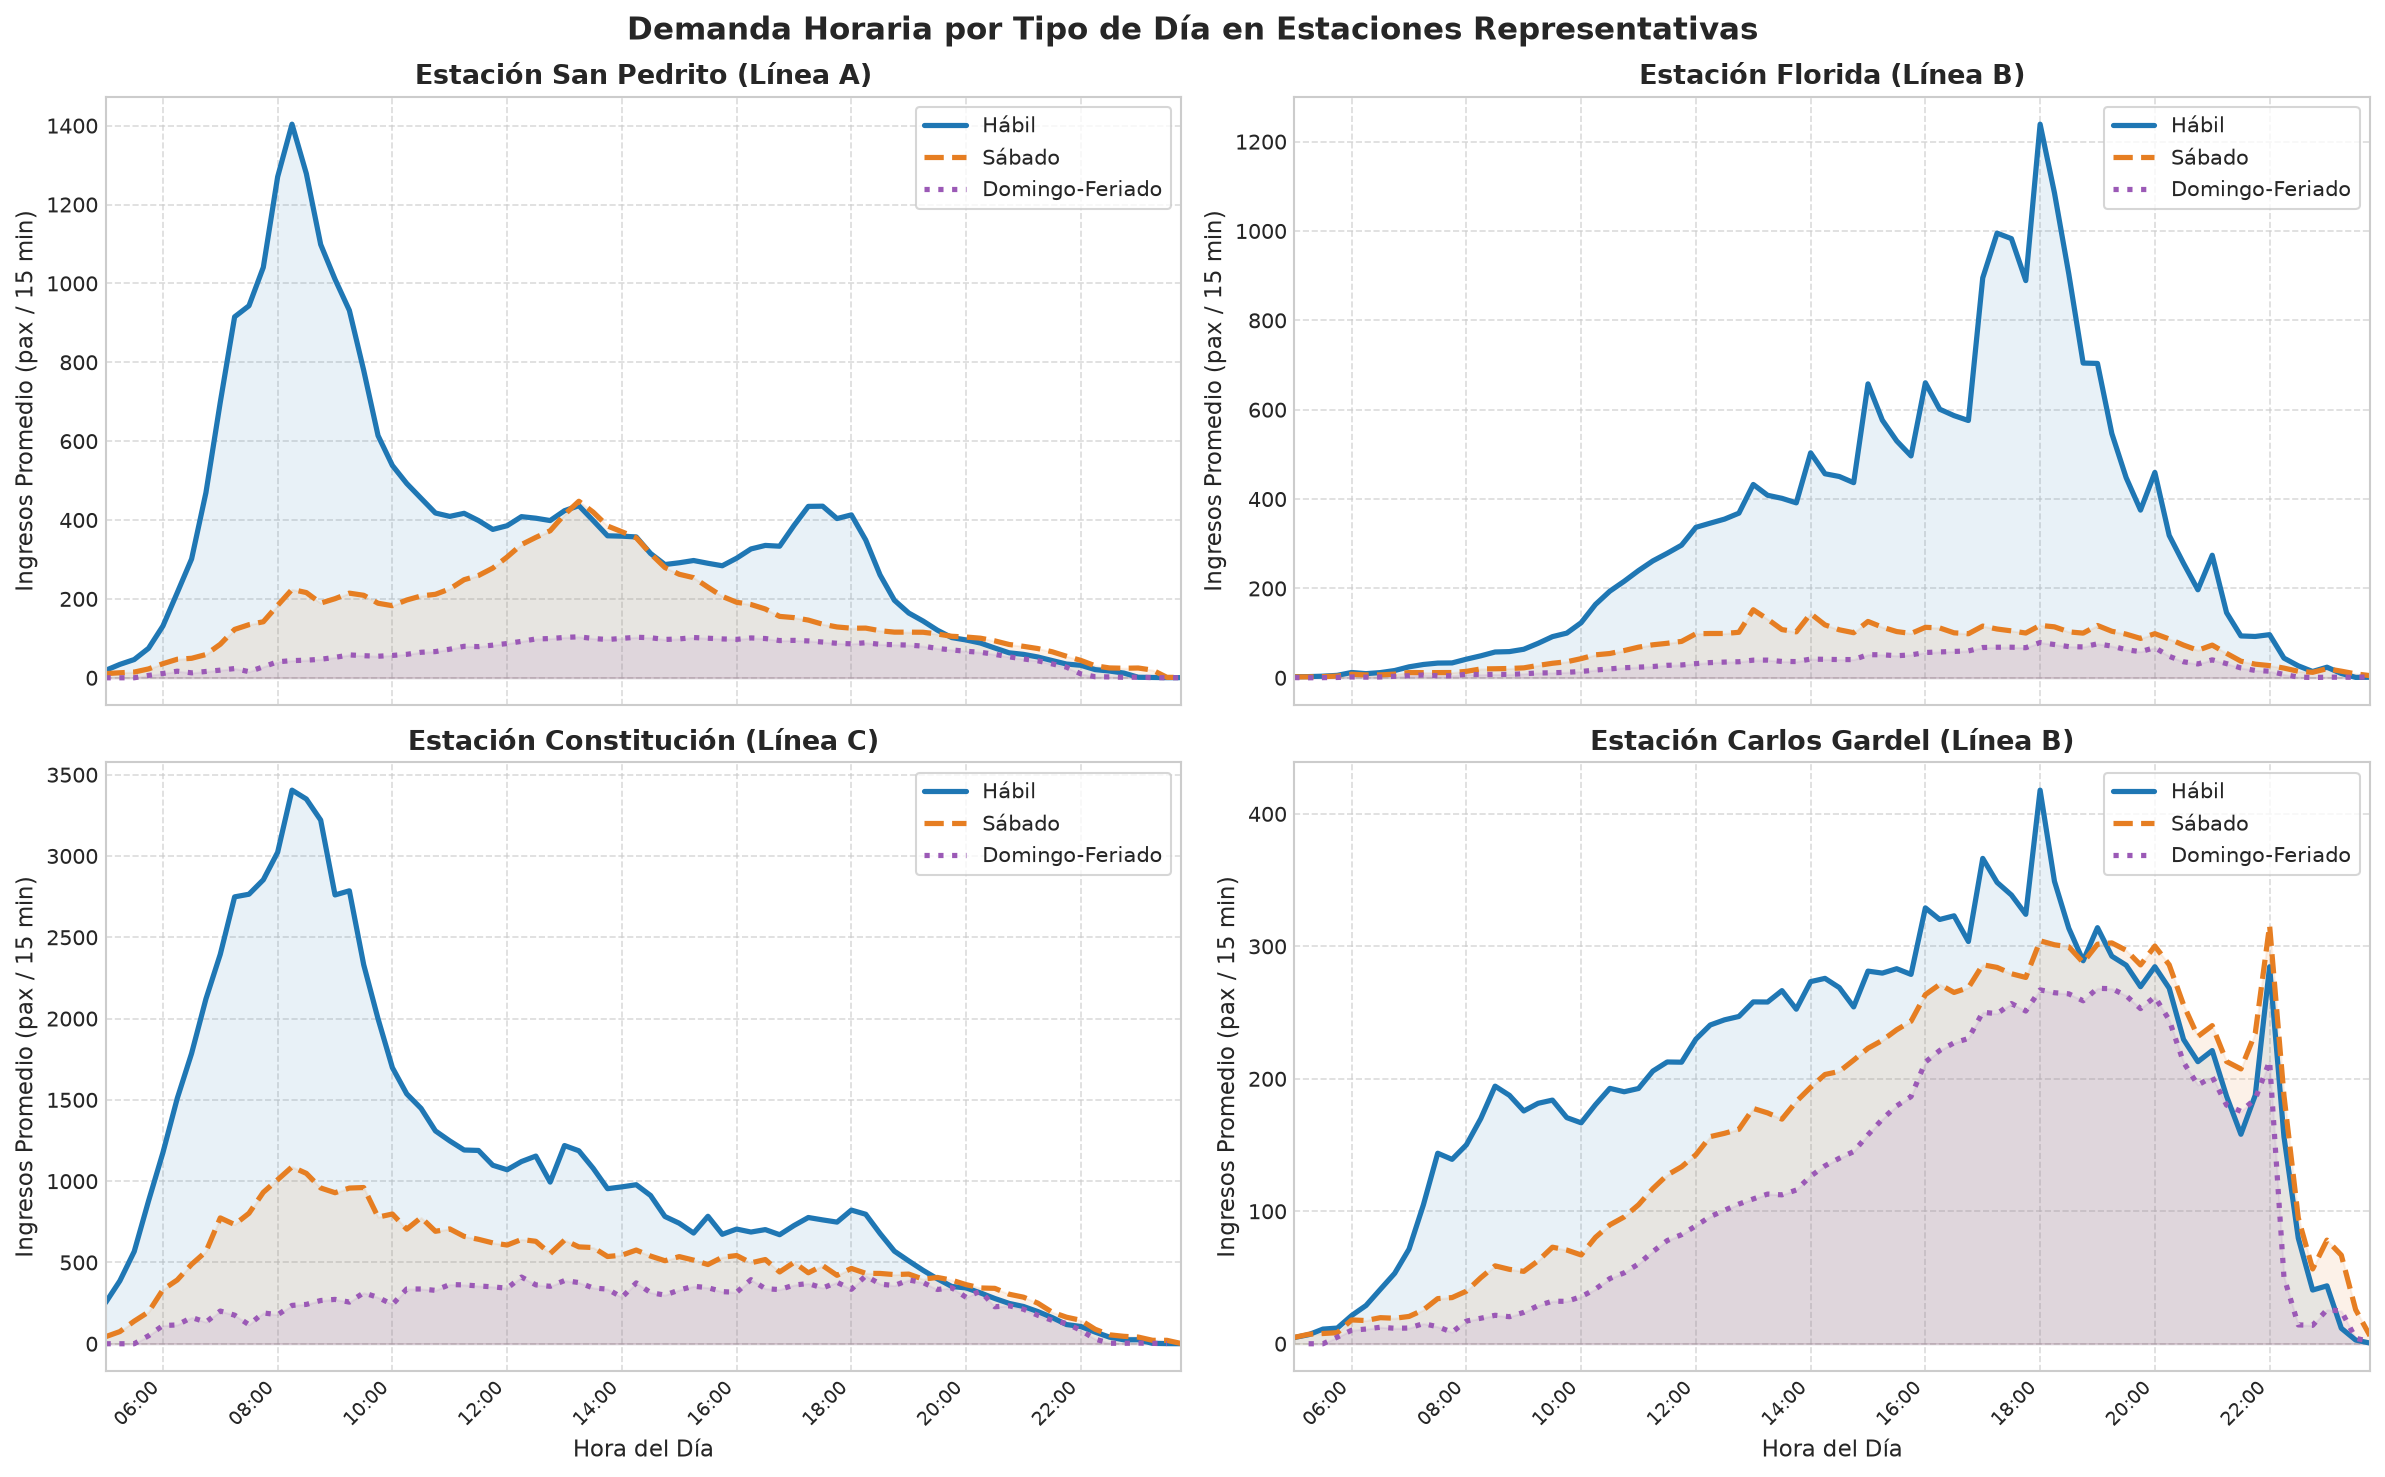

In [14]:
# Una estación por grupo: origen residencial, centro financiero, transbordo intermodal, polo recreativo (DM-04)
ESTACIONES_REPRESENTATIVAS = ['San Pedrito', 'Florida', 'Constitución', 'Carlos Gardel']
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for i, est in enumerate(ESTACIONES_REPRESENTATIVAS):
    ax = axes[i]
    sub = df_service[df_service['estacion'] == est]
    st_agg = sub.groupby(['tipo_dia', 'hora_decimal'])['ingresos'].mean().reset_index()
    for t in TIPOS_DIA:
        st_t = st_agg[st_agg['tipo_dia'] == t].sort_values(by='hora_decimal')
        ax.plot(st_t['hora_decimal'], st_t['ingresos'], label=t, color=TIPO_COLORS[t], linewidth=2.5, linestyle=TIPO_ESTILOS[t])
        ax.fill_between(st_t['hora_decimal'], st_t['ingresos'], alpha=0.10, color=TIPO_COLORS[t])

    ax.set_title(f'Estación {est} ({sub["linea"].iloc[0]})', fontsize=13, fontweight='bold')
    ax.set_ylabel('Ingresos Promedio (pax / 15 min)', fontsize=11)
    ax.set_xlim(5.0, 23.75)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper right', frameon=True)
    if i >= 2:
        ax.set_xlabel('Hora del Día', fontsize=11)
        step_ticks = np.arange(6, 24, 2)
        ax.set_xticks(step_ticks)
        ax.set_xticklabels([f'{int(h):02d}:00' for h in step_ticks], rotation=45, ha='right', fontsize=9)

plt.suptitle('Demanda Horaria por Tipo de Día en Estaciones Representativas', fontsize=15, fontweight='bold')
plt.tight_layout()
guardar_figura('04_comparativa_habil_nolab_estaciones_clave.png')

## 5. Volumen: Ratios de Retención de Demanda
El Ratio de Retención mide la proporción de la demanda de los días hábiles que se mantiene en cada tipo de día no laborable $t$ (Sábado; Domingo-Feriado):
$$\text{Ratio de Retención}_t\,(\%) = \frac{\overline{\text{Ingresos Diarios}}_{t}}{\overline{\text{Ingresos Diarios}}_{\text{Hábil}}} \times 100$$

Se informa con un **intervalo de confianza al 95% por bootstrap**: se remuestrean fechas completas con reposición dentro de cada tipo de día (en los totales por línea y de red, todas las estaciones de una fecha se remuestrean juntas, porque comparten el calendario) y se toman los percentiles 2,5 y 97,5 de la retención recalculada. No se plantea un contraste de hipótesis sobre el volumen: que la demanda no laborable sea menor no está en discusión; lo relevante es su magnitud (DM-04).

### 5.1. Por Línea y Total de la Red

In [15]:
B_BOOT = 2000
rng_boot = np.random.default_rng(20261105)


def retencion_bootstrap(diario, B=B_BOOT, rng=rng_boot):
    # Retención observada e IC 95% por bootstrap de fechas completas dentro de cada tipo de día.
    por_fecha = diario.groupby(['tipo_dia', 'fecha'])['ingresos'].agg(['sum', 'count'])
    obs, boot = {}, {}
    for t in TIPOS_DIA:
        s = por_fecha.loc[t, 'sum'].to_numpy(float)
        n = por_fecha.loc[t, 'count'].to_numpy(float)
        idx = rng.integers(0, len(s), size=(B, len(s)))
        obs[t] = s.sum() / n.sum()
        boot[t] = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    res = {'Hábil': obs['Hábil']}
    for t in NO_LABORABLES:
        r = boot[t] / boot['Hábil'] * 100
        res[t] = obs[t]
        res[f'ret_{t}'] = obs[t] / obs['Hábil'] * 100
        res[f'ic_{t}'] = tuple(np.percentile(r, [2.5, 97.5]))
    return res


fmt_ic = lambda ic: f"[{ic[0]:.2f} – {ic[1]:.2f}]"

In [16]:
grupos = [(l, df_diario[df_diario['linea'] == l]) for l in sorted(df_diario['linea'].unique())]
grupos.append(('TOTAL RED (A, B, C)', df_diario))
ret_linea = pd.DataFrame({nombre: retencion_bootstrap(d) for nombre, d in grupos}).T

md_ret_linea = "# Ratios de Retención de Demanda por Línea y Tipo de Día\n\n"
md_ret_linea += "El Ratio de Retención mide la proporción de la demanda de los días hábiles que se mantiene en cada tipo de día no laborable (Sábado; Domingo-Feriado), sobre días con servicio:\n"
md_ret_linea += "$$\\text{Ratio de Retención}_t\\,(\\%) = \\frac{\\overline{\\text{Ingresos Diarios}}_{t}}{\\overline{\\text{Ingresos Diarios}}_{\\text{Hábil}}} \\times 100$$\n\n"
md_ret_linea += f"Entre corchetes, intervalo de confianza al 95% por bootstrap de fechas completas ({B_BOOT:,} remuestreos).\n\n"
md_ret_linea += "| Línea | Promedio Hábil (pax/estación) | Promedio Sábado (pax/estación) | Retención Sábado (%) | Promedio Domingo-Feriado (pax/estación) | Retención Domingo-Feriado (%) |\n"
md_ret_linea += "| :--- | :---: | :---: | :---: | :---: | :---: |\n"
for l, r in ret_linea.iterrows():
    b = '**' if l.startswith('TOTAL') else ''
    md_ret_linea += (f"| {b}{l}{b} | {b}{r['Hábil']:,.1f}{b} "
                     f"| {b}{r['Sábado']:,.1f}{b} | **{r['ret_Sábado']:.2f}** {fmt_ic(r['ic_Sábado'])} "
                     f"| {b}{r['Domingo-Feriado']:,.1f}{b} | **{r['ret_Domingo-Feriado']:.2f}** {fmt_ic(r['ic_Domingo-Feriado'])} |\n")

guardar_tabla('03_ratios_retencion_linea.md', md_ret_linea)

Tabla guardada: output/tablas/03_ratios_retencion_linea.md


# Ratios de Retención de Demanda por Línea y Tipo de Día

El Ratio de Retención mide la proporción de la demanda de los días hábiles que se mantiene en cada tipo de día no laborable (Sábado; Domingo-Feriado), sobre días con servicio:
$$\text{Ratio de Retención}_t\,(\%) = \frac{\overline{\text{Ingresos Diarios}}_{t}}{\overline{\text{Ingresos Diarios}}_{\text{Hábil}}} \times 100$$

Entre corchetes, intervalo de confianza al 95% por bootstrap de fechas completas (2,000 remuestreos).

| Línea | Promedio Hábil (pax/estación) | Promedio Sábado (pax/estación) | Retención Sábado (%) | Promedio Domingo-Feriado (pax/estación) | Retención Domingo-Feriado (%) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Línea A | 11,787.8 | 4,575.8 | **38.82** [37.82 – 39.88] | 2,141.0 | **18.16** [17.61 – 18.72] |
| Línea B | 18,116.1 | 6,740.1 | **37.21** [35.92 – 38.41] | 3,673.8 | **20.28** [19.64 – 20.92] |
| Línea C | 19,191.6 | 7,852.3 | **40.92** [39.79 – 42.01] | 4,133.2 | **21.54** [20.87 – 22.19] |
| **TOTAL RED (A, B, C)** | **15,746.2** | **6,076.0** | **38.59** [37.47 – 39.72] | **3,117.6** | **19.80** [19.20 – 20.37] |


La categoría *Domingo-Feriado* agrupa domingos y feriados nacionales (ver 2.2). Para verificar que ambos componentes tienen un nivel de demanda comparable, se desagrega su retención:

In [17]:
tipo_dia_detalle = np.where(df_diario['tipo_dia'] != 'Domingo-Feriado', df_diario['tipo_dia'],
                            np.where(df_diario['es_feriado'] == 1, 'Feriado', 'Domingo'))
ret_tipo_dia = (df_diario.groupby(tipo_dia_detalle)['ingresos'].mean()
                .reindex(['Hábil', 'Sábado', 'Domingo', 'Feriado'])
                .to_frame('promedio_diario_por_estacion'))
ret_tipo_dia['ratio_retencion_pct'] = ret_tipo_dia['promedio_diario_por_estacion'] / ret_tipo_dia.loc['Hábil', 'promedio_diario_por_estacion'] * 100
display(ret_tipo_dia.style.format({'promedio_diario_por_estacion': '{:,.1f}', 'ratio_retencion_pct': '{:.2f}%'}))

,promedio_diario_por_estacion,ratio_retencion_pct
Hábil,"15,746.2",100.00%
Sábado,"6,076.0",38.59%
Domingo,"2,986.0",18.96%
Feriado,"3,497.5",22.21%


### 5.2. Por Estación (Top 5 / Bottom 5 y Tabla Completa)

In [18]:
est_promedios = pd.DataFrame([
    {'linea': l, 'estacion': e, **retencion_bootstrap(d)}
    for (l, e), d in df_diario.groupby(['linea', 'estacion'])
])

md_ret_est = "# Ratios de Retención de Demanda por Estación y Tipo de Día (44 Estaciones)\n\n"
md_ret_est += f"Retención sobre días con servicio. Entre corchetes, intervalo de confianza al 95% por bootstrap de fechas ({B_BOOT:,} remuestreos).\n\n"
for t in NO_LABORABLES:
    orden = est_promedios.sort_values(by=f'ret_{t}', ascending=False)
    for titulo, sub in [(f"Top 5 Estaciones con Mayor Retención en {t}", orden.head(5)),
                        (f"Top 5 Estaciones con Menor Retención en {t}", orden.tail(5).iloc[::-1])]:
        md_ret_est += f"### {titulo}\n\n"
        md_ret_est += f"| Ranking | Estación | Línea | Promedio Hábil | Promedio {t} | Retención {t} (%) |\n"
        md_ret_est += "| :---: | :--- | :--- | :---: | :---: | :---: |\n"
        for k, (_, r) in enumerate(sub.iterrows(), 1):
            md_ret_est += (f"| {k} | **{r['estacion']}** | {r['linea']} | {r['Hábil']:,.1f} | {r[t]:,.1f} "
                           f"| **{r[f'ret_{t}']:.2f}** {fmt_ic(r[f'ic_{t}'])} |\n")
        md_ret_est += "\n"

md_ret_est += "### Tabla Completa de las 44 Estaciones (ordenada por retención en Domingo-Feriado)\n\n"
md_ret_est += "| # | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |\n"
md_ret_est += "| :---: | :--- | :--- | :---: | :---: | :---: | :---: | :---: |\n"
for k, (_, r) in enumerate(est_promedios.sort_values(by='ret_Domingo-Feriado', ascending=False).iterrows(), 1):
    md_ret_est += (f"| {k} | {r['estacion']} | {r['linea']} | {r['Hábil']:,.1f} "
                   f"| {r['Sábado']:,.1f} | {r['ret_Sábado']:.2f} {fmt_ic(r['ic_Sábado'])} "
                   f"| {r['Domingo-Feriado']:,.1f} | {r['ret_Domingo-Feriado']:.2f} {fmt_ic(r['ic_Domingo-Feriado'])} |\n")

guardar_tabla('04_ratios_retencion_top_bottom_estaciones.md', md_ret_est)

Tabla guardada: output/tablas/04_ratios_retencion_top_bottom_estaciones.md


# Ratios de Retención de Demanda por Estación y Tipo de Día (44 Estaciones)

Retención sobre días con servicio. Entre corchetes, intervalo de confianza al 95% por bootstrap de fechas (2,000 remuestreos).

### Top 5 Estaciones con Mayor Retención en Sábado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Carlos Gardel** | Línea B | 15,047.3 | 10,862.2 | **72.19** [69.09 – 75.30] |
| 2 | **Alberti** | Línea A | 4,748.8 | 2,569.3 | **54.10** [52.62 – 55.65] |
| 3 | **Plaza Miserere** | Línea A | 14,538.4 | 7,705.7 | **53.00** [51.75 – 54.31] |
| 4 | **Pueyrredón** | Línea B | 13,937.5 | 7,089.5 | **50.87** [49.13 – 52.54] |
| 5 | **Independencia** | Línea C | 6,285.7 | 2,970.3 | **47.25** [45.72 – 48.90] |

### Top 5 Estaciones con Menor Retención en Sábado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Plaza de Mayo** | Línea A | 20,969.7 | 3,872.8 | **18.47** [17.96 – 18.99] |
| 2 | **Diagonal Norte** | Línea C | 6,989.0 | 1,310.9 | **18.76** [18.19 – 19.34] |
| 3 | **Florida** | Línea B | 23,570.5 | 4,590.0 | **19.47** [18.71 – 20.23] |
| 4 | **Moreno** | Línea C | 8,201.3 | 1,693.3 | **20.65** [20.02 – 21.31] |
| 5 | **Piedras** | Línea A | 8,286.4 | 1,846.8 | **22.29** [21.33 – 23.34] |

### Top 5 Estaciones con Mayor Retención en Domingo-Feriado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Carlos Gardel** | Línea B | 15,047.3 | 8,355.7 | **55.53** [53.45 – 57.66] |
| 2 | **Independencia** | Línea C | 6,285.7 | 1,984.9 | **31.58** [30.57 – 32.60] |
| 3 | **Retiro** | Línea C | 38,894.1 | 10,899.6 | **28.02** [27.30 – 28.79] |
| 4 | **Carlos Pellegrini** | Línea B | 22,673.4 | 5,966.7 | **26.32** [25.25 – 27.35] |
| 5 | **Loria** | Línea A | 7,735.9 | 1,922.4 | **24.85** [24.08 – 25.61] |

### Top 5 Estaciones con Menor Retención en Domingo-Feriado

| Ranking | Estación | Línea | Promedio Hábil | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: |
| 1 | **Diagonal Norte** | Línea C | 6,989.0 | 641.7 | **9.18** [8.69 – 9.73] |
| 2 | **Florida** | Línea B | 23,570.5 | 2,173.3 | **9.22** [8.72 – 9.71] |
| 3 | **Piedras** | Línea A | 8,286.4 | 885.3 | **10.68** [10.05 – 11.36] |
| 4 | **Moreno** | Línea C | 8,201.3 | 920.5 | **11.22** [10.72 – 11.74] |
| 5 | **Plaza de Mayo** | Línea A | 20,969.7 | 2,390.1 | **11.40** [11.03 – 11.80] |

### Tabla Completa de las 44 Estaciones (ordenada por retención en Domingo-Feriado)

| # | Estación | Línea | Promedio Hábil | Promedio Sábado | Retención Sábado (%) | Promedio Domingo-Feriado | Retención Domingo-Feriado (%) |
| :---: | :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| 1 | Carlos Gardel | Línea B | 15,047.3 | 10,862.2 | 72.19 [69.09 – 75.30] | 8,355.7 | 55.53 [53.45 – 57.66] |
| 2 | Independencia | Línea C | 6,285.7 | 2,970.3 | 47.25 [45.72 – 48.90] | 1,984.9 | 31.58 [30.57 – 32.60] |
| 3 | Retiro | Línea C | 38,894.1 | 18,283.8 | 47.01 [45.96 – 48.00] | 10,899.6 | 28.02 [27.30 – 28.79] |
| 4 | Carlos Pellegrini | Línea B | 22,673.4 | 9,289.0 | 40.97 [39.24 – 42.73] | 5,966.7 | 26.32 [25.25 – 27.35] |
| 5 | Loria | Línea A | 7,735.9 | 3,618.9 | 46.78 [45.36 – 48.19] | 1,922.4 | 24.85 [24.08 – 25.61] |
| 6 | Ángel Gallardo | Línea B | 15,982.5 | 6,522.5 | 40.81 [39.24 – 42.31] | 3,856.7 | 24.13 [23.33 – 24.92] |
| 7 | Medrano | Línea B | 18,126.8 | 7,681.1 | 42.37 [40.69 – 43.91] | 4,234.9 | 23.36 [22.59 – 24.15] |
| 8 | Plaza Miserere | Línea A | 14,538.4 | 7,705.7 | 53.00 [51.75 – 54.31] | 3,393.5 | 23.34 [22.57 – 24.09] |
| 9 | Alberti | Línea A | 4,748.8 | 2,569.3 | 54.10 [52.62 – 55.65] | 1,094.9 | 23.06 [22.25 – 23.92] |
| 10 | Acoyte | Línea A | 14,315.4 | 6,641.0 | 46.39 [45.22 – 47.59] | 3,286.7 | 22.96 [22.23 – 23.66] |
| 11 | Constitución | Línea C | 79,675.9 | 37,298.3 | 46.81 [45.39 – 48.27] | 17,850.8 | 22.40 [21.58 – 23.20] |
| 12 | Castro Barros | Línea A | 9,423.4 | 4,348.9 | 46.15 [44.97 – 47.40] | 2,103.4 | 22.32 [21.66 – 23.04] |
| 13 | Río de Janeiro | Línea A | 10,569.6 | 4,735.4 | 44.80 [43.57 – 46.12] | 2,303.2 | 21.79 [21.11 – 22.52] |
| 14 | Dorrego | Línea B | 13,672.8 | 5,515.2 | 40.34 [38.87 – 41.80] | 2,867.1 | 20.97 [20.25 – 21.68] |
| 15 | San Juan | Línea C | 6,318.2 | 2,458.2 | 38.91 [37.56 – 40.39] | 1,309.9 | 20.73 [20.02 – 21.47] |
| 16 | Malabia | Línea B | 20,617.3 | 8,406.4 | 40.77 [39.18 – 42.35] | 4,265.1 | 20.69 [19.99 – 21.39] |
| 17 | Echeverría | Línea B | 7,255.3 | 2,543.1 | 35.05 [33.77 – 36.29] | 1,448.2 | 19.96 [19.38 – 20.59] |
| 18 | Primera Junta | Línea A | 13,111.3 | 5,685.3 | 43.36 [42.18 – 44.54] | 2,615.1 | 19.95 [19.34 – 20.60] |
| 19 | San José de Flores | Línea A | 11,734.3 | 4,996.4 | 42.58 [41.36 – 43.78] | 2,298.6 | 19.59 [18.97 – 20.22] |
| 20 | Congreso | Línea A | 13,918.2 | 5,481.8 | 39.39 [38.30 – 40.53] | 2,723.7 | 19.57 [18.95 – 20.16] |
| 21 | Pasco | Línea A | 3,805.7 | 1,516.7 | 39.85 [38.84 – 40.89] | 737.3 | 19.37 [18.72 – 20.07] |
| 22 | Federico Lacroze | Línea B | 30,368.0 | 11,850.6 | 39.02 [37.55 – 40.56] | 5,878.6 | 19.36 [18.51 – 20.19] |
| 23 | Lima | Línea A | 8,251.2 | 2,935.0 | 35.57 [34.38 – 36.83] | 1,594.5 | 19.32 [18.52 – 20.20] |
| 24 | De los Incas | Línea B | 11,547.2 | 4,119.6 | 35.68 [34.57 – 36.77] | 2,212.3 | 19.16 [18.56 – 19.74] |
| 25 | Carabobo | Línea A | 11,631.5 | 4,875.1 | 41.91 [40.86 – 42.91] | 2,222.6 | 19.11 [18.48 – 19.71] |
| 26 | Juan Manuel de Rosas | Línea B | 28,064.8 | 10,247.2 | 36.51 [35.11 – 37.88] | 5,290.3 | 18.85 [18.17 – 19.56] |
| 27 | Avenida de Mayo | Línea C | 6,539.0 | 2,041.0 | 31.21 [29.91 – 32.76] | 1,195.2 | 18.28 [17.50 – 19.16] |
| 28 | Callao (B) | Línea B | 19,752.5 | 6,875.0 | 34.81 [33.51 – 36.14] | 3,524.3 | 17.84 [17.19 – 18.50] |
| 29 | Puán | Línea A | 7,257.8 | 2,824.1 | 38.91 [37.64 – 40.09] | 1,282.2 | 17.67 [17.10 – 18.28] |
| 30 | Leandro N. Alem | Línea B | 28,061.9 | 6,938.2 | 24.72 [23.82 – 25.71] | 4,684.5 | 16.69 [16.12 – 17.28] |
| 31 | Pueyrredón | Línea B | 13,937.5 | 7,089.5 | 50.87 [49.13 – 52.54] | 2,302.4 | 16.52 [15.75 – 17.35] |
| 32 | Tronador | Línea B | 6,208.7 | 2,016.3 | 32.48 [31.22 – 33.70] | 1,000.0 | 16.11 [15.54 – 16.68] |
| 33 | San Pedrito | Línea A | 27,623.0 | 12,385.9 | 44.84 [43.26 – 46.49] | 4,375.7 | 15.84 [15.18 – 16.52] |
| 34 | Sáenz Peña | Línea A | 9,897.5 | 2,816.5 | 28.46 [27.65 – 29.26] | 1,400.7 | 14.15 [13.70 – 14.65] |
| 35 | Pasteur | Línea B | 14,279.3 | 5,575.5 | 39.05 [37.67 – 40.48] | 1,923.4 | 13.47 [12.95 – 14.03] |
| 36 | General San Martín | Línea C | 10,671.6 | 2,679.5 | 25.11 [24.21 – 26.12] | 1,426.1 | 13.36 [12.80 – 13.95] |
| 37 | Lavalle | Línea C | 10,981.7 | 2,992.5 | 27.25 [26.46 – 27.97] | 1,419.4 | 12.93 [12.44 – 13.40] |
| 38 | Perú | Línea A | 15,100.6 | 3,447.3 | 22.83 [21.93 – 23.75] | 1,932.8 | 12.80 [12.18 – 13.44] |
| 39 | Uruguay | Línea B | 18,819.7 | 4,389.9 | 23.33 [22.34 – 24.27] | 2,283.2 | 12.13 [11.62 – 12.63] |
| 40 | Plaza de Mayo | Línea A | 20,969.7 | 3,872.8 | 18.47 [17.96 – 18.99] | 2,390.1 | 11.40 [11.03 – 11.80] |
| 41 | Moreno | Línea C | 8,201.3 | 1,693.3 | 20.65 [20.02 – 21.31] | 920.5 | 11.22 [10.72 – 11.74] |
| 42 | Piedras | Línea A | 8,286.4 | 1,846.8 | 22.29 [21.33 – 23.34] | 885.3 | 10.68 [10.05 – 11.36] |
| 43 | Florida | Línea B | 23,570.5 | 4,590.0 | 19.47 [18.71 – 20.23] | 2,173.3 | 9.22 [8.72 – 9.71] |
| 44 | Diagonal Norte | Línea C | 6,989.0 | 1,310.9 | 18.76 [18.19 – 19.34] | 641.7 | 9.18 [8.69 – 9.73] |


### 5.3. Retención por Estación con Intervalos de Confianza

Gráfico guardado: output/graficos/05_retencion_por_estacion_ic.png


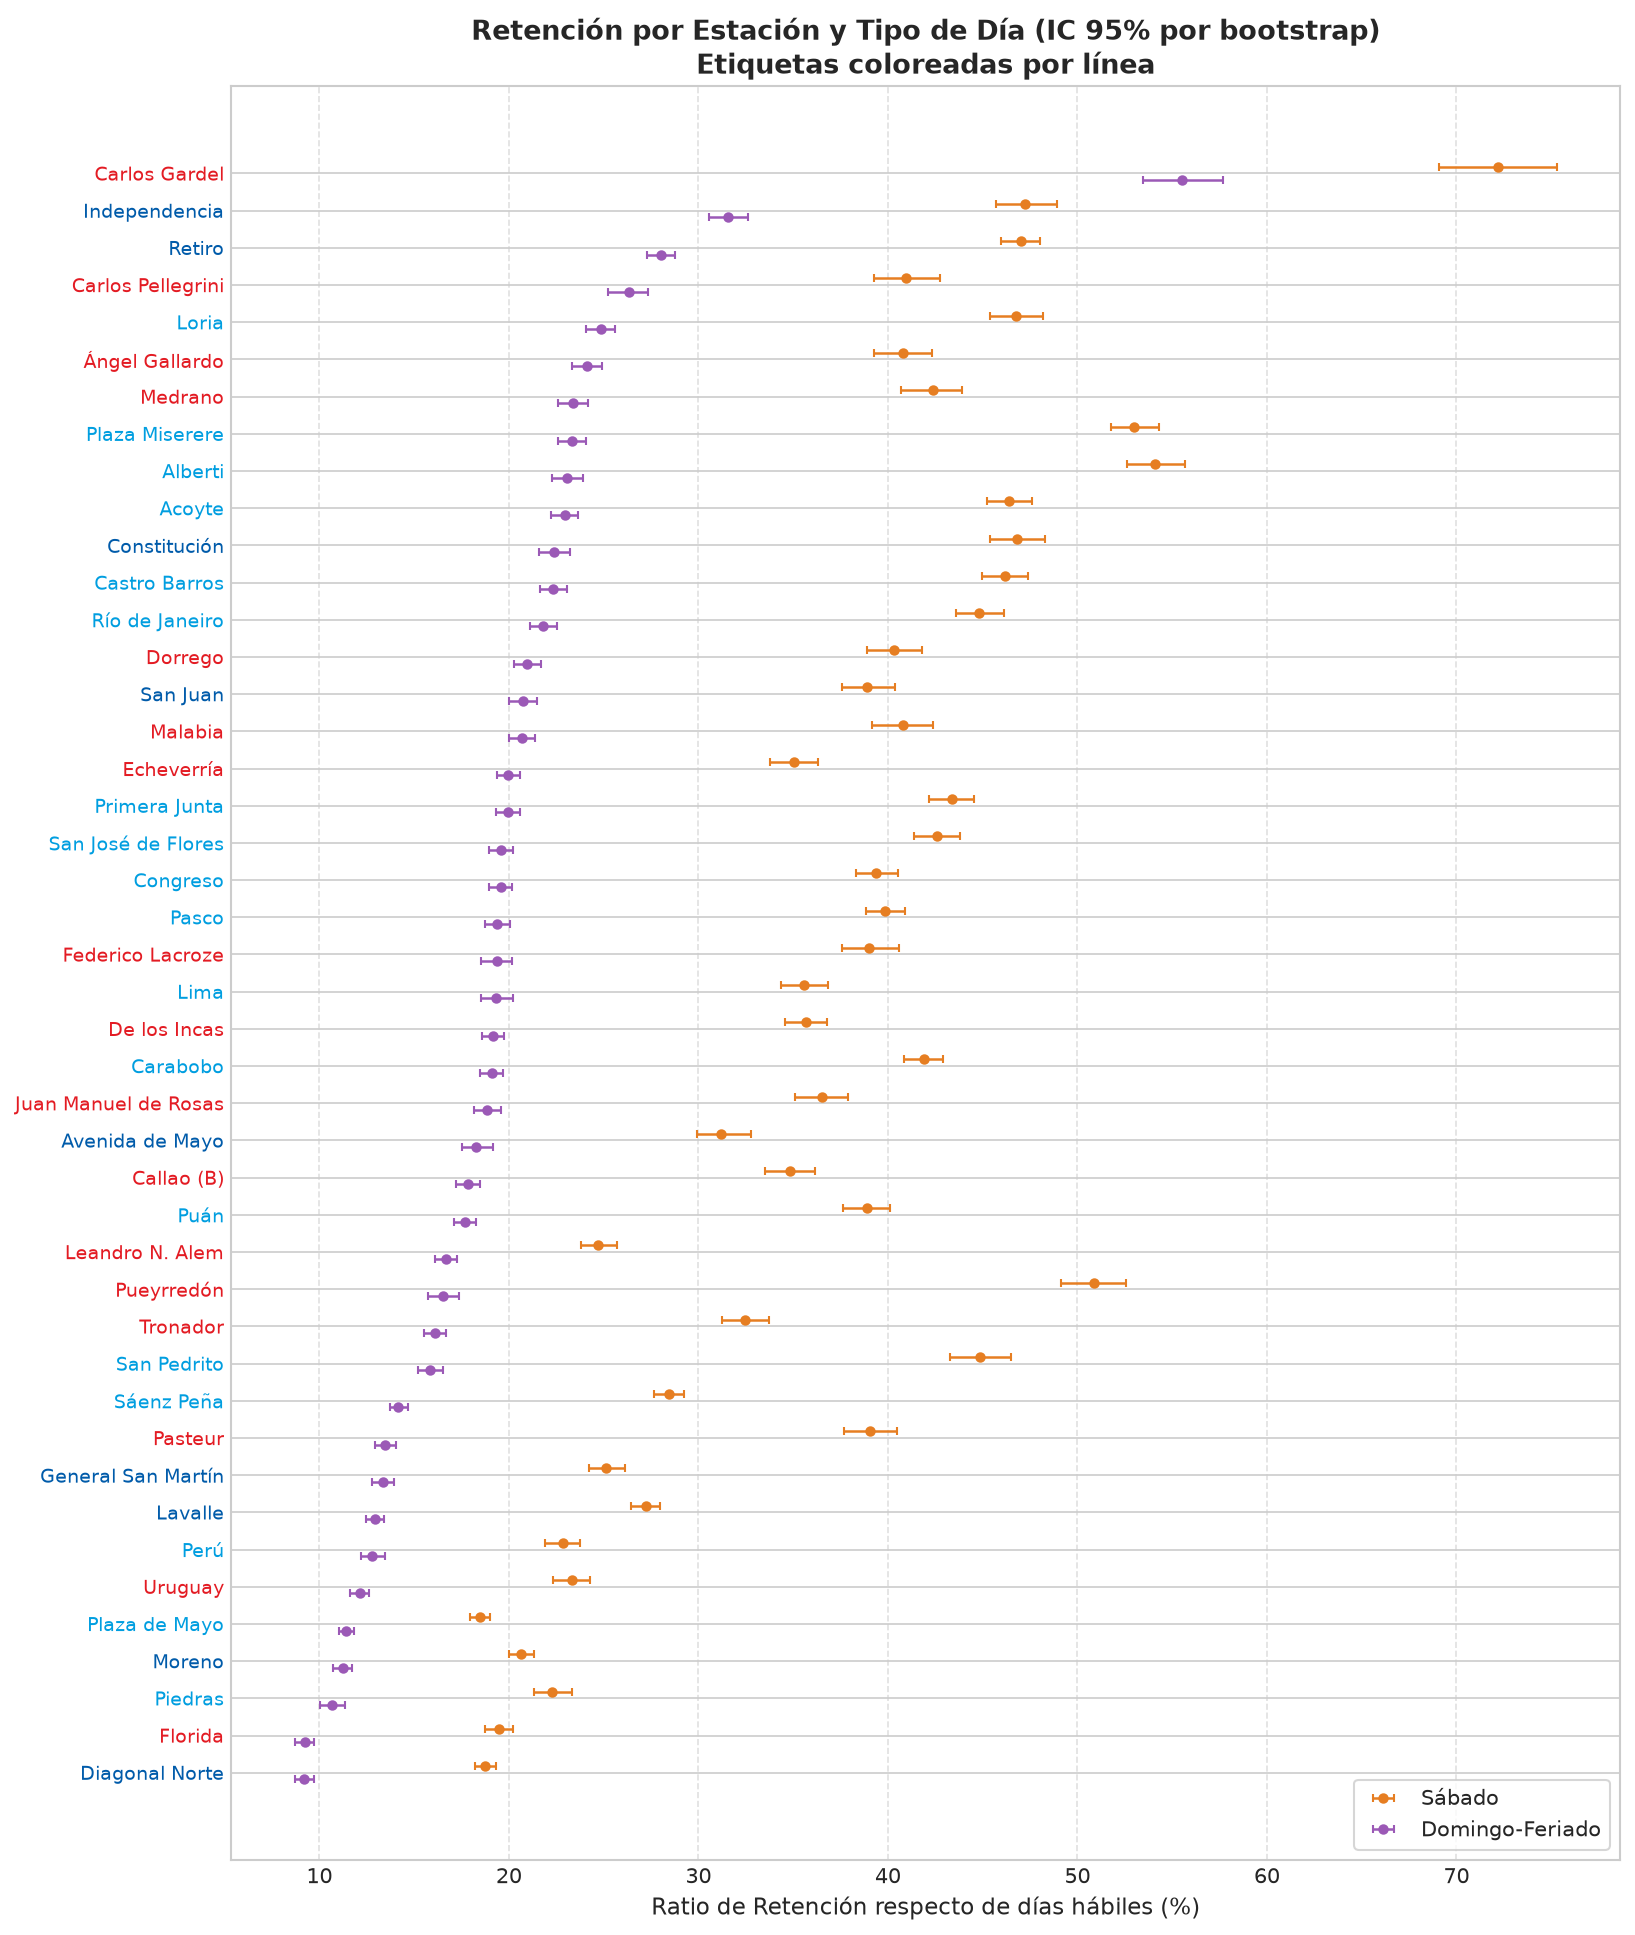

In [19]:
orden_est = est_promedios.sort_values(by='ret_Domingo-Feriado').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 13))
y = np.arange(len(orden_est))
for t, dy in [('Sábado', 0.18), ('Domingo-Feriado', -0.18)]:
    ic = np.array(orden_est[f'ic_{t}'].tolist())
    ret = orden_est[f'ret_{t}'].to_numpy()
    ax.errorbar(ret, y + dy, xerr=[ret - ic[:, 0], ic[:, 1] - ret], fmt='o', markersize=4,
                color=TIPO_COLORS[t], ecolor=TIPO_COLORS[t], elinewidth=1.2, capsize=2, label=t)
ax.set_yticks(y)
ax.set_yticklabels(orden_est['estacion'], fontsize=9)
for etiqueta, l in zip(ax.get_yticklabels(), orden_est['linea']):
    etiqueta.set_color(line_colors[l])
ax.set_xlabel('Ratio de Retención respecto de días hábiles (%)', fontsize=11)
ax.set_title('Retención por Estación y Tipo de Día (IC 95% por bootstrap)\nEtiquetas coloreadas por línea',
             fontsize=13, fontweight='bold')
ax.grid(True, axis='x', linestyle='--', alpha=0.6)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
guardar_figura('05_retencion_por_estacion_ic.png', bbox_inches='tight')

## 6. Distribución Horaria de la Demanda y Contraste de la Hipótesis
La retención (sección 5) mide el **volumen**. Esta sección analiza la **forma**: cómo se reparte la demanda a lo largo del día, independientemente de su nivel (DM-04, DM-07).

### 6.1. Perfil Normalizado y Distancia de Variación Total
Cada día-estación se representa como su **perfil normalizado**: la proporción de los ingresos del día en cada una de las 96 ventanas de 15 minutos. Un día que fuera una versión escalada de otro tendría exactamente el mismo perfil. Para cada estación se promedian los perfiles de los días de cada tipo, con igual peso por día (perfiles $p$ y $q$), y se mide su diferencia con la **distancia de variación total**, comparando cada ventana sólo con la misma ventana del otro perfil:
$$TV = \tfrac{1}{2}\sum_{i=1}^{96} |p_i - q_i| \;=\; 1 - \sum_{i=1}^{96} \min(p_i, q_i)$$
$TV$ es la proporción de la demanda diaria **no compartida** entre ambos perfiles (0 = idénticos; 1 = sin superposición).

Comparaciones:
- **Hábil – Sábado** y **Hábil – Domingo-Feriado:** contrastan la hipótesis de heterogeneidad.
- **Sábado – Domingo-Feriado** y **Domingo – Feriado:** validan las categorías de tipo de día (DM-03).

In [20]:
VENTANAS = sorted(df_15min['ventana_15min'].unique())
cal_fechas = calendario(df_diario['fecha']).set_index('fecha')
cal_fechas['detalle'] = np.where(cal_fechas['tipo_dia'] != 'Domingo-Feriado', cal_fechas['tipo_dia'],
                                 np.where(cal_fechas['es_feriado'] == 1, 'Feriado', 'Domingo'))
cal_fechas['estrato_mes'] = cal_fechas.index.to_period('M').astype(str)
cal_fechas['estrato_trim'] = cal_fechas.index.to_period('Q').astype(str)

# Perfiles normalizados por día-estación (filas = fechas, columnas = 96 ventanas)
perfiles = {}
for est, s in df_15min.groupby('estacion'):
    M = (s.pivot_table(index='fecha', columns='ventana_15min', values='ingresos', aggfunc='sum', fill_value=0)
         .reindex(columns=VENTANAS, fill_value=0))
    X = M.to_numpy(dtype=np.float64)
    perfiles[est] = (M.index, X / X.sum(axis=1, keepdims=True))

# (grupo a, grupo b, columna de etiqueta, columna de estrato)
COMPARACIONES = [
    ('Hábil', 'Sábado', 'tipo_dia', 'estrato_mes'),
    ('Hábil', 'Domingo-Feriado', 'tipo_dia', 'estrato_mes'),
    ('Sábado', 'Domingo-Feriado', 'tipo_dia', 'estrato_mes'),
    ('Domingo', 'Feriado', 'detalle', 'estrato_trim'),   # pocos feriados por mes: estratos año-trimestre (DM-04)
]
etiqueta_cmp = lambda a, b: f"{a} – {b}"
linea_de = df_diario.drop_duplicates('estacion').set_index('estacion')['linea']
print(f"Perfiles construidos: {len(perfiles)} estaciones × {len(VENTANAS)} ventanas")

Perfiles construidos: 44 estaciones × 96 ventanas


### 6.2. Test de Permutación
Bajo $H_0$ (la distribución horaria es igual entre los dos tipos de día comparados), la etiqueta de tipo de día no aporta información sobre el perfil. Se reasignan al azar las etiquetas **entre días completos**, lo que conserva la dependencia entre las ventanas de un mismo día, y se recalcula $TV$. Para que la estacionalidad no comprometa la intercambiabilidad de los días, las etiquetas sólo se intercambian **dentro de cada año-mes** (año-trimestre en la comparación Domingo – Feriado, por la escasez de feriados).

- $B = 10.000$ permutaciones; $p = (1 + \#\{TV^{*} \geq TV_{obs}\}) / (B + 1)$.
- Corrección de **Holm** entre las 44 estaciones, para cada comparación (válida cualquiera sea la dependencia entre estaciones).
- Con miles de días por estación, diferencias pequeñas resultan significativas: el **resultado principal es el tamaño de efecto** ($TV$). El resumen de red se presenta como distribución de tamaños de efecto, no como recuento de rechazos, porque las estaciones comparten el calendario.
- En cada permutación se registra además la mayor diferencia absoluta entre ventanas; su percentil 95 define la banda simultánea de la sección 6.3.

In [21]:
B_PERM = 10_000
rng_perm = np.random.default_rng(20261106)


def test_permutacion(X, etiquetas, estratos, a, b, B=B_PERM, rng=rng_perm, lote=1000):
    # Test de permutación de TV entre los perfiles medios de los días 'a' y 'b',
    # permutando etiquetas de días completos dentro de cada estrato.
    m = np.isin(etiquetas, [a, b])
    Xs, es_a = X[m], (etiquetas[m] == a)
    codigos = pd.factorize(estratos[m])[0]
    na, nb = es_a.sum(), (~es_a).sum()
    total = Xs.sum(axis=0)
    dif_obs = Xs[~es_a].mean(axis=0) - Xs[es_a].mean(axis=0)          # exceso del grupo b sobre a
    tv_obs = 0.5 * np.abs(dif_obs).sum()

    base = np.argsort(codigos, kind='stable')                          # posiciones agrupadas por estrato
    clave_estrato = codigos[base].astype(np.float64)
    a_ordenado = es_a[base]
    tv_null, max_null = np.empty(B), np.empty(B)
    for i0 in range(0, B, lote):
        k = min(lote, B - i0)
        perm = np.argsort(clave_estrato[None, :] + rng.random((k, len(base))), axis=1)  # orden aleatorio dentro de cada estrato
        L = np.empty((k, len(base)), dtype=np.float64)
        L[:, base] = a_ordenado[perm]
        suma_a = L @ Xs
        dif = (total - suma_a) / nb - suma_a / na
        tv_null[i0:i0 + k] = 0.5 * np.abs(dif).sum(axis=1)
        max_null[i0:i0 + k] = np.abs(dif).max(axis=1)
    p = (1 + (tv_null >= tv_obs).sum()) / (B + 1)
    return dict(n_a=int(na), n_b=int(nb), tv=tv_obs, p=p, banda=np.percentile(max_null, 95), dif=dif_obs)


def holm(p):
    p = np.asarray(p, dtype=float)
    orden = np.argsort(p)
    ajustado, acumulado = np.empty(len(p)), 0.0
    for k, idx in enumerate(orden):
        acumulado = max(acumulado, (len(p) - k) * p[idx])
        ajustado[idx] = min(1.0, acumulado)
    return ajustado


registros = []
for est, (fechas, X) in perfiles.items():
    cal_est = cal_fechas.loc[fechas]
    for a, b, col, col_estrato in COMPARACIONES:
        r = test_permutacion(X, cal_est[col].to_numpy(), cal_est[col_estrato].to_numpy(), a, b)
        registros.append({'linea': linea_de[est], 'estacion': est, 'comparacion': etiqueta_cmp(a, b), **r})
df_tv = pd.DataFrame(registros)
df_tv['p_holm'] = df_tv.groupby('comparacion')['p'].transform(holm)

orden_cmp = [etiqueta_cmp(a, b) for a, b, _, _ in COMPARACIONES]
resumen_tv = (df_tv.groupby('comparacion')
              .agg(TV_mediana=('tv', 'median'), TV_min=('tv', 'min'), TV_max=('tv', 'max'),
                   p_holm_max=('p_holm', 'max'))
              .reindex(orden_cmp))
display(resumen_tv.style.format({'TV_mediana': '{:.3f}', 'TV_min': '{:.3f}', 'TV_max': '{:.3f}', 'p_holm_max': '{:.4f}'}))

,TV_mediana,TV_min,TV_max,p_holm_max
comparacion,,,,
Hábil – Sábado,0.169,0.085,0.313,0.0044
Hábil – Domingo-Feriado,0.186,0.075,0.413,0.0044
Sábado – Domingo-Feriado,0.165,0.090,0.302,0.0044
Domingo – Feriado,0.049,0.022,0.085,0.4714


In [22]:
piso_holm = len(perfiles) / (B_PERM + 1)
md_tv = "# Distribución Horaria de la Demanda: Distancia de Variación Total y Test de Permutación\n\n"
md_tv += "### Diseño\n"
md_tv += "- **Perfil normalizado:** proporción de los ingresos del día en cada ventana de 15 minutos; perfil medio por estación y tipo de día, con igual peso por día.\n"
md_tv += "- **Tamaño de efecto:** distancia de variación total, $TV = \\tfrac{1}{2}\\sum_i |p_i - q_i|$: proporción de la demanda diaria no compartida entre ambos perfiles.\n"
md_tv += (f"- **Inferencia:** test de permutación de días completos ({B_PERM:,} permutaciones), estratificado por año-mes "
          "(año-trimestre en Domingo – Feriado), con corrección de Holm entre las 44 estaciones para cada comparación. "
          f"El menor p-valor ajustado alcanzable es {piso_holm:.4f}.\n")
md_tv += "- **Hábil – Sábado** y **Hábil – Domingo-Feriado** contrastan la hipótesis; **Sábado – Domingo-Feriado** y **Domingo – Feriado** validan las categorías de tipo de día.\n\n"

md_tv += "### Resumen por Línea\n\n"
md_tv += "Mediana de $TV$ entre las estaciones de la línea [mínimo – máximo] y mayor p-valor ajustado por Holm.\n\n"
md_tv += "| Comparación | Línea | Estaciones | TV mediana [mín – máx] | p ajustado (Holm) máximo |\n"
md_tv += "| :--- | :--- | :---: | :---: | :---: |\n"
for cmp_ in orden_cmp:
    sub = df_tv[df_tv['comparacion'] == cmp_]
    for l, g in list(sub.groupby('linea')) + [('**Red (A, B, C)**', sub)]:
        md_tv += (f"| {cmp_} | {l} | {len(g)} | {g['tv'].median():.3f} [{g['tv'].min():.3f} – {g['tv'].max():.3f}] "
                  f"| {g['p_holm'].max():.4f} |\n")

md_tv += "\n### Resultados por Estación\n\n"
tabla = df_tv.pivot_table(index=['linea', 'estacion'], columns='comparacion', values=['tv', 'p_holm'], aggfunc='first')
md_tv += "| Línea | Estación | " + " | ".join(f"TV {c} (p Holm)" for c in orden_cmp) + " |\n"
md_tv += "| :--- | :--- | " + " | ".join(":---:" for _ in orden_cmp) + " |\n"
for (l, e), r in tabla.iterrows():
    md_tv += f"| {l} | {e} | " + " | ".join(f"{r[('tv', c)]:.3f} ({r[('p_holm', c)]:.4f})" for c in orden_cmp) + " |\n"

guardar_tabla('05_distribucion_horaria_tv_permutacion.md', md_tv)

Tabla guardada: output/tablas/05_distribucion_horaria_tv_permutacion.md


# Distribución Horaria de la Demanda: Distancia de Variación Total y Test de Permutación

### Diseño
- **Perfil normalizado:** proporción de los ingresos del día en cada ventana de 15 minutos; perfil medio por estación y tipo de día, con igual peso por día.
- **Tamaño de efecto:** distancia de variación total, $TV = \tfrac{1}{2}\sum_i |p_i - q_i|$: proporción de la demanda diaria no compartida entre ambos perfiles.
- **Inferencia:** test de permutación de días completos (10,000 permutaciones), estratificado por año-mes (año-trimestre en Domingo – Feriado), con corrección de Holm entre las 44 estaciones para cada comparación. El menor p-valor ajustado alcanzable es 0.0044.
- **Hábil – Sábado** y **Hábil – Domingo-Feriado** contrastan la hipótesis; **Sábado – Domingo-Feriado** y **Domingo – Feriado** validan las categorías de tipo de día.

### Resumen por Línea

Mediana de $TV$ entre las estaciones de la línea [mínimo – máximo] y mayor p-valor ajustado por Holm.

| Comparación | Línea | Estaciones | TV mediana [mín – máx] | p ajustado (Holm) máximo |
| :--- | :--- | :---: | :---: | :---: |
| Hábil – Sábado | Línea A | 18 | 0.172 [0.085 – 0.313] | 0.0044 |
| Hábil – Sábado | Línea B | 17 | 0.177 [0.092 – 0.261] | 0.0044 |
| Hábil – Sábado | Línea C | 9 | 0.167 [0.100 – 0.225] | 0.0044 |
| Hábil – Sábado | **Red (A, B, C)** | 44 | 0.169 [0.085 – 0.313] | 0.0044 |
| Hábil – Domingo-Feriado | Línea A | 18 | 0.181 [0.075 – 0.402] | 0.0044 |
| Hábil – Domingo-Feriado | Línea B | 17 | 0.205 [0.081 – 0.413] | 0.0044 |
| Hábil – Domingo-Feriado | Línea C | 9 | 0.180 [0.144 – 0.403] | 0.0044 |
| Hábil – Domingo-Feriado | **Red (A, B, C)** | 44 | 0.186 [0.075 – 0.413] | 0.0044 |
| Sábado – Domingo-Feriado | Línea A | 18 | 0.136 [0.119 – 0.246] | 0.0044 |
| Sábado – Domingo-Feriado | Línea B | 17 | 0.207 [0.164 – 0.302] | 0.0044 |
| Sábado – Domingo-Feriado | Línea C | 9 | 0.131 [0.090 – 0.243] | 0.0044 |
| Sábado – Domingo-Feriado | **Red (A, B, C)** | 44 | 0.165 [0.090 – 0.302] | 0.0044 |
| Domingo – Feriado | Línea A | 18 | 0.030 [0.022 – 0.067] | 0.0308 |
| Domingo – Feriado | Línea B | 17 | 0.058 [0.046 – 0.085] | 0.4714 |
| Domingo – Feriado | Línea C | 9 | 0.050 [0.030 – 0.067] | 0.1268 |
| Domingo – Feriado | **Red (A, B, C)** | 44 | 0.049 [0.022 – 0.085] | 0.4714 |

### Resultados por Estación

| Línea | Estación | TV Hábil – Sábado (p Holm) | TV Hábil – Domingo-Feriado (p Holm) | TV Sábado – Domingo-Feriado (p Holm) | TV Domingo – Feriado (p Holm) |
| :--- | :--- | :---: | :---: | :---: | :---: |
| Línea A | Acoyte | 0.198 (0.0044) | 0.300 (0.0044) | 0.131 (0.0044) | 0.035 (0.0044) |
| Línea A | Alberti | 0.157 (0.0044) | 0.075 (0.0044) | 0.181 (0.0044) | 0.027 (0.0060) |
| Línea A | Carabobo | 0.250 (0.0044) | 0.355 (0.0044) | 0.127 (0.0044) | 0.031 (0.0044) |
| Línea A | Castro Barros | 0.115 (0.0044) | 0.193 (0.0044) | 0.119 (0.0044) | 0.022 (0.0308) |
| Línea A | Congreso | 0.096 (0.0044) | 0.094 (0.0044) | 0.127 (0.0044) | 0.025 (0.0060) |
| Línea A | Lima | 0.156 (0.0044) | 0.144 (0.0044) | 0.150 (0.0044) | 0.039 (0.0044) |
| Línea A | Loria | 0.085 (0.0044) | 0.169 (0.0044) | 0.134 (0.0044) | 0.025 (0.0044) |
| Línea A | Pasco | 0.088 (0.0044) | 0.130 (0.0044) | 0.122 (0.0044) | 0.027 (0.0308) |
| Línea A | Perú | 0.188 (0.0044) | 0.136 (0.0044) | 0.177 (0.0044) | 0.058 (0.0044) |
| Línea A | Piedras | 0.239 (0.0044) | 0.165 (0.0044) | 0.189 (0.0044) | 0.045 (0.0044) |
| Línea A | Plaza Miserere | 0.136 (0.0044) | 0.225 (0.0044) | 0.135 (0.0044) | 0.038 (0.0044) |
| Línea A | Plaza de Mayo | 0.243 (0.0044) | 0.158 (0.0044) | 0.246 (0.0044) | 0.067 (0.0044) |
| Línea A | Primera Junta | 0.218 (0.0044) | 0.342 (0.0044) | 0.148 (0.0044) | 0.031 (0.0044) |
| Línea A | Puán | 0.235 (0.0044) | 0.335 (0.0044) | 0.145 (0.0044) | 0.027 (0.0060) |
| Línea A | Río de Janeiro | 0.151 (0.0044) | 0.253 (0.0044) | 0.135 (0.0044) | 0.024 (0.0189) |
| Línea A | San José de Flores | 0.236 (0.0044) | 0.354 (0.0044) | 0.134 (0.0044) | 0.029 (0.0051) |
| Línea A | San Pedrito | 0.313 (0.0044) | 0.402 (0.0044) | 0.215 (0.0044) | 0.059 (0.0044) |
| Línea A | Sáenz Peña | 0.150 (0.0044) | 0.102 (0.0044) | 0.137 (0.0044) | 0.029 (0.0044) |
| Línea B | Callao (B) | 0.123 (0.0044) | 0.093 (0.0044) | 0.164 (0.0044) | 0.047 (0.2550) |
| Línea B | Carlos Gardel | 0.092 (0.0044) | 0.205 (0.0044) | 0.168 (0.0044) | 0.063 (0.0132) |
| Línea B | Carlos Pellegrini | 0.169 (0.0044) | 0.139 (0.0044) | 0.188 (0.0044) | 0.052 (0.4714) |
| Línea B | De los Incas | 0.189 (0.0044) | 0.329 (0.0044) | 0.212 (0.0044) | 0.049 (0.0044) |
| Línea B | Dorrego | 0.138 (0.0044) | 0.253 (0.0044) | 0.223 (0.0044) | 0.050 (0.0044) |
| Línea B | Echeverría | 0.261 (0.0044) | 0.413 (0.0044) | 0.207 (0.0044) | 0.046 (0.0044) |
| Línea B | Federico Lacroze | 0.166 (0.0044) | 0.373 (0.0044) | 0.302 (0.0044) | 0.085 (0.0240) |
| Línea B | Florida | 0.215 (0.0044) | 0.143 (0.0044) | 0.211 (0.0044) | 0.063 (0.1268) |
| Línea B | Juan Manuel de Rosas | 0.231 (0.0044) | 0.403 (0.0044) | 0.231 (0.0044) | 0.061 (0.0044) |
| Línea B | Leandro N. Alem | 0.234 (0.0044) | 0.171 (0.0044) | 0.269 (0.0044) | 0.058 (0.0044) |
| Línea B | Malabia | 0.170 (0.0044) | 0.265 (0.0044) | 0.174 (0.0044) | 0.050 (0.0044) |
| Línea B | Medrano | 0.118 (0.0044) | 0.191 (0.0044) | 0.167 (0.0044) | 0.062 (0.0044) |
| Línea B | Pasteur | 0.227 (0.0044) | 0.081 (0.0044) | 0.241 (0.0044) | 0.062 (0.0044) |
| Línea B | Pueyrredón | 0.177 (0.0044) | 0.114 (0.0044) | 0.216 (0.0044) | 0.054 (0.0044) |
| Línea B | Tronador | 0.214 (0.0044) | 0.255 (0.0044) | 0.207 (0.0044) | 0.054 (0.0060) |
| Línea B | Uruguay | 0.192 (0.0044) | 0.157 (0.0044) | 0.205 (0.0044) | 0.065 (0.0051) |
| Línea B | Ángel Gallardo | 0.145 (0.0044) | 0.267 (0.0044) | 0.182 (0.0044) | 0.061 (0.0044) |
| Línea C | Avenida de Mayo | 0.131 (0.0044) | 0.144 (0.0044) | 0.131 (0.0044) | 0.040 (0.0044) |
| Línea C | Constitución | 0.167 (0.0044) | 0.403 (0.0044) | 0.243 (0.0044) | 0.061 (0.0044) |
| Línea C | Diagonal Norte | 0.168 (0.0044) | 0.166 (0.0044) | 0.149 (0.0044) | 0.067 (0.0044) |
| Línea C | General San Martín | 0.183 (0.0044) | 0.168 (0.0044) | 0.090 (0.0044) | 0.061 (0.0044) |
| Línea C | Independencia | 0.106 (0.0044) | 0.167 (0.0044) | 0.133 (0.0044) | 0.031 (0.0625) |
| Línea C | Lavalle | 0.210 (0.0044) | 0.196 (0.0044) | 0.129 (0.0044) | 0.064 (0.0044) |
| Línea C | Moreno | 0.225 (0.0044) | 0.180 (0.0044) | 0.113 (0.0044) | 0.050 (0.0044) |
| Línea C | Retiro | 0.129 (0.0044) | 0.194 (0.0044) | 0.143 (0.0044) | 0.031 (0.0140) |
| Línea C | San Juan | 0.100 (0.0044) | 0.182 (0.0044) | 0.127 (0.0044) | 0.030 (0.1268) |


### 6.3. Magnitud y Localización de las Diferencias
La primera figura muestra **cuánto** difiere la distribución horaria en cada estación ($TV$). La segunda muestra **dónde**: la diferencia por ventana entre el perfil no laboral y el hábil en las estaciones representativas; los valores positivos indican franjas que concentran una mayor proporción de la demanda diaria en el día no laborable. La banda sombreada es la banda simultánea al 95% del test de permutación: las ventanas que la superan difieren con un error del 5% para el conjunto de las 96 ventanas.

Gráfico guardado: output/graficos/07_tv_distribucion_horaria_por_estacion.png


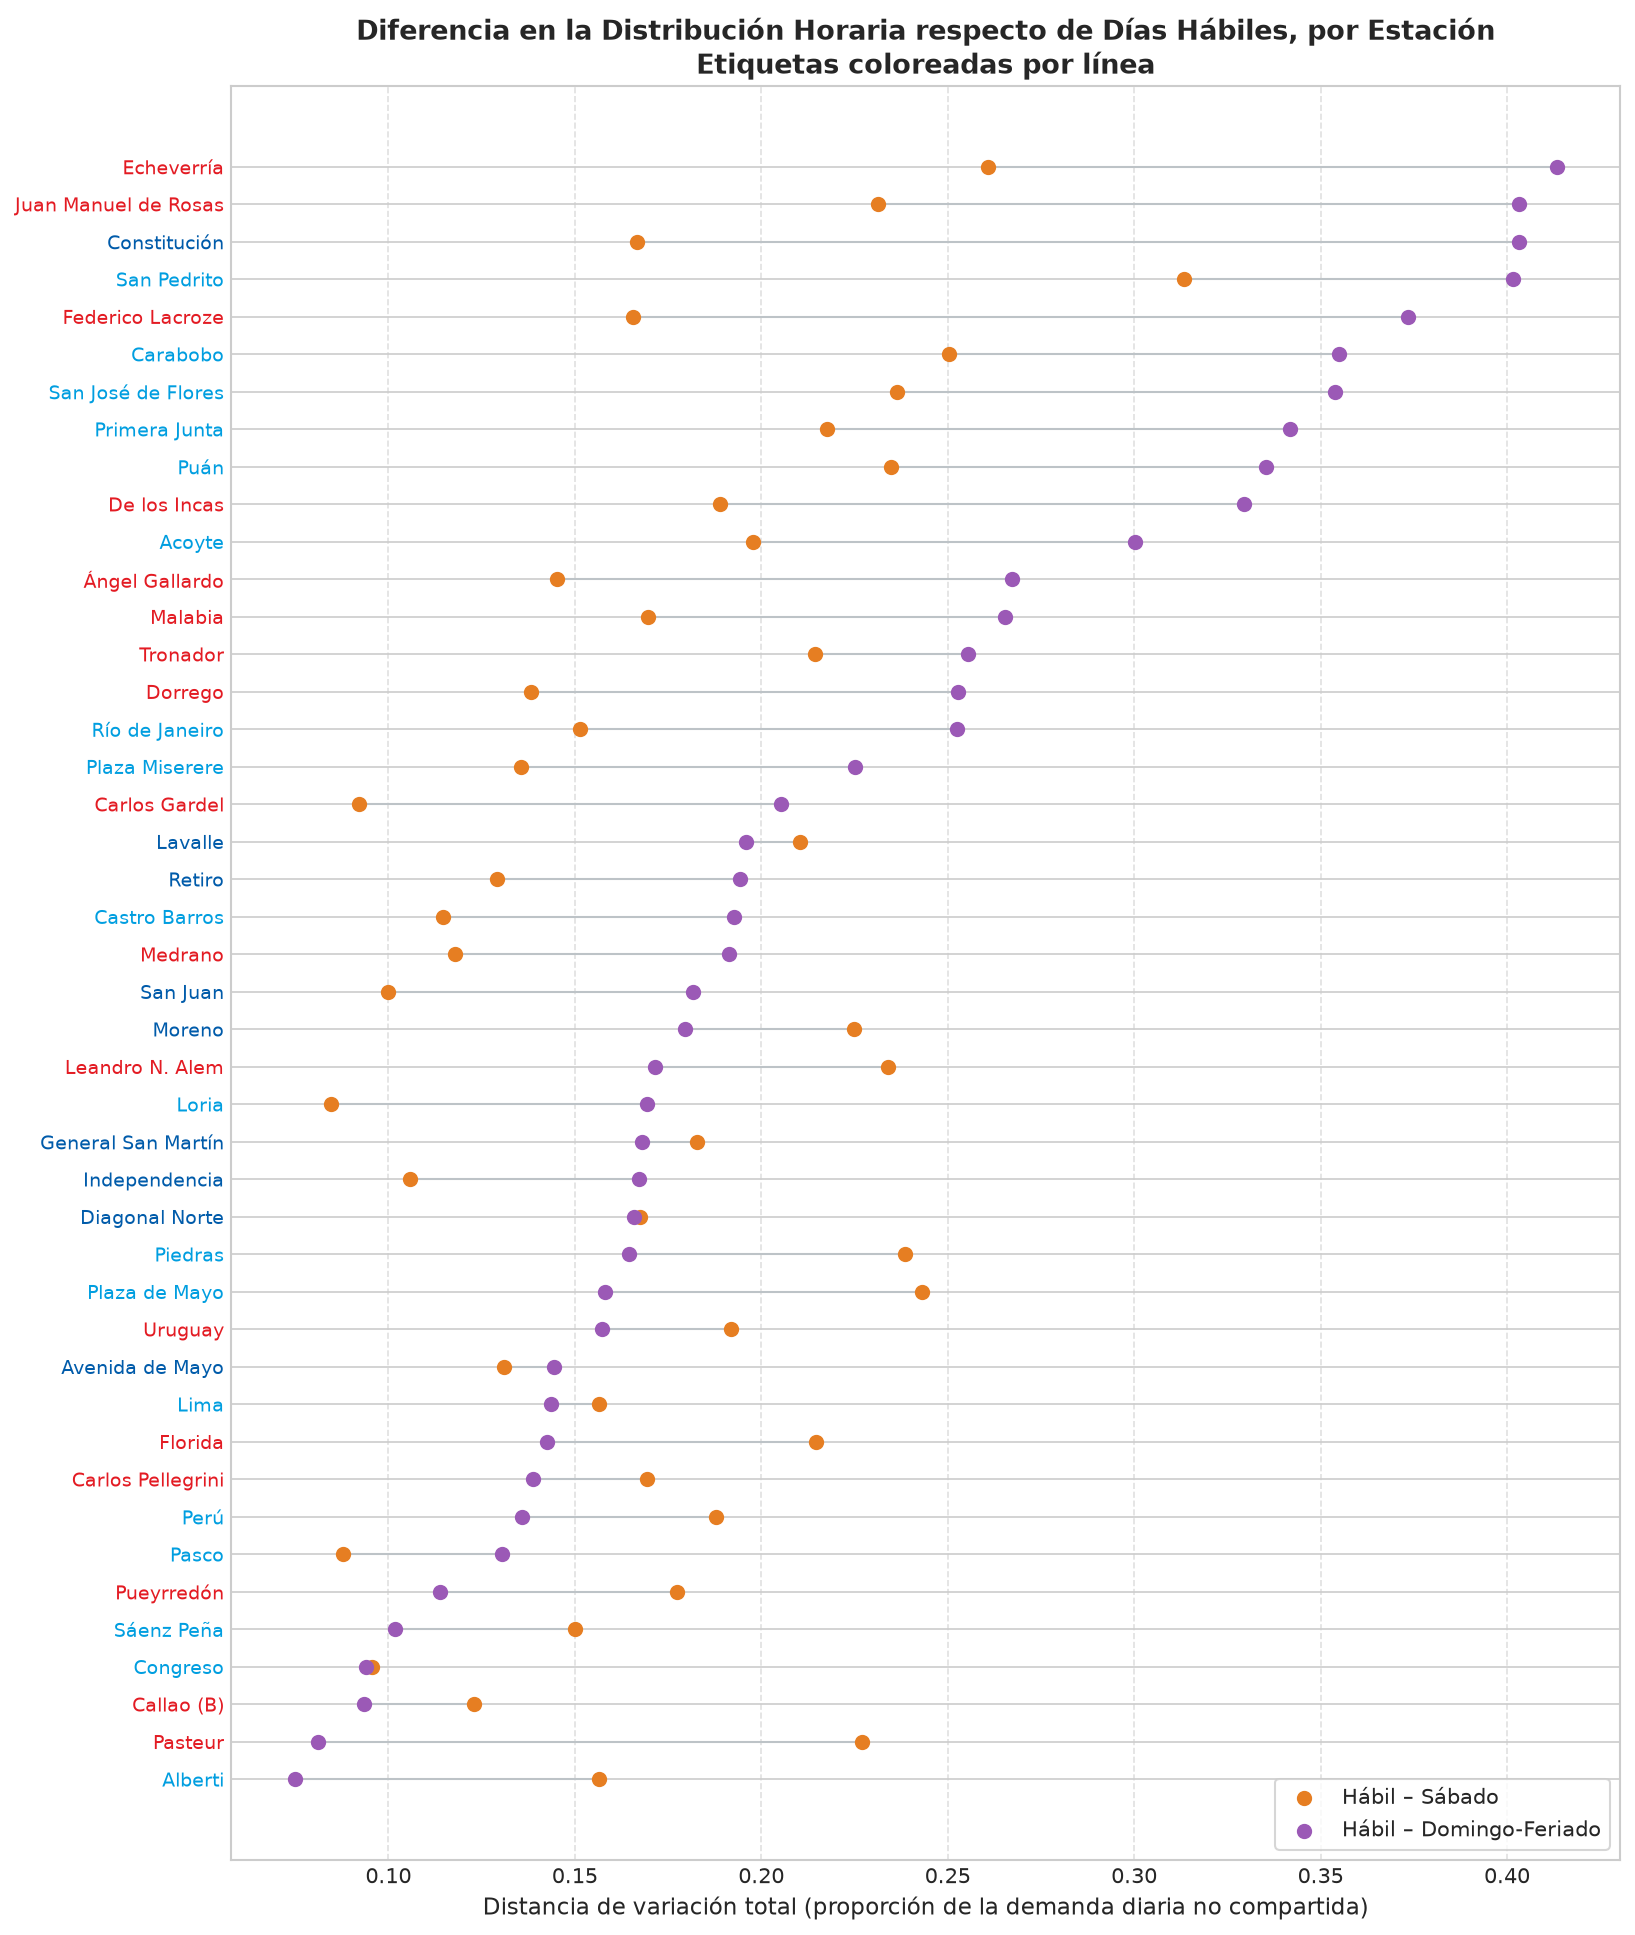

In [23]:
CMP_COLORS = {etiqueta_cmp('Hábil', 'Sábado'): TIPO_COLORS['Sábado'],
              etiqueta_cmp('Hábil', 'Domingo-Feriado'): TIPO_COLORS['Domingo-Feriado']}
tv_hip = df_tv[df_tv['comparacion'].isin(CMP_COLORS)].pivot(index='estacion', columns='comparacion', values='tv')
tv_hip = tv_hip.sort_values(by=etiqueta_cmp('Hábil', 'Domingo-Feriado'))
fig, ax = plt.subplots(figsize=(11, 13))
y = np.arange(len(tv_hip))
for cmp_, color in CMP_COLORS.items():
    ax.scatter(tv_hip[cmp_], y, color=color, s=40, label=cmp_, zorder=3)
ax.hlines(y, tv_hip.min(axis=1), tv_hip.max(axis=1), color='#bdc3c7', linewidth=1, zorder=1)
ax.set_yticks(y)
ax.set_yticklabels(tv_hip.index, fontsize=9)
for etiqueta, est in zip(ax.get_yticklabels(), tv_hip.index):
    etiqueta.set_color(line_colors[linea_de[est]])
ax.set_xlabel('Distancia de variación total (proporción de la demanda diaria no compartida)', fontsize=11)
ax.set_title('Diferencia en la Distribución Horaria respecto de Días Hábiles, por Estación\nEtiquetas coloreadas por línea',
             fontsize=13, fontweight='bold')
ax.grid(True, axis='x', linestyle='--', alpha=0.6)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
guardar_figura('07_tv_distribucion_horaria_por_estacion.png', bbox_inches='tight')

Gráfico guardado: output/graficos/08_diferencias_por_ventana_estaciones_representativas.png


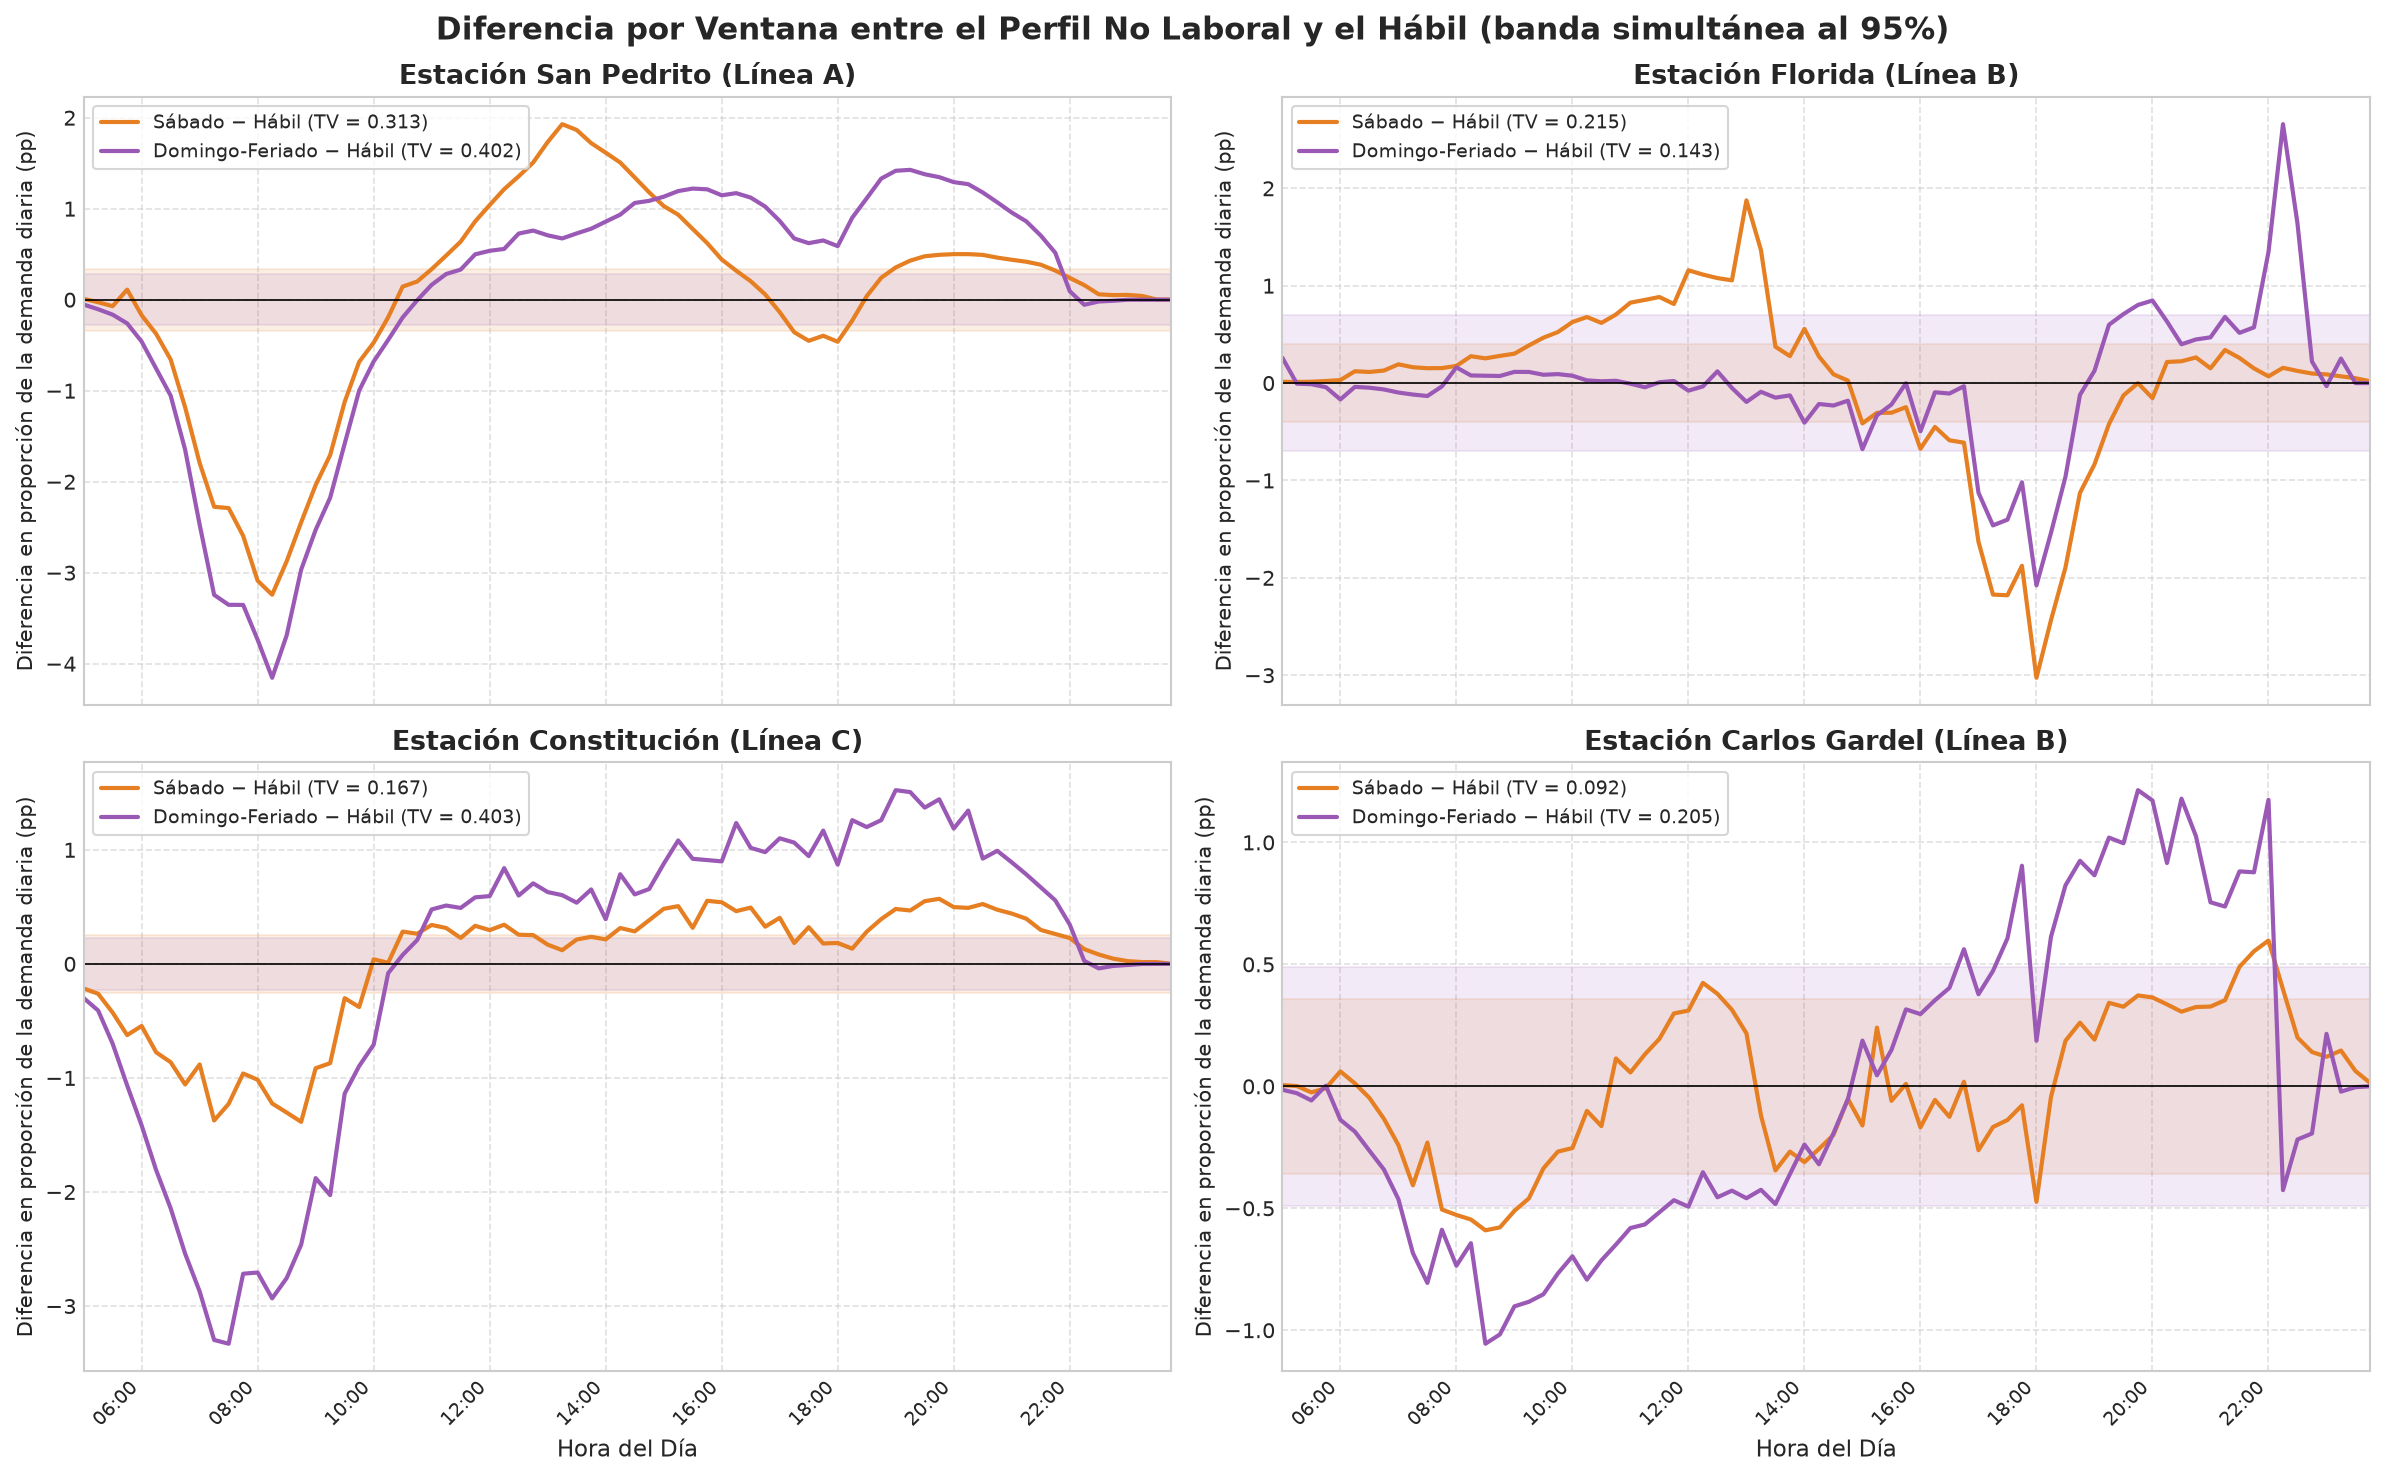

In [24]:
horas = np.array([int(v[:2]) + int(v[3:]) / 60 for v in VENTANAS])
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
for ax, est in zip(axes.flatten(), ESTACIONES_REPRESENTATIVAS):
    for t in NO_LABORABLES:
        r = df_tv[(df_tv['estacion'] == est) & (df_tv['comparacion'] == etiqueta_cmp('Hábil', t))].iloc[0]
        ax.plot(horas, r['dif'] * 100, color=TIPO_COLORS[t], linewidth=2,
                label=f"{t} − Hábil (TV = {r['tv']:.3f})")
        ax.fill_between(horas, -r['banda'] * 100, r['banda'] * 100, color=TIPO_COLORS[t], alpha=0.12)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'Estación {est} ({linea_de[est]})', fontsize=13, fontweight='bold')
    ax.set_ylabel('Diferencia en proporción de la demanda diaria (pp)', fontsize=10)
    ax.set_xlim(5.0, 23.75)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left', frameon=True, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel('Hora del Día', fontsize=11)
    ax.set_xticks(np.arange(6, 24, 2))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(6, 24, 2)], rotation=45, ha='right', fontsize=9)
plt.suptitle('Diferencia por Ventana entre el Perfil No Laboral y el Hábil (banda simultánea al 95%)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
guardar_figura('08_diferencias_por_ventana_estaciones_representativas.png')

## 7. Modelo de Planificación por Temporada
El objetivo del modelo es proyectar la demanda de la **próxima temporada** por estación, tipo de día y ventana de 15 minutos, con la información disponible **antes de su inicio**: así se planifica un cronograma (DM-06). Se toman como temporadas los trimestres calendario.

**Información admisible.** Variables de calendario (tipo de día, día de la semana, mes, día del mes, feriados, puentes, vísperas y días posteriores a feriados), identidad de la estación, el valor de 52 semanas antes y perfiles y niveles históricos **calculados a la fecha de inicio de cada temporada**, también para las temporadas de entrenamiento (cada una recibe lo que un planificador habría tenido al comenzarla). No se usa ningún dato de la temporada que se proyecta.

**Modelos comparados** (DM-06):
- **Perfil histórico:** promedio por estación × tipo de día × ventana de los datos anteriores. Línea base obligatoria.
- **V1 × forma:** nivel de los últimos 3 meses × factor estacional del año previo, multiplicado por la forma de los últimos 12 meses (proporción del día en cada ventana). Referencia sin aprendizaje automático.
- **XGBoost directo:** predice los ingresos por ventana. Estructura alternativa.
- **V2 × forma:** XGBoost predice el volumen diario como cociente respecto del nivel reciente (los árboles no extrapolan tendencias) y se multiplica por la forma. Estructura propuesta.

**Evaluación con origen móvil.** Para cada trimestre de 2019, los modelos se entrenan sólo con datos anteriores a su inicio (el trimestre inmediatamente anterior se usa para la detención temprana) y predicen ese trimestre. Los hiperparámetros de ambos modelos XGBoost se eligen con la misma grilla y el mismo criterio (RMSE por ventana promedio) sobre los cuatro trimestres de 2018. La grilla incluye entrenar con todos los años o sólo con los dos últimos, como tratamiento común del nivel.

**Cierres parciales.** Los días con ingreso positivo pero menor al 10% de la mediana de la estación para su tipo de día (cierres parciales, ver 2.7) no representan la demanda de un día con servicio normal. Con la mediana calculada sólo con datos anteriores a cada origen, esos días se excluyen del cálculo de niveles, perfiles y rezagos, y de los objetivos de entrenamiento. La evaluación incluye todos los días con servicio.

**Acotamiento de atípicos.** En los datos de entrenamiento, los ingresos por ventana que superan el máximo entre el percentil 99,9 y Q3 + 4,5·IQR de su estación y tipo de día se acotan a ese umbral, calculado sólo con datos anteriores al origen. La evaluación se hace siempre contra los valores observados sin acotar.

In [25]:
import warnings

import xgboost as xgb

TIPO_IDX = {t: k for k, t in enumerate(TIPOS_DIA)}
ESTACIONES = sorted(df_diario['estacion'].unique())
EST_IDX = {e: k for k, e in enumerate(ESTACIONES)}
NE, NV, NT = len(ESTACIONES), len(VENTANAS), len(TIPOS_DIA)
FECHAS = pd.date_range(df_diario['fecha'].min(), df_diario['fecha'].max())
FECHA_IDX = pd.Series(np.arange(len(FECHAS)), index=FECHAS)
NQ = 24                                                    # trimestres 2014T1 ... 2019T4
inicio_trim = lambda q: pd.Timestamp(2014 + q // 4, 3 * (q % 4) + 1, 1)
nombre_trim = lambda q: f"{2014 + q // 4}T{q % 4 + 1}"

# Calendario de cada fecha, con las variables de feriados del modelo
cal_mod = calendario(FECHAS).set_index('fecha')
nombre_fer = pd.Series(cal_mod.index.date, index=cal_mod.index).map(FERIADOS_AR.get).fillna('')
feriados_set = set(cal_mod.index[cal_mod['es_feriado'] == 1])
cal_mod['tipo'] = cal_mod['tipo_dia'].map(TIPO_IDX).astype(np.int8)
cal_mod['es_puente'] = nombre_fer.str.contains('turístic').astype(np.int8)
cal_mod['pre_feriado'] = (cal_mod.index + pd.Timedelta(days=1)).isin(feriados_set).astype(np.int8)
cal_mod['post_feriado'] = (cal_mod.index - pd.Timedelta(days=1)).isin(feriados_set).astype(np.int8)
cal_mod['dia_mes'] = cal_mod.index.day.astype(np.int8)
cal_mod['qidx'] = ((cal_mod.index.year - 2014) * 4 + cal_mod.index.quarter - 1).astype(np.int16)
TIPO_F = cal_mod['tipo'].to_numpy()
QIDX_F = cal_mod['qidx'].to_numpy()

# Cubo denso estación × fecha × ventana (NaN = día sin servicio o sin datos; ventana sin registro = 0)
CUBO = np.full((NE, len(FECHAS), NV), np.nan, dtype=np.float32)
ei = df_diario['estacion'].map(EST_IDX).to_numpy()
fi = FECHA_IDX[df_diario['fecha']].to_numpy()
CUBO[ei, fi, :] = 0.0
vi = pd.Series(np.arange(NV), index=VENTANAS)
CUBO[df_15min['estacion'].map(EST_IDX).to_numpy(), FECHA_IDX[df_15min['fecha']].to_numpy(),
     vi[df_15min['ventana_15min']].to_numpy()] = df_15min['ingresos'].to_numpy(dtype=np.float32)
VOL = CUBO.sum(axis=2)                                     # volumen diario (NaN si no hubo servicio)
FORMA_DIA = CUBO / VOL[:, :, None]                         # proporción del día en cada ventana
print(f"Cubo: {NE} estaciones × {len(FECHAS)} fechas × {NV} ventanas; "
      f"{np.isfinite(VOL).sum():,} días-estación con servicio")

Cubo: 44 estaciones × 2190 fechas × 96 ventanas; 94,597 días-estación con servicio


In [26]:
def media_por(mask_fechas, valores):
    # Media por estación × tipo de día (× ventana si valores es 3D) sobre las fechas de mask_fechas.
    out = np.full((NE, NT) + valores.shape[2:], np.nan, dtype=np.float64)
    for t in range(NT):
        sel = mask_fechas & (TIPO_F == t)
        if sel.any():
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)  # estaciones sin días de ese tipo en el período
                out[:, t] = np.nanmean(valores[:, sel], axis=1)
    return out


# Variables 'as-of': para cada trimestre q, calculadas con los datos anteriores a su inicio
def dias_validos(S):
    # Días con servicio normal según los datos anteriores a S: se excluyen los cierres parciales
    # (ingreso < 10% de la mediana de la estación para su tipo de día).
    antes = FECHAS < S
    mediana = np.full((NE, NT), np.nan)
    for t in range(NT):
        mediana[:, t] = np.nanmedian(VOL[:, antes & (TIPO_F == t)], axis=1)
    with np.errstate(invalid='ignore'):
        return VOL >= 0.1 * mediana[:, TIPO_F]


ASOF = {}
for q in range(4, NQ):
    S = inicio_trim(q)
    antes = FECHAS < S
    valido = dias_validos(S)
    CUBO_V = np.where(valido[:, :, None], CUBO, np.nan)
    VOL_V = np.where(valido, VOL, np.nan)
    FORMA_V = np.where(valido[:, :, None], FORMA_DIA, np.nan)
    ult3 = antes & (FECHAS >= S - pd.DateOffset(months=3))
    ult12 = antes & (FECHAS >= S - pd.DateOffset(months=12))
    mismo_trim = antes & (cal_mod['qidx'].to_numpy() % 4 == q % 4)
    S1 = S - pd.DateOffset(years=1)
    trim_prev = (FECHAS >= S1) & (FECHAS < S1 + pd.DateOffset(months=3))
    pre_prev = (FECHAS >= S1 - pd.DateOffset(months=3)) & (FECHAS < S1)
    with np.errstate(invalid='ignore', divide='ignore'):
        a = dict(
            perfil_hist=media_por(antes, CUBO_V), perfil_mismo_trim=media_por(mismo_trim, CUBO_V),
            perfil_reciente=media_por(ult3, CUBO_V), forma_12m=media_por(ult12, FORMA_V),
            vol_hist=media_por(antes, VOL_V), vol_rec=media_por(ult3, VOL_V),
            vol_trim_prev=media_por(trim_prev, VOL_V), vol_pre_prev=media_por(pre_prev, VOL_V))
        a['vol_rec'] = np.where(np.isfinite(a['vol_rec']), a['vol_rec'], a['vol_hist'])
        a['s_factor'] = np.where(np.isfinite(a['vol_trim_prev'] / a['vol_pre_prev']),
                                 a['vol_trim_prev'] / a['vol_pre_prev'], 1.0)
    a['valido'] = valido
    ASOF[q] = a
del CUBO_V, VOL_V, FORMA_V


def filas_trimestre(q):
    # Filas día-estación con servicio del trimestre q, con sus variables de calendario y 'as-of'.
    fsel = np.where(QIDX_F == q)[0]
    e, f = np.nonzero(np.isfinite(VOL[:, fsel]))
    f = fsel[f]
    t = TIPO_F[f]
    a = ASOF[q]
    d = pd.DataFrame({'est': e.astype(np.int16), 'fi': f, 'tipo': t, 'qidx': q})
    for c in ['dia_semana', 'es_feriado', 'es_puente', 'pre_feriado', 'post_feriado', 'mes', 'dia_mes']:
        d[c] = cal_mod[c].to_numpy()[f]
    d['vol'] = VOL[e, f]
    fl = np.maximum(f - 364, 0)
    d['vol_lag364'] = np.where((f >= 364) & a['valido'][e, fl], VOL[e, fl], np.nan)
    for c in ['vol_hist', 'vol_rec', 'vol_trim_prev', 's_factor']:
        d[c] = a[c][e, t]
    d['r_vol_hist'] = d['vol_hist'] / d['vol_rec']
    d['r_vol_trim_prev'] = d['vol_trim_prev'] / d['vol_rec']
    d['r_vol_lag364'] = d['vol_lag364'] / d['vol_rec']
    return d


DIARIO_MOD = pd.concat([filas_trimestre(q) for q in range(4, NQ)], ignore_index=True)
print(f"Días-estación para modelado (2015–2019): {len(DIARIO_MOD):,}")

Días-estación para modelado (2015–2019): 79,185


In [27]:
FEATS_VOL = ['est', 'tipo', 'dia_semana', 'es_feriado', 'es_puente', 'pre_feriado', 'post_feriado', 'mes',
             'dia_mes', 's_factor', 'r_vol_hist', 'r_vol_trim_prev', 'r_vol_lag364']
FEATS_DIR = ['est', 'win', 'tipo', 'dia_semana', 'es_feriado', 'es_puente', 'pre_feriado', 'post_feriado', 'mes',
             'dia_mes', 'lag_364', 'perfil_hist', 'perfil_mismo_trim', 'perfil_reciente', 'nivel_reciente',
             'vol_hist']
GRILLA = [dict(max_depth=d, anios=a) for d in (4, 8) for a in ('todos', 'recientes')]
NTHREAD = os.cpu_count()


def umbrales_acotamiento(q_origen):
    # Umbral por estación × tipo de día con los datos anteriores al origen (criterio derivado de DM-04).
    antes = FECHAS < inicio_trim(q_origen)
    u = np.full((NE, NT), np.inf, dtype=np.float32)
    for t in range(NT):
        x = CUBO[:, antes & (TIPO_F == t), :].reshape(NE, -1)
        q25, q75, q999 = (np.nanpercentile(x, p, axis=1) for p in (25, 75, 99.9))
        u[:, t] = np.maximum(q999, q75 + 4.5 * (q75 - q25))
    return u


def expandir_ventanas(d, q):
    # De filas día-estación a filas día-estación-ventana, con las variables del modelo directo.
    a = ASOF[q]
    e, f, t = (np.repeat(d[c].to_numpy(), NV) for c in ('est', 'fi', 'tipo'))
    w = np.tile(np.arange(NV), len(d))
    x = pd.DataFrame({'est': e, 'win': w, 'tipo': t})
    for c in ['dia_semana', 'es_feriado', 'es_puente', 'pre_feriado', 'post_feriado', 'mes', 'dia_mes']:
        x[c] = np.repeat(d[c].to_numpy(), NV)
    fl = np.maximum(f - 364, 0)
    x['lag_364'] = np.where((f >= 364) & a['valido'][e, fl], CUBO[e, fl, w], np.nan)
    for c in ['perfil_hist', 'perfil_mismo_trim', 'perfil_reciente']:
        x[c] = a[c][e, t, w]
    x['nivel_reciente'] = (a['vol_rec'] / a['vol_hist'])[e, t]
    x['vol_hist'] = a['vol_hist'][e, t]
    x['forma_12m'] = a['forma_12m'][e, t, w]
    x['y'] = CUBO[e, f, w]
    return x


def entrenar_xgb(X, y, Xv, yv, max_depth):
    params = dict(objective='reg:squarederror', tree_method='hist', max_depth=max_depth, eta=0.08,
                  subsample=0.8, colsample_bytree=0.8, min_child_weight=50, nthread=NTHREAD, seed=0)
    dtr, dva = xgb.DMatrix(X, label=y, nthread=NTHREAD), xgb.DMatrix(Xv, label=yv, nthread=NTHREAD)
    return xgb.train(params, dtr, num_boost_round=2000, evals=[(dva, 'val')],
                     early_stopping_rounds=50, verbose_eval=False)


def predecir(m, X):
    return np.clip(m.predict(xgb.DMatrix(X, nthread=NTHREAD), iteration_range=(0, m.best_iteration + 1)), 0, None)


def proyectar_trimestre(q, cfg_dir, cfg_vol):
    # Entrena con los trimestres anteriores a q y proyecta q con los cuatro modelos.
    u = umbrales_acotamiento(q)
    desde = 4 if cfg_dir['anios'] == 'todos' else max(4, q - 9)
    desde_v = 4 if cfg_vol['anios'] == 'todos' else max(4, q - 9)
    test_d = DIARIO_MOD[DIARIO_MOD['qidx'] == q]
    test = expandir_ventanas(test_d, q)
    out = test[['est', 'win', 'tipo', 'y']].copy()
    out['fi'] = np.repeat(test_d['fi'].to_numpy(), NV)
    out['qidx'] = q

    # Perfil histórico y V1 × forma
    out['perfil_historico'] = test['perfil_hist'].to_numpy()
    v1 = (test_d['vol_rec'] * test_d['s_factor']).to_numpy()
    out['v1_forma'] = np.repeat(v1, NV) * test['forma_12m'].to_numpy()

    # Días de entrenamiento: sin cierres parciales, según los datos anteriores al origen
    valido_o = ASOF[q]['valido']
    entrenable = valido_o[DIARIO_MOD['est'].to_numpy(), DIARIO_MOD['fi'].to_numpy()]
    D_ENT = DIARIO_MOD[entrenable]

    # XGBoost directo: objetivo = ingresos por ventana acotados
    if cfg_dir is not None:
        tr = pd.concat([expandir_ventanas(D_ENT[D_ENT['qidx'] == k], k) for k in range(desde, q - 1)])
        va = expandir_ventanas(D_ENT[D_ENT['qidx'] == q - 1], q - 1)
        for z in (tr, va):
            z['y'] = np.minimum(z['y'], u[z['est'], z['tipo']])
        m = entrenar_xgb(tr[FEATS_DIR], tr['y'], va[FEATS_DIR], va['y'], cfg_dir['max_depth'])
        out['xgb_directo'] = predecir(m, test[FEATS_DIR])
        del tr, va

    # V2 × forma: objetivo = volumen diario acotado / nivel reciente
    def vol_acotado(d):
        e, f, t = d['est'].to_numpy(), d['fi'].to_numpy(), d['tipo'].to_numpy()
        return np.minimum(CUBO[e, f, :], u[e, t][:, None]).sum(axis=1)
    trv = D_ENT[(D_ENT['qidx'] >= desde_v) & (D_ENT['qidx'] <= q - 2)]
    vav = D_ENT[D_ENT['qidx'] == q - 1]
    mv = entrenar_xgb(trv[FEATS_VOL], vol_acotado(trv) / trv['vol_rec'],
                      vav[FEATS_VOL], vol_acotado(vav) / vav['vol_rec'], cfg_vol['max_depth'])
    v2 = predecir(mv, test_d[FEATS_VOL]) * test_d['vol_rec'].to_numpy()
    out['v2_forma'] = np.repeat(v2, NV) * test['forma_12m'].to_numpy()
    return out


rmse = lambda y, p: float(np.sqrt(np.nanmean((y - p) ** 2)))

### 7.1. Ajuste de Hiperparámetros
Misma grilla para ambos modelos XGBoost (profundidad 4 u 8; entrenamiento con todos los años o sólo con los dos últimos), evaluada con origen móvil sobre los cuatro trimestres de 2018 y elegida por el RMSE por ventana promedio. Esta celda es la más costosa del notebook (~10 minutos).

In [28]:
# Ajuste de hiperparámetros: misma grilla y mismo criterio para ambos modelos XGBoost (trimestres de 2018)
Q_AJUSTE, Q_PRUEBA = range(16, 20), range(20, 24)
res_ajuste = []
for cfg in GRILLA:
    errs_dir, errs_vol = [], []
    for q in Q_AJUSTE:
        o = proyectar_trimestre(q, cfg, cfg)
        errs_dir.append(rmse(o['y'], o['xgb_directo']))
        errs_vol.append(rmse(o['y'], o['v2_forma']))
    res_ajuste.append({**cfg, 'RMSE XGBoost directo': np.mean(errs_dir), 'RMSE V2 × forma': np.mean(errs_vol)})
    print(f"{cfg}: directo {np.mean(errs_dir):.2f} | V2 × forma {np.mean(errs_vol):.2f}", flush=True)
res_ajuste = pd.DataFrame(res_ajuste)
cfg_dir = GRILLA[int(res_ajuste['RMSE XGBoost directo'].idxmin())]
cfg_vol = GRILLA[int(res_ajuste['RMSE V2 × forma'].idxmin())]
display(res_ajuste.style.format({'RMSE XGBoost directo': '{:.2f}', 'RMSE V2 × forma': '{:.2f}'}))
print(f"Configuración elegida: XGBoost directo {cfg_dir} | V2 × forma {cfg_vol}")

{'max_depth': 4, 'anios': 'todos'}: directo 73.74 | V2 × forma 67.53


{'max_depth': 4, 'anios': 'recientes'}: directo 74.19 | V2 × forma 67.93


{'max_depth': 8, 'anios': 'todos'}: directo 73.22 | V2 × forma 66.58


{'max_depth': 8, 'anios': 'recientes'}: directo 73.02 | V2 × forma 66.73


,max_depth,anios,RMSE XGBoost directo,RMSE V2 × forma
0,4,todos,73.74,67.53
1,4,recientes,74.19,67.93
2,8,todos,73.22,66.58
3,8,recientes,73.02,66.73


Configuración elegida: XGBoost directo {'max_depth': 8, 'anios': 'recientes'} | V2 × forma {'max_depth': 8, 'anios': 'todos'}


### 7.2. Evaluación en 2019
Cada trimestre de 2019 se proyecta con los datos anteriores a su inicio. Se informan métricas por ventana (RMSE, MAE, R², sesgo de volumen) y por perfil de estación y tipo de día (distancia de variación total de la forma, error de retención, error de volumen medio y error diario mediano).

In [29]:
# Evaluación: cada trimestre de 2019, con origen móvil
PROY = pd.concat([proyectar_trimestre(q, cfg_dir, cfg_vol) for q in Q_PRUEBA], ignore_index=True)
MODELOS = {'perfil_historico': 'Perfil histórico', 'v1_forma': 'V1 × forma',
           'xgb_directo': 'XGBoost directo', 'v2_forma': 'V2 × forma'}
PROY['tipo_dia'] = np.array(TIPOS_DIA)[PROY['tipo']]
PROY['estacion'] = np.array(ESTACIONES)[PROY['est']]
print(f"Filas proyectadas (2019): {len(PROY):,}")

Filas proyectadas (2019): 1,525,632


In [30]:
# Métricas por ventana
filas = []
for seg, d in [('Total', PROY)] + [(t, PROY[PROY['tipo_dia'] == t]) for t in TIPOS_DIA]:
    for c, nombre in MODELOS.items():
        e = d['y'] - d[c]
        filas.append({'Segmento': seg, 'Modelo': nombre, 'RMSE': np.sqrt((e ** 2).mean()), 'MAE': e.abs().mean(),
                      'R²': 1 - (e ** 2).sum() / ((d['y'] - d['y'].mean()) ** 2).sum(),
                      'Sesgo de volumen (%)': (d[c].sum() / d['y'].sum() - 1) * 100})
met_ventana = pd.DataFrame(filas)

# Métricas por perfil (estación × tipo de día, promedio de 2019) y por día
DIA = PROY.groupby(['est', 'tipo', 'fi', 'qidx'])[['y', *MODELOS]].sum().reset_index()
PERF = PROY.groupby(['est', 'tipo', 'win'])[['y', *MODELOS]].mean()
VOLM = DIA.groupby(['est', 'tipo'])[['y', *MODELOS]].mean()
filas = []
for c, nombre in MODELOS.items():
    tv = PERF.groupby(level=['est', 'tipo']).apply(
        lambda x: 0.5 * np.abs(x['y'] / x['y'].sum() - x[c] / x[c].sum()).sum())
    r = {'Modelo': nombre, 'TV de forma (mediana)': tv.median()}
    for t in NO_LABORABLES:
        k = TIPO_IDX[t]
        ret_o = VOLM['y'].xs(k, level='tipo') / VOLM['y'].xs(0, level='tipo') * 100
        ret_p = VOLM[c].xs(k, level='tipo') / VOLM[c].xs(0, level='tipo') * 100
        r[f'Error retención {t} (pp)'] = (ret_p - ret_o).abs().mean()
    r['Error de volumen medio (%)'] = ((VOLM[c] / VOLM['y'] - 1).abs() * 100).mean()
    r['Error diario mediano (%)'] = ((DIA[c] / DIA['y'] - 1).abs() * 100).median()
    filas.append(r)
met_perfil = pd.DataFrame(filas)
display(met_ventana.style.format(precision=2).hide(axis='index'))
display(met_perfil.style.format(precision=3).hide(axis='index'))

Segmento,Modelo,RMSE,MAE,R²,Sesgo de volumen (%)
Total,Perfil histórico,64.65,25.64,0.92,-5.18
Total,V1 × forma,61.65,22.61,0.93,2.36
Total,XGBoost directo,59.25,23.93,0.94,6.27
Total,V2 × forma,59.11,21.77,0.94,5.68
Hábil,Perfil histórico,74.57,31.04,0.92,-4.04
Hábil,V1 × forma,71.95,27.35,0.93,2.51
Hábil,XGBoost directo,68.91,27.98,0.93,5.24
Hábil,V2 × forma,68.68,26.19,0.93,5.64
Sábado,Perfil histórico,42.24,18.38,0.87,-14.48
Sábado,V1 × forma,32.90,14.38,0.92,-0.35


Modelo,TV de forma (mediana),Error retención Sábado (pp),Error retención Domingo-Feriado (pp),Error de volumen medio (%),Error diario mediano (%)
Perfil histórico,0.030,3.800,1.140,10.109,12.572
V1 × forma,0.018,1.227,0.693,3.801,8.431
XGBoost directo,0.043,3.071,4.570,19.482,9.773
V2 × forma,0.018,0.800,0.755,6.814,7.675


In [31]:
md_m = "# Modelo de Planificación por Temporada: Desempeño por Ventana\n\n"
md_m += ("Proyección de cada trimestre de 2019 con datos anteriores a su inicio (origen móvil). "
         f"Hiperparámetros elegidos con los trimestres de 2018: XGBoost directo profundidad {cfg_dir['max_depth']}, "
         f"años de entrenamiento: {cfg_dir['anios']}; V2 × forma profundidad {cfg_vol['max_depth']}, "
         f"años de entrenamiento: {cfg_vol['anios']}.\n\n")
md_m += "| Segmento | Modelo | RMSE (pax/15 min) | MAE (pax/15 min) | R² | Sesgo de volumen (%) |\n"
md_m += "| :--- | :--- | :---: | :---: | :---: | :---: |\n"
for _, r in met_ventana.iterrows():
    md_m += f"| {r['Segmento']} | {r['Modelo']} | {r['RMSE']:.2f} | {r['MAE']:.2f} | {r['R²']:.3f} | {r['Sesgo de volumen (%)']:+.2f} |\n"
guardar_tabla('07_modelo_desempeno_por_ventana.md', md_m)

md_p = "# Modelo de Planificación por Temporada: Desempeño por Perfil\n\n"
md_p += ("Métricas sobre el perfil de cada estación y tipo de día en 2019, el nivel relevante para la diagramación: "
         "distancia de variación total entre el perfil proyectado y el observado (mediana entre estaciones y tipos de día), "
         "error absoluto medio del ratio de retención por estación, error relativo medio del volumen diario medio por "
         "estación y tipo de día, y error relativo mediano del volumen de cada día-estación.\n\n")
md_p += "| Modelo | TV de forma (mediana) | Error retención Sábado (pp) | Error retención Domingo-Feriado (pp) | Error de volumen medio (%) | Error diario mediano (%) |\n"
md_p += "| :--- | :---: | :---: | :---: | :---: | :---: |\n"
for _, r in met_perfil.iterrows():
    md_p += (f"| {r['Modelo']} | {r['TV de forma (mediana)']:.3f} | {r['Error retención Sábado (pp)']:.2f} "
             f"| {r['Error retención Domingo-Feriado (pp)']:.2f} | {r['Error de volumen medio (%)']:.2f} | {r['Error diario mediano (%)']:.2f} |\n")
guardar_tabla('08_modelo_desempeno_por_perfil.md', md_p)

Tabla guardada: output/tablas/07_modelo_desempeno_por_ventana.md


# Modelo de Planificación por Temporada: Desempeño por Ventana

Proyección de cada trimestre de 2019 con datos anteriores a su inicio (origen móvil). Hiperparámetros elegidos con los trimestres de 2018: XGBoost directo profundidad 8, años de entrenamiento: recientes; V2 × forma profundidad 8, años de entrenamiento: todos.

| Segmento | Modelo | RMSE (pax/15 min) | MAE (pax/15 min) | R² | Sesgo de volumen (%) |
| :--- | :--- | :---: | :---: | :---: | :---: |
| Total | Perfil histórico | 64.65 | 25.64 | 0.923 | -5.18 |
| Total | V1 × forma | 61.65 | 22.61 | 0.930 | +2.36 |
| Total | XGBoost directo | 59.25 | 23.93 | 0.936 | +6.27 |
| Total | V2 × forma | 59.11 | 21.77 | 0.936 | +5.68 |
| Hábil | Perfil histórico | 74.57 | 31.04 | 0.923 | -4.04 |
| Hábil | V1 × forma | 71.95 | 27.35 | 0.928 | +2.51 |
| Hábil | XGBoost directo | 68.91 | 27.98 | 0.934 | +5.24 |
| Hábil | V2 × forma | 68.68 | 26.19 | 0.935 | +5.64 |
| Sábado | Perfil histórico | 42.24 | 18.38 | 0.868 | -14.48 |
| Sábado | V1 × forma | 32.90 | 14.38 | 0.920 | -0.35 |
| Sábado | XGBoost directo | 34.00 | 17.09 | 0.914 | +7.89 |
| Sábado | V2 × forma | 32.33 | 14.24 | 0.922 | +4.46 |
| Domingo-Feriado | Perfil histórico | 31.31 | 11.61 | 0.784 | -10.64 |
| Domingo-Feriado | V1 × forma | 29.26 | 11.61 | 0.811 | +3.84 |
| Domingo-Feriado | XGBoost directo | 28.12 | 14.40 | 0.826 | +21.17 |
| Domingo-Feriado | V2 × forma | 30.08 | 11.43 | 0.801 | +8.00 |


Tabla guardada: output/tablas/08_modelo_desempeno_por_perfil.md


# Modelo de Planificación por Temporada: Desempeño por Perfil

Métricas sobre el perfil de cada estación y tipo de día en 2019, el nivel relevante para la diagramación: distancia de variación total entre el perfil proyectado y el observado (mediana entre estaciones y tipos de día), error absoluto medio del ratio de retención por estación, error relativo medio del volumen diario medio por estación y tipo de día, y error relativo mediano del volumen de cada día-estación.

| Modelo | TV de forma (mediana) | Error retención Sábado (pp) | Error retención Domingo-Feriado (pp) | Error de volumen medio (%) | Error diario mediano (%) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Perfil histórico | 0.030 | 3.80 | 1.14 | 10.11 | 12.57 |
| V1 × forma | 0.018 | 1.23 | 0.69 | 3.80 | 8.43 |
| XGBoost directo | 0.043 | 3.07 | 4.57 | 19.48 | 9.77 |
| V2 × forma | 0.018 | 0.80 | 0.75 | 6.81 | 7.67 |


### 7.3. Modelo Adoptado
El criterio de adopción se fijó antes de la evaluación final (DM-06): si V2 × forma no supera a V1 × forma en todas las métricas, se adopta V1 × forma. V2 es mejor por ventana, en el error diario y en la retención de los sábados, porque captura los efectos de calendario y la variación entre días; pero sobreestima el nivel de 2019 (presumiblemente por proyectar el crecimiento de los años previos), y V1 está mejor calibrado en volumen, la componente que determina la frecuencia. **Se adopta V1 × forma** para las proyecciones operativas (retención proyectada y frecuencia requerida). El resultado responde negativamente a la adopción del aprendizaje automático con este horizonte: con una temporada de antelación, la estructura estacional y la separación entre volumen y forma explican la mayor parte de lo que XGBoost captura, y la incertidumbre se concentra en el nivel.

In [32]:
MODELO_ADOPTADO = 'v1_forma'
print(f"Modelo adoptado: {MODELOS[MODELO_ADOPTADO]}")

Modelo adoptado: V1 × forma


In [33]:
# Retención proyectada (modelo adoptado) frente a observada, por estación (OE3)
filas = []
for k_e, e in enumerate(ESTACIONES):
    r = {'Línea': linea_de[e], 'Estación': e}
    for t in NO_LABORABLES:
        k = TIPO_IDX[t]
        r[f'obs_{t}'] = VOLM.loc[(k_e, k), 'y'] / VOLM.loc[(k_e, 0), 'y'] * 100
        r[f'proy_{t}'] = VOLM.loc[(k_e, k), MODELO_ADOPTADO] / VOLM.loc[(k_e, 0), MODELO_ADOPTADO] * 100
    filas.append(r)
ret_proy = pd.DataFrame(filas).sort_values(['Línea', 'Estación'])
md_r = f"# Retención Proyectada frente a Observada por Estación ({MODELOS[MODELO_ADOPTADO]}, 2019)\n\n"
md_r += "| Línea | Estación | Sábado observada (%) | Sábado proyectada (%) | Domingo-Feriado observada (%) | Domingo-Feriado proyectada (%) |\n"
md_r += "| :--- | :--- | :---: | :---: | :---: | :---: |\n"
for _, r in ret_proy.iterrows():
    md_r += (f"| {r['Línea']} | {r['Estación']} | {r['obs_Sábado']:.2f} | {r['proy_Sábado']:.2f} "
             f"| {r['obs_Domingo-Feriado']:.2f} | {r['proy_Domingo-Feriado']:.2f} |\n")
guardar_tabla('09_retencion_proyectada_vs_observada.md', md_r, mostrar=False)

Tabla guardada: output/tablas/09_retencion_proyectada_vs_observada.md


Gráfico guardado: output/graficos/09_perfiles_observados_vs_proyectados.png


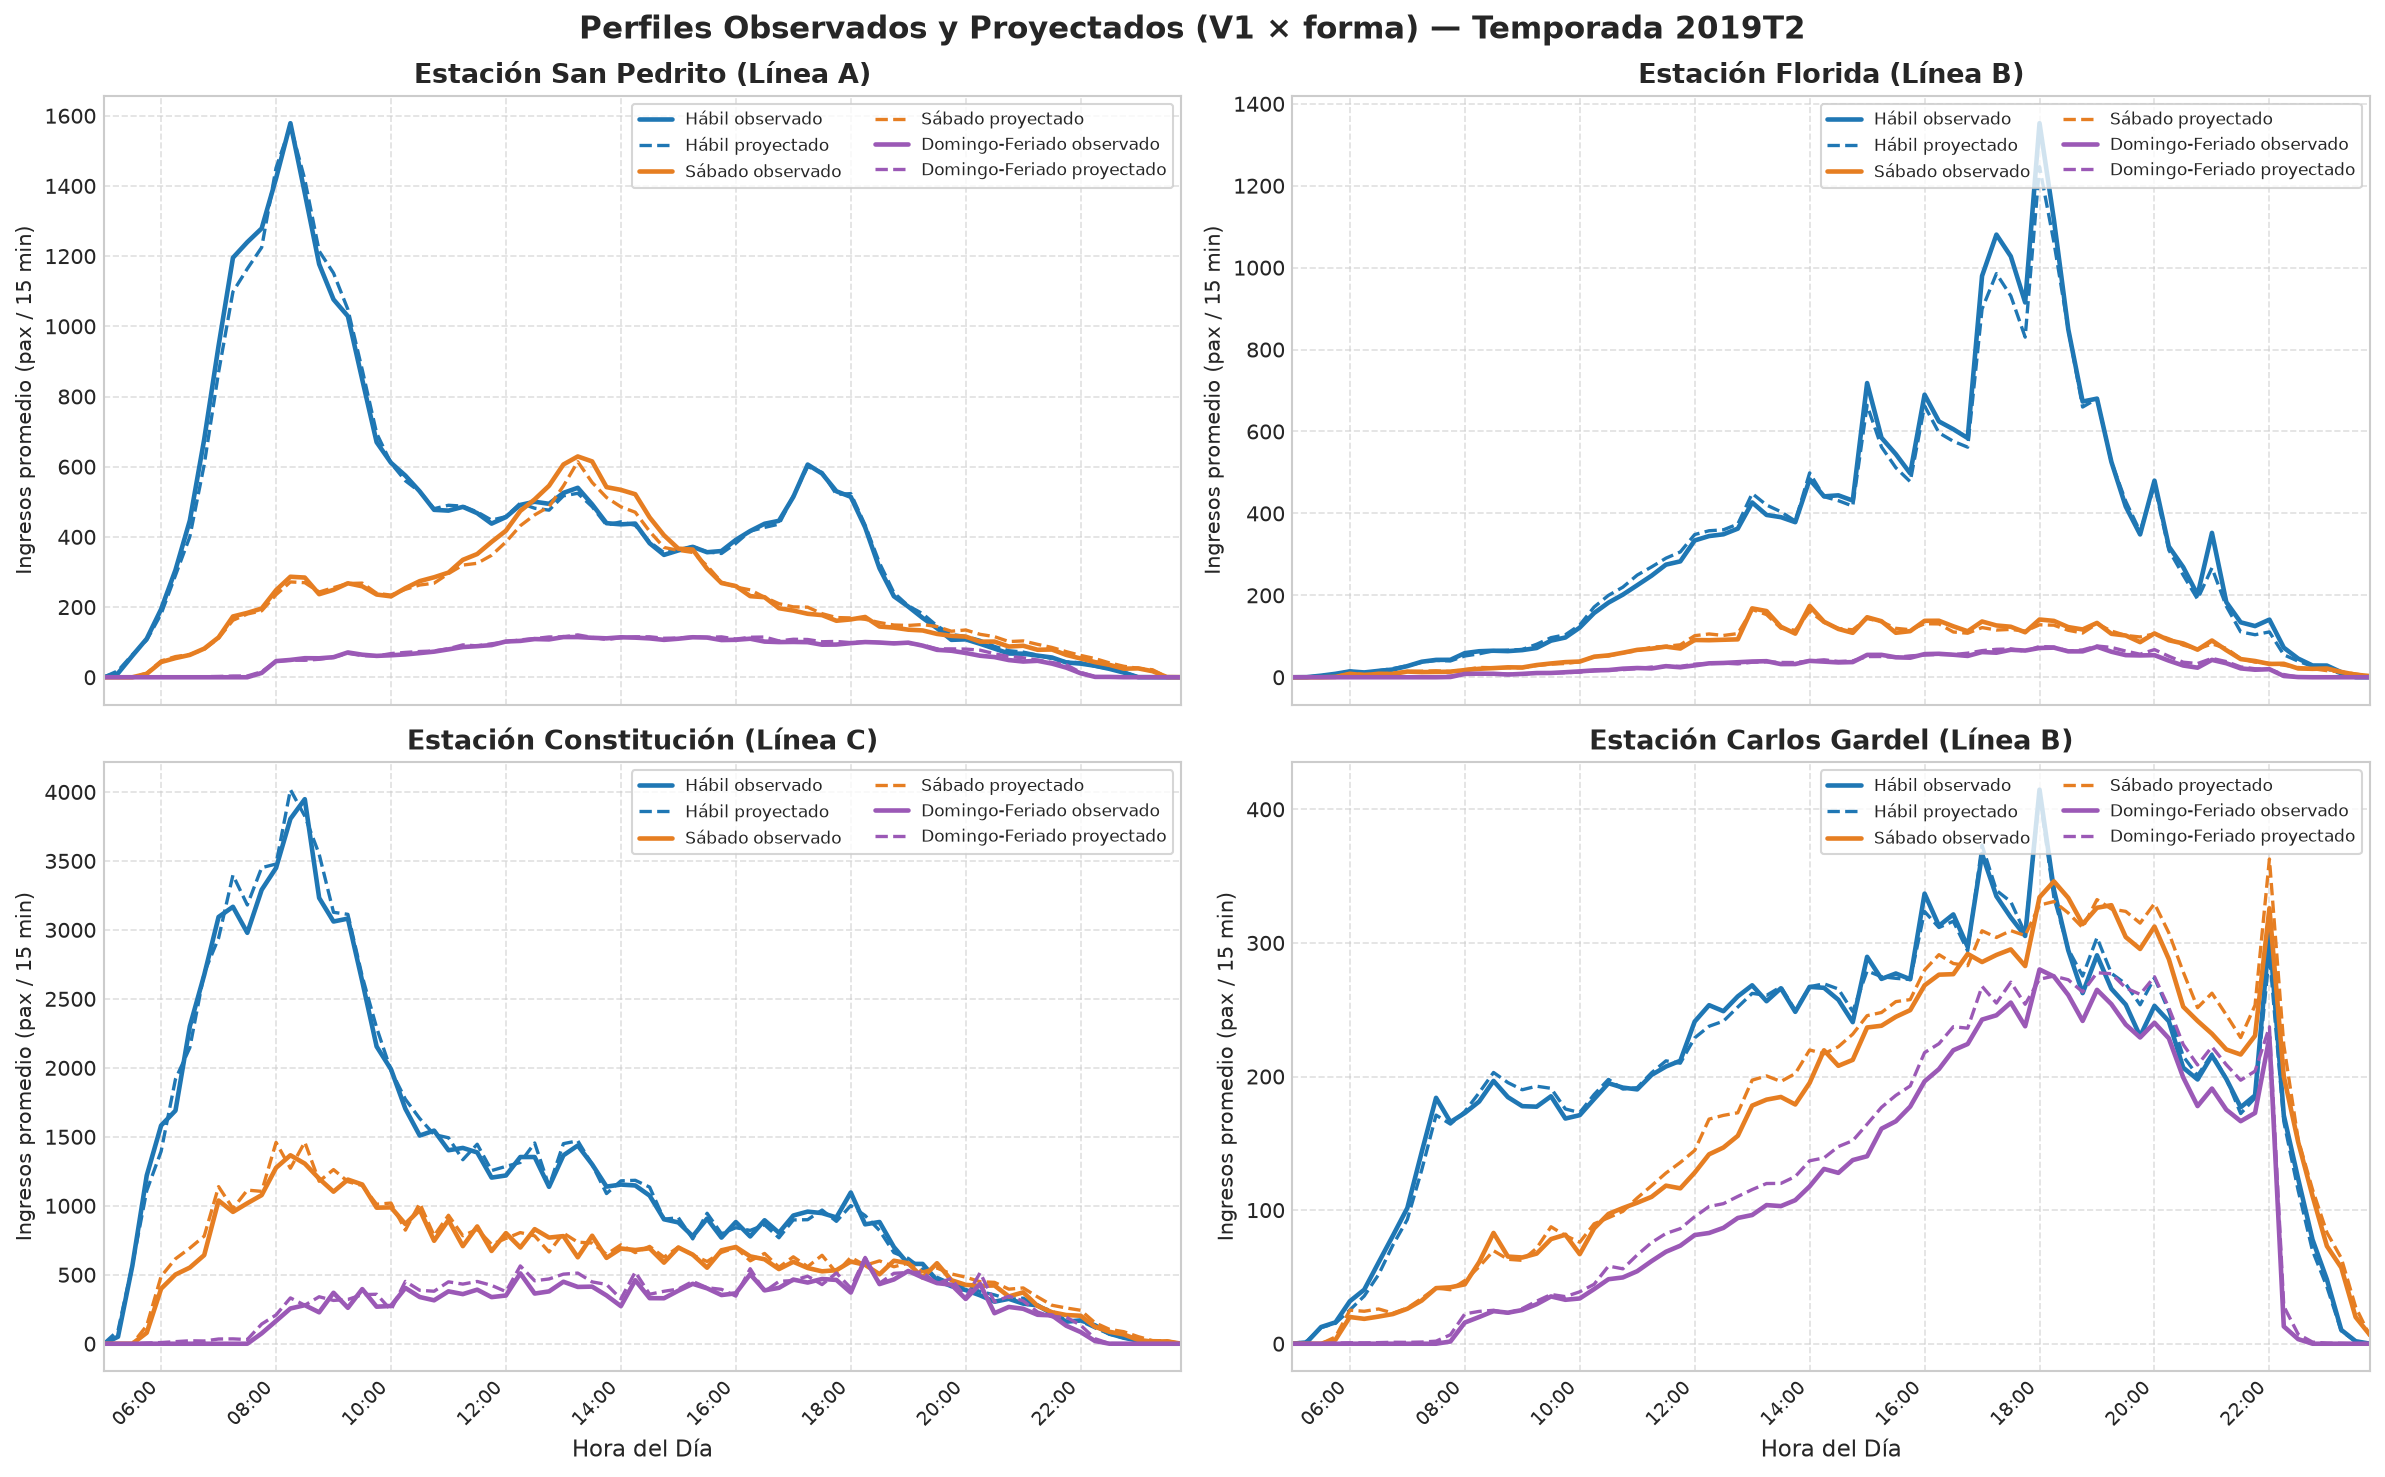

In [34]:
# Perfiles observados frente a proyectados (modelo adoptado), una temporada, estaciones representativas
Q_FIG = 21
sub = PROY[PROY['qidx'] == Q_FIG]
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
for ax, est in zip(axes.flatten(), ESTACIONES_REPRESENTATIVAS):
    s = sub[sub['estacion'] == est].groupby(['tipo_dia', 'win'])[['y', MODELO_ADOPTADO]].mean()
    for t in TIPOS_DIA:
        ax.plot(horas, s.loc[t, 'y'], color=TIPO_COLORS[t], linewidth=2.2, label=f'{t} observado')
        ax.plot(horas, s.loc[t, MODELO_ADOPTADO], color=TIPO_COLORS[t], linewidth=1.6, linestyle='--', label=f'{t} proyectado')
    ax.set_title(f'Estación {est} ({linea_de[est]})', fontsize=13, fontweight='bold')
    ax.set_ylabel('Ingresos promedio (pax / 15 min)', fontsize=10)
    ax.set_xlim(5.0, 23.75)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper right', frameon=True, fontsize=8, ncol=2)
for ax in axes[1]:
    ax.set_xlabel('Hora del Día', fontsize=11)
    ax.set_xticks(np.arange(6, 24, 2))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(6, 24, 2)], rotation=45, ha='right', fontsize=9)
plt.suptitle(f'Perfiles Observados y Proyectados ({MODELOS[MODELO_ADOPTADO]}) — Temporada {nombre_trim(Q_FIG)}', fontsize=15, fontweight='bold')
plt.tight_layout()
guardar_figura('09_perfiles_observados_vs_proyectados.png')

Gráfico guardado: output/graficos/10_sesgo_volumen_por_temporada.png


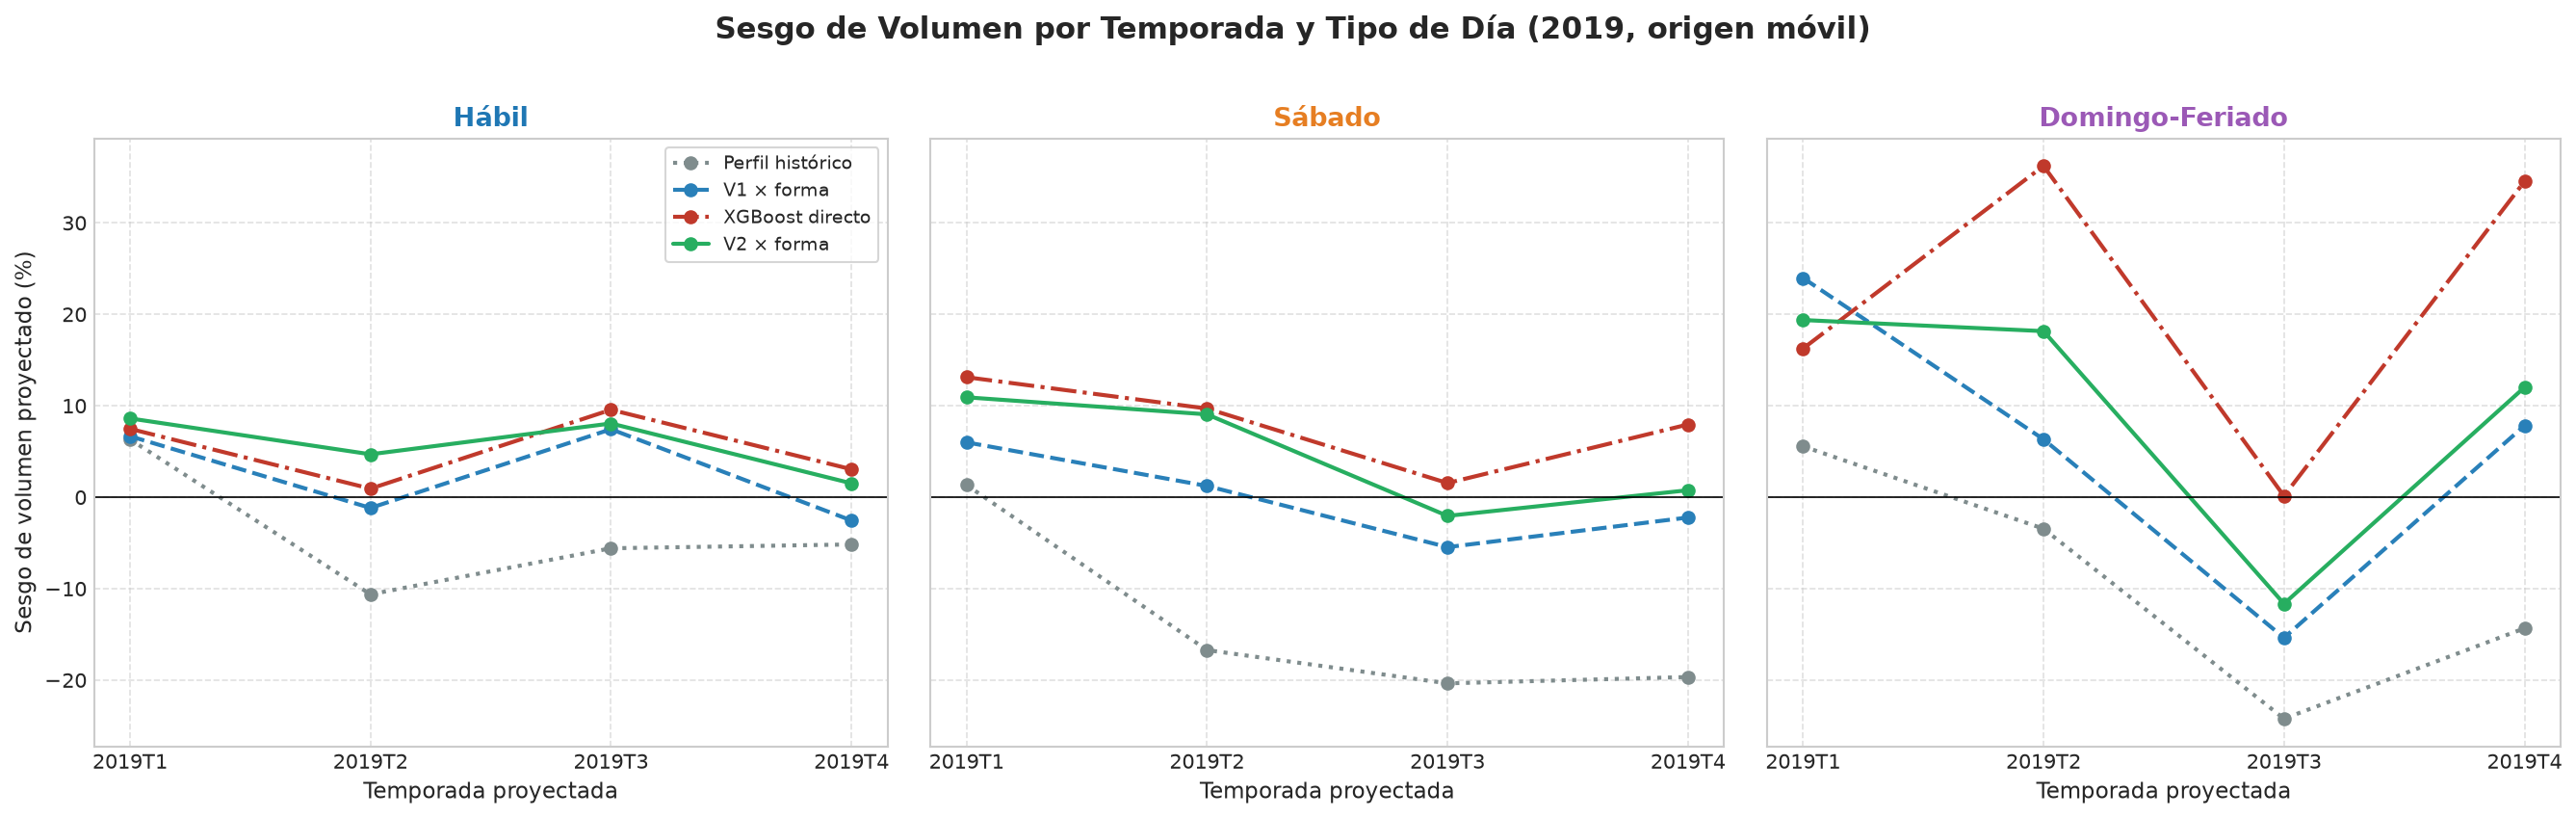

In [35]:
# Sesgo de volumen por temporada y tipo de día, para cada modelo
sesgo = DIA.groupby(['qidx', 'tipo'])[['y', *MODELOS]].sum()
sesgo = (sesgo[list(MODELOS)].div(sesgo['y'], axis=0) - 1) * 100
estilos_mod = {'perfil_historico': ('#7f8c8d', ':'), 'v1_forma': ('#2980b9', '--'),
               'xgb_directo': ('#c0392b', '-.'), 'v2_forma': ('#27ae60', '-')}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, t in zip(axes, TIPOS_DIA):
    s = sesgo.xs(TIPO_IDX[t], level='tipo')
    for c, nombre in MODELOS.items():
        color, ls = estilos_mod[c]
        ax.plot([nombre_trim(q) for q in s.index], s[c], marker='o', color=color, linestyle=ls, linewidth=2, label=nombre)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(t, fontsize=13, fontweight='bold', color=TIPO_COLORS[t])
    ax.set_xlabel('Temporada proyectada', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
axes[0].set_ylabel('Sesgo de volumen proyectado (%)', fontsize=11)
axes[0].legend(loc='best', frameon=True, fontsize=9)
plt.suptitle('Sesgo de Volumen por Temporada y Tipo de Día (2019, origen móvil)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
guardar_figura('10_sesgo_volumen_por_temporada.png', bbox_inches='tight')

### 7.4. Frecuencia Mínima Requerida y Estaciones Determinantes
La frecuencia se fija para la línea completa, y debe alcanzar para la estación de mayor demanda (DM-05). Para cada línea $l$, tipo de día $d$ y ventana $t$:
$$f_{\text{req}}(l, d, t) = \max_{s \in l} \frac{B(s, d, t)}{C_l \cdot \varphi}$$
donde $B$ son los ingresos proyectados por el modelo adoptado (promedio de las cuatro temporadas de 2019), $C_l$ la capacidad por formación de la línea y $\varphi$ la ocupación objetivo. La estación que impone el máximo es la **estación determinante**. Para que la lectura no dependa de empates entre estaciones de demanda casi igual en ventanas sucesivas, la estación determinante se identifica por **franjas de una hora** (ingresos proyectados sumados en las cuatro ventanas de cada hora), la unidad con que suelen fijarse los intervalos de servicio; las horas sin demanda proyectada (menos de 1 pasajero) se marcan como tales. Como $C_l$ y $\varphi$ son constantes dentro de cada línea, las estaciones determinantes no dependen de la capacidad: ésta sólo convierte la demanda a absorber en trenes por ventana.

*Limitación:* los ingresos no se desagregan por sentido y la carga a bordo es desconocida (no hay registros de egreso), por lo que la frecuencia requerida es un indicador del orden de magnitud, exacto sólo en las cabeceras, donde el tren parte vacío y todos los ingresos abordan en un sentido.

*Capacidad:* la capacidad útil por formación de la flota actual está pendiente de relevamiento. Mientras no se cargue, la figura expresa la frecuencia requerida como la demanda que debe absorber la línea (ingresos por 15 minutos de la estación determinante).

In [36]:
# Capacidad útil por formación (capacidad × ocupación objetivo) de la flota actual, en pasajeros (DM-05).
# Pendiente de relevamiento: con None, la frecuencia se expresa como demanda a absorber (pax / hora).
CAPACIDAD_UTIL = {'Línea A': None, 'Línea B': None, 'Línea C': None}
CABECERAS = {'Plaza de Mayo', 'San Pedrito', 'Leandro N. Alem', 'Juan Manuel de Rosas', 'Retiro', 'Constitución'}
HORAS_SERVICIO = range(5, 24)                                # franjas de 05:00 a 23:59

# Ingresos proyectados por hora: promedio por ventana de las temporadas de 2019, sumado en las 4 ventanas de cada hora
demanda_hora = (PROY.assign(linea=PROY['estacion'].map(linea_de), hora=horas[PROY['win']].astype(int))
                .groupby(['linea', 'tipo_dia', 'estacion', 'win', 'hora'])[MODELO_ADOPTADO].mean()
                .groupby(['linea', 'tipo_dia', 'hora', 'estacion']).sum()
                .unstack('estacion'))
frecuencia = pd.DataFrame({'determinante': demanda_hora.idxmax(axis=1), 'demanda': demanda_hora.max(axis=1)}).reset_index()
frecuencia = frecuencia[frecuencia['hora'].isin(HORAS_SERVICIO)]
frecuencia.loc[frecuencia['demanda'] < 1, 'determinante'] = 'Sin demanda'
frecuencia['trenes_por_hora'] = [d / CAPACIDAD_UTIL[l] if CAPACIDAD_UTIL[l] else np.nan
                                 for l, d in zip(frecuencia['linea'], frecuencia['demanda'])]


def tramos(sub):
    # Agrupa horas consecutivas con la misma estación determinante.
    sub = sub.sort_values('hora')
    corte = (sub['determinante'] != sub['determinante'].shift()).cumsum()
    for _, g in sub.groupby(corte):
        yield g['determinante'].iloc[0], g['hora'].iloc[0], g['hora'].iloc[-1] + 1, g['demanda'].max(), len(g)


filas = []
for (l, t), sub in frecuencia.groupby(['linea', 'tipo_dia']):
    for est, desde, hasta, dmax, n in tramos(sub):
        filas.append({'linea': l, 'tipo_dia': t, 'estacion': est, 'tramo': f"{desde:02d}–{hasta:02d} h", 'dmax': dmax, 'horas': n})
tramos_df = pd.DataFrame(filas)

orden_tipo = {t: k for k, t in enumerate(TIPOS_DIA)}
md_f = "# Estaciones Determinantes de la Frecuencia Requerida por Línea y Tipo de Día\n\n"
md_f += (f"Proyección del modelo adoptado ({MODELOS[MODELO_ADOPTADO]}), promedio de las cuatro temporadas de 2019, "
         "franjas de una hora entre las 05:00 y las 24:00. En cada franja, la estación determinante es la de mayor demanda "
         "proyectada de la línea. En las cabeceras la frecuencia requerida es exacta; en el resto es un indicador del orden "
         "de magnitud (ingresos no desagregados por sentido, carga a bordo desconocida).\n\n")
md_f += "| Línea | Tipo de día | Estación determinante | Cabecera | Horarios | Horas (de 19) | Demanda máxima proyectada (pax/hora) |\n"
md_f += "| :--- | :--- | :--- | :---: | :--- | :---: | :---: |\n"
resumen_det = (tramos_df.groupby(['linea', 'tipo_dia', 'estacion'])
               .agg(tramos=('tramo', ', '.join), horas=('horas', 'sum'), dmax=('dmax', 'max')).reset_index())
resumen_det['sin_demanda'] = resumen_det['estacion'] == 'Sin demanda'
resumen_det = resumen_det.sort_values(['linea', 'tipo_dia', 'sin_demanda', 'horas'],
                                      key=lambda s: s.map(orden_tipo) if s.name == 'tipo_dia' else s,
                                      ascending=[True, True, True, False])
for _, r in resumen_det.iterrows():
    cab = '—' if r['sin_demanda'] else ('Sí' if r['estacion'] in CABECERAS else 'No')
    dm = '—' if r['sin_demanda'] else f"{r['dmax']:,.0f}"
    md_f += f"| {r['linea']} | {r['tipo_dia']} | {r['estacion']} | {cab} | {r['tramos']} | {r['horas']} | {dm} |\n"
guardar_tabla('10_estaciones_determinantes.md', md_f)

Tabla guardada: output/tablas/10_estaciones_determinantes.md


# Estaciones Determinantes de la Frecuencia Requerida por Línea y Tipo de Día

Proyección del modelo adoptado (V1 × forma), promedio de las cuatro temporadas de 2019, franjas de una hora entre las 05:00 y las 24:00. En cada franja, la estación determinante es la de mayor demanda proyectada de la línea. En las cabeceras la frecuencia requerida es exacta; en el resto es un indicador del orden de magnitud (ingresos no desagregados por sentido, carga a bordo desconocida).

| Línea | Tipo de día | Estación determinante | Cabecera | Horarios | Horas (de 19) | Demanda máxima proyectada (pax/hora) |
| :--- | :--- | :--- | :---: | :--- | :---: | :---: |
| Línea A | Hábil | San Pedrito | Sí | 05–15 h | 10 | 5,359 |
| Línea A | Hábil | Perú | No | 15–22 h | 7 | 3,296 |
| Línea A | Hábil | Congreso | No | 22–24 h | 2 | 279 |
| Línea A | Sábado | San Pedrito | Sí | 05–19 h, 21–22 h | 15 | 2,106 |
| Línea A | Sábado | Acoyte | No | 19–21 h, 22–23 h | 3 | 555 |
| Línea A | Sábado | Congreso | No | 23–24 h | 1 | 73 |
| Línea A | Domingo-Feriado | San Pedrito | Sí | 06–22 h | 16 | 534 |
| Línea A | Domingo-Feriado | Congreso | No | 22–23 h | 1 | 56 |
| Línea A | Domingo-Feriado | Sin demanda | — | 05–06 h, 23–24 h | 2 | — |
| Línea B | Hábil | Federico Lacroze | No | 05–07 h, 08–15 h | 9 | 5,825 |
| Línea B | Hábil | Leandro N. Alem | Sí | 16–20 h | 4 | 4,719 |
| Línea B | Hábil | Carlos Pellegrini | No | 20–22 h, 23–24 h | 3 | 1,274 |
| Línea B | Hábil | Carlos Gardel | No | 22–23 h | 1 | 647 |
| Línea B | Hábil | Florida | No | 15–16 h | 1 | 2,199 |
| Línea B | Hábil | Juan Manuel de Rosas | Sí | 07–08 h | 1 | 4,297 |
| Línea B | Sábado | Federico Lacroze | No | 05–15 h | 10 | 1,348 |
| Línea B | Sábado | Carlos Gardel | No | 15–23 h | 8 | 1,192 |
| Línea B | Sábado | Carlos Pellegrini | No | 23–24 h | 1 | 243 |
| Línea B | Domingo-Feriado | Federico Lacroze | No | 05–15 h | 10 | 614 |
| Línea B | Domingo-Feriado | Carlos Gardel | No | 15–23 h | 8 | 1,020 |
| Línea B | Domingo-Feriado | Sin demanda | — | 23–24 h | 1 | — |
| Línea C | Hábil | Constitución | Sí | 05–17 h, 20–22 h | 14 | 14,197 |
| Línea C | Hábil | Retiro | Sí | 17–20 h, 22–24 h | 5 | 3,763 |
| Línea C | Sábado | Constitución | Sí | 05–24 h | 19 | 5,142 |
| Línea C | Domingo-Feriado | Constitución | Sí | 05–23 h | 18 | 2,110 |
| Línea C | Domingo-Feriado | Sin demanda | — | 23–24 h | 1 | — |


Gráfico guardado: output/graficos/11_frecuencia_requerida_por_linea.png


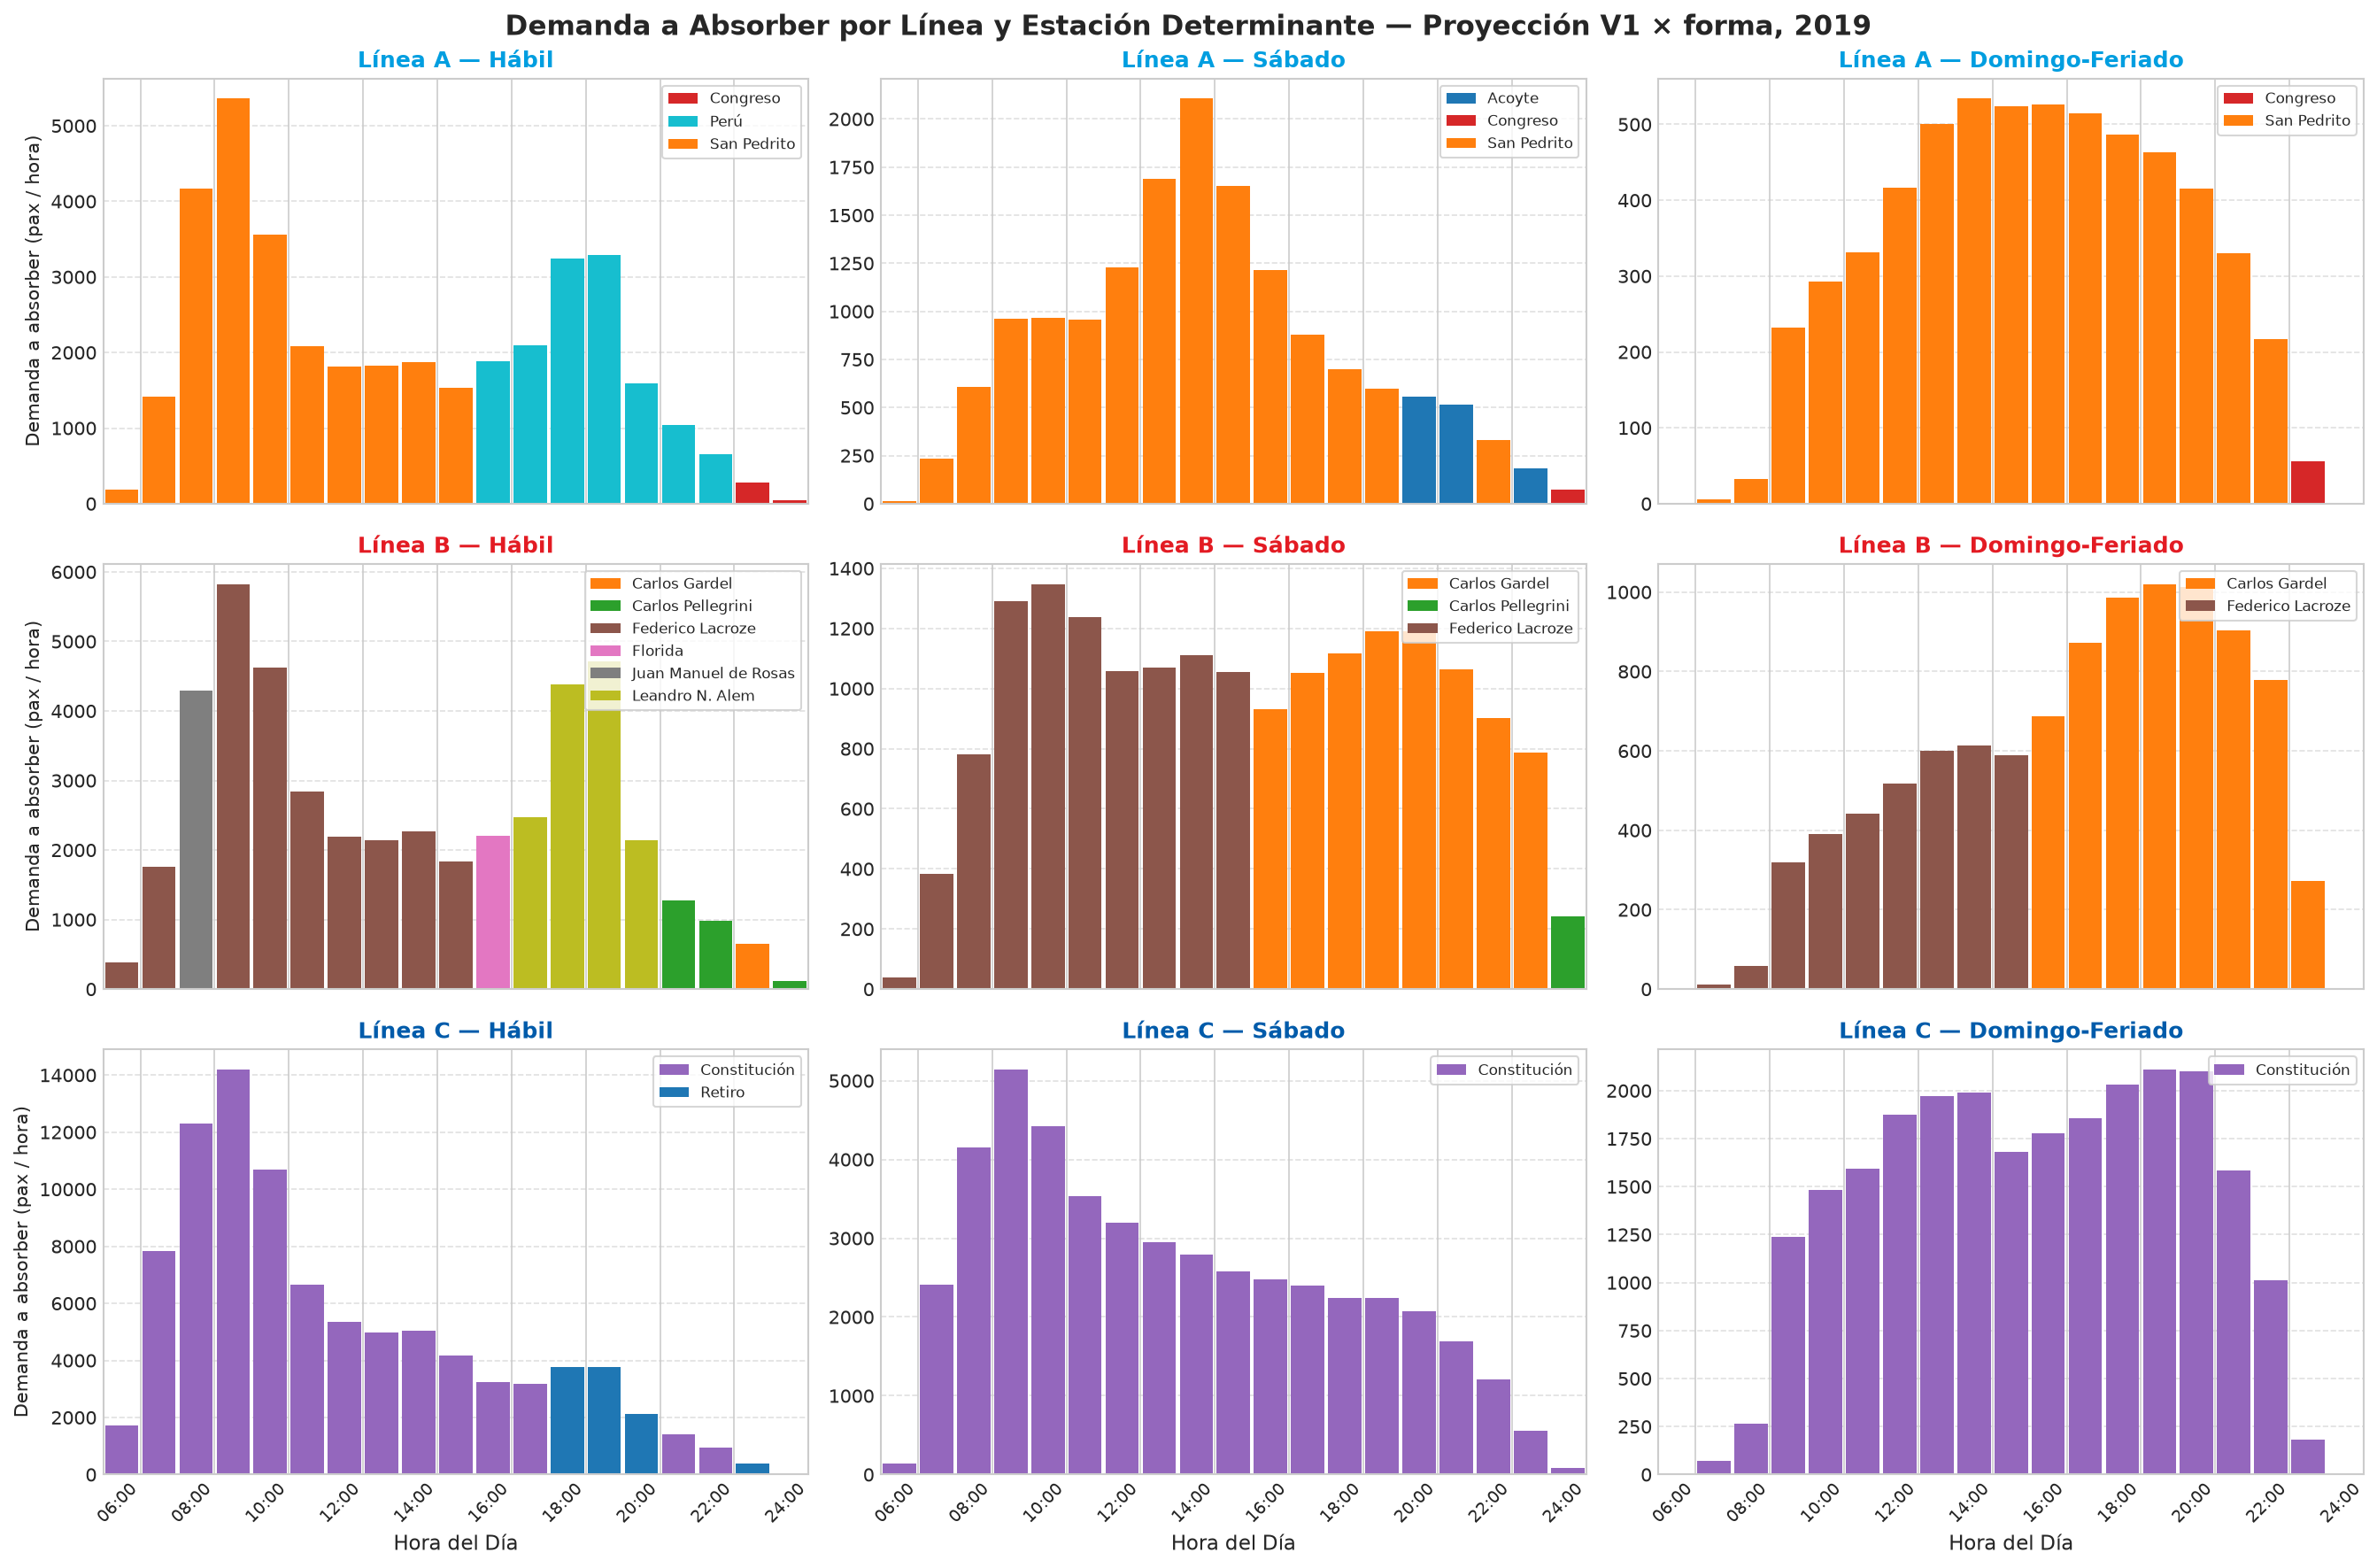

In [37]:
usar_trenes = all(CAPACIDAD_UTIL.values())
lineas = sorted(frecuencia['linea'].unique())
estaciones_det = sorted(e for e in frecuencia['determinante'].unique() if e != 'Sin demanda')
paleta_det = dict(zip(estaciones_det, sns.color_palette('tab10', len(estaciones_det))))

fig, axes = plt.subplots(len(lineas), len(TIPOS_DIA), figsize=(18, 12), sharex=True)
for i, l in enumerate(lineas):
    for j, t in enumerate(TIPOS_DIA):
        ax = axes[i, j]
        sub = frecuencia[(frecuencia['linea'] == l) & (frecuencia['tipo_dia'] == t)].sort_values('hora')
        y = sub['trenes_por_hora'] if usar_trenes else sub['demanda']
        colores = [paleta_det.get(e, '#d0d3d4') for e in sub['determinante']]
        ax.bar(sub['hora'] + 0.5, y, width=0.9, color=colores)
        for est in [e for e in estaciones_det if e in set(sub['determinante'])]:
            ax.bar(np.nan, np.nan, color=paleta_det[est], label=est)
        ax.set_title(f'{l} — {t}', fontsize=12, fontweight='bold', color=line_colors[l])
        ax.set_xlim(5, 24)
        ax.grid(True, axis='y', linestyle='--', alpha=0.6)
        ax.legend(loc='upper right', fontsize=8, frameon=True)
        if j == 0:
            ax.set_ylabel('Trenes por hora' if usar_trenes else 'Demanda a absorber (pax / hora)', fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel('Hora del Día', fontsize=11)
    ax.set_xticks(np.arange(6, 25, 2))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(6, 25, 2)], rotation=45, ha='right', fontsize=9)
titulo = 'Frecuencia Mínima Requerida' if usar_trenes else 'Demanda a Absorber por Línea y Estación Determinante'
plt.suptitle(f'{titulo} — Proyección {MODELOS[MODELO_ADOPTADO]}, 2019', fontsize=15, fontweight='bold')
plt.tight_layout()
guardar_figura('11_frecuencia_requerida_por_linea.png')

## 8. Conclusiones y Resumen para Metodología
Las cifras corresponden a días con servicio (se excluyen 360 días-estación sin ingresos; la retención de red cambia menos de 0,4 pp según ese tratamiento, sección 2.7).

1. **La distribución horaria difiere en todas las estaciones, con magnitud muy variable:** la distancia de variación total respecto de los días hábiles tiene una mediana de 0,169 para los sábados (rango 0,085–0,313) y de 0,186 para los domingos y feriados (rango 0,075–0,413), con p ajustado por Holm ≤ 0,0044 (el mínimo alcanzable con 10.000 permutaciones) en las 44 estaciones y ambas comparaciones. Las mayores diferencias se dan en cabeceras residenciales y de transbordo (Echeverría, Juan Manuel de Rosas, Constitución y San Pedrito superan 0,40 en domingos y feriados), donde la demanda se desplaza de la mañana hacia la tarde; las menores en domingos y feriados, en Alberti, Pasteur y Callao. En la mayoría de las estaciones del Microcentro (Florida, Plaza de Mayo, Piedras, Perú) la diferencia es mayor los sábados que los domingos y feriados: ambos tipos de día pierden el pico vespertino de regreso, pero los sábados concentran además la demanda cerca del mediodía.
2. **Asimetría territorial en el volumen:** la red retiene el 38,59% de la demanda hábil los sábados (IC 95%: 37,47–39,72) y el 19,80% los domingos y feriados (19,20–20,37). El promedio enmascara brechas extremas entre el Microcentro (en domingos y feriados, Diagonal Norte retiene el 9,18% y Florida el 9,22%; los sábados, Plaza de Mayo el 18,47% y Diagonal Norte el 18,76%) y los polos recreativos o de transbordo (Carlos Gardel retiene el 72,19% los sábados y el 55,53% los domingos y feriados). Constitución mantiene el mayor volumen absoluto: 37.298 pax/día los sábados y 17.851 los domingos y feriados.
3. **Tres regímenes de demanda:** sábados y domingos-feriados difieren entre sí tanto como cada uno respecto de los días hábiles (TV mediana Sábado – Domingo-Feriado de 0,165). En cambio, domingos y feriados son muy similares: TV mediana de 0,049 (rango 0,022–0,085), sin diferencia significativa en 5 estaciones, y niveles de retención comparables (18,96% y 22,21%). Esto respalda la clasificación en Hábil, Sábado y Domingo-Feriado (DM-03).
4. **Modelo de planificación por temporada:** al proyectar cada trimestre de 2019 con los datos anteriores a su inicio, el modelo estacional **V1 × forma** reproduce la forma de los perfiles (TV mediana 0,018), la retención por estación (error medio de 1,23 pp en sábados y 0,69 pp en domingos y feriados) y el volumen medio (error de 3,8%, sesgo de +2,4%). El XGBoost con separación volumen × forma mejora la precisión por ventana (RMSE 59,1 frente a 61,7) y la variación entre días, pero sobreestima el nivel de 2019 en 5,7%; el XGBoost directo sobre ingresos por ventana sobreestima los domingos y feriados en 21%. Conforme al criterio fijado antes de la evaluación (DM-06), se adopta V1 × forma: con una temporada de antelación, el aprendizaje automático no supera a la estructura estacional en lo que determina la frecuencia, y la incertidumbre se concentra en el nivel, especialmente en domingos y feriados.
5. **Frecuencia requerida y estaciones determinantes:** con las proyecciones del modelo adoptado, la frecuencia de cada línea la determinan pocas estaciones. En la Línea C, Constitución durante casi todo el día en los tres tipos de día (Retiro, en el regreso vespertino hábil); en la Línea A, San Pedrito (Perú, en la tarde hábil); en la Línea B, Federico Lacroze por la mañana y, por la tarde, Leandro N. Alem en días hábiles y Carlos Gardel los sábados, domingos y feriados. En la hora de mayor exigencia, la frecuencia requerida los sábados es del 23% al 39% de la del pico hábil según la línea, y del 10% al 18% los domingos y feriados. *Los valores absolutos de frecuencia quedan pendientes de la capacidad de las formaciones.*

La síntesis interpretativa extendida para la entrega escrita se encuentra en `output/resumen_metodologia.md`.